## 1. Hospital contact data and interpolation


In [14]:

from pathlib import Path

_CWD = Path.cwd().resolve()
PROJECT_ROOT = _CWD
for _candidate in (_CWD, *_CWD.parents):
    if (_candidate / "notebooks").is_dir() and (_candidate / "README.md").exists():
        PROJECT_ROOT = _candidate
        break
else:
    if _CWD.name == "notebooks":
        PROJECT_ROOT = _CWD.parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

FIGURE_DIR = PROJECT_ROOT / "figures"
FIG_CONTACT = FIGURE_DIR / "contact_network"
FIG_EPIDEMIC = FIGURE_DIR / "epidemic_dynamics"
FIG_R0 = FIGURE_DIR / "reproduction_number"
FIG_SENSITIVITY = FIGURE_DIR / "sensitivity_analysis"
FIG_INTERVENTION = FIGURE_DIR / "intervention_analysis"
FIG_COMPARISON = FIGURE_DIR / "comparisons"

RESULT_DIR = PROJECT_ROOT / "results"
RESULT_CSV = RESULT_DIR / "csv"
RESULT_NUMPY = RESULT_DIR / "numpy"
RESULT_TEXT = RESULT_DIR / "text"

CSV_CONTACT = RESULT_CSV / "contact_network"
CSV_TIMING = RESULT_CSV / "intervention_timing"
CSV_ROLES = RESULT_CSV / "intervention_roles"
CSV_COMPARISON = RESULT_CSV / "comparisons"

for _directory in [
    DATA_RAW_DIR, DATA_PROCESSED_DIR,
    FIG_CONTACT, FIG_EPIDEMIC, FIG_R0, FIG_SENSITIVITY,
    FIG_INTERVENTION, FIG_COMPARISON,
    CSV_CONTACT, CSV_TIMING, CSV_ROLES, CSV_COMPARISON,
    RESULT_NUMPY, RESULT_TEXT
]:
    _directory.mkdir(parents=True, exist_ok=True)

print(f"Project output root: {PROJECT_ROOT}")


Project output root: /home/awanish_pathak/awanishpathak/Awanish Pathak/NLD WORK/Network Science/Multilayer Multistrain/GIT/NatCom-Computational-Codes/Notebooks/Lyon_Hospital


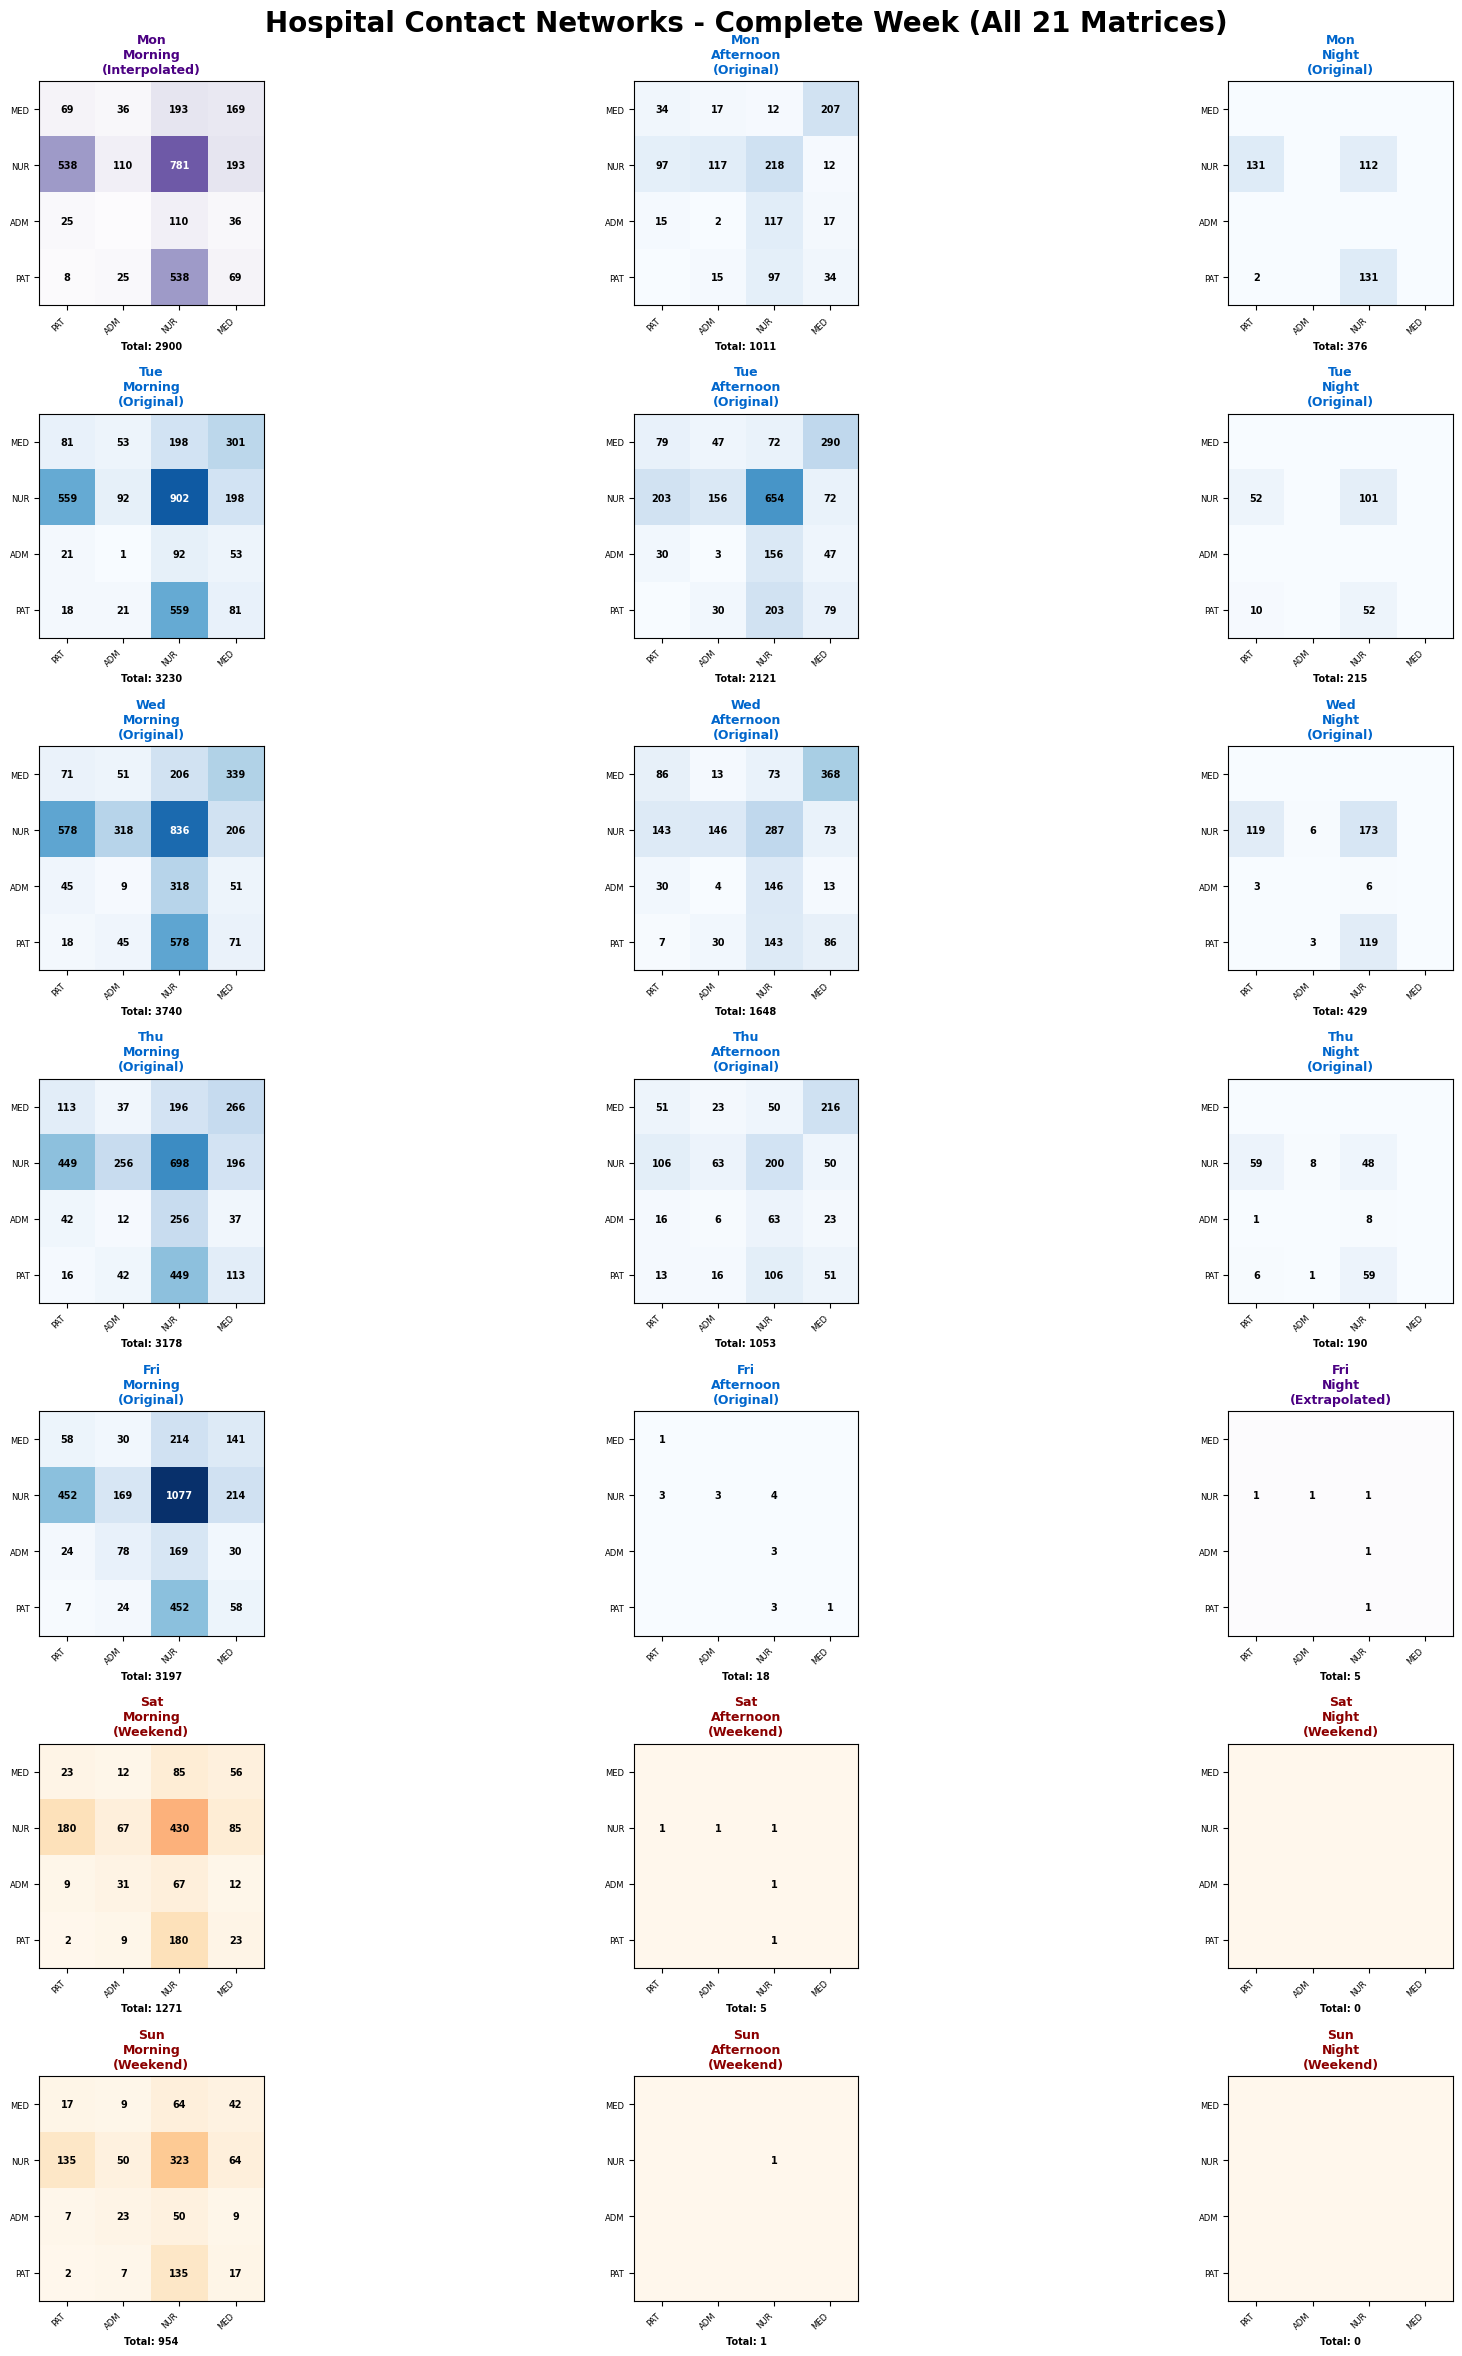

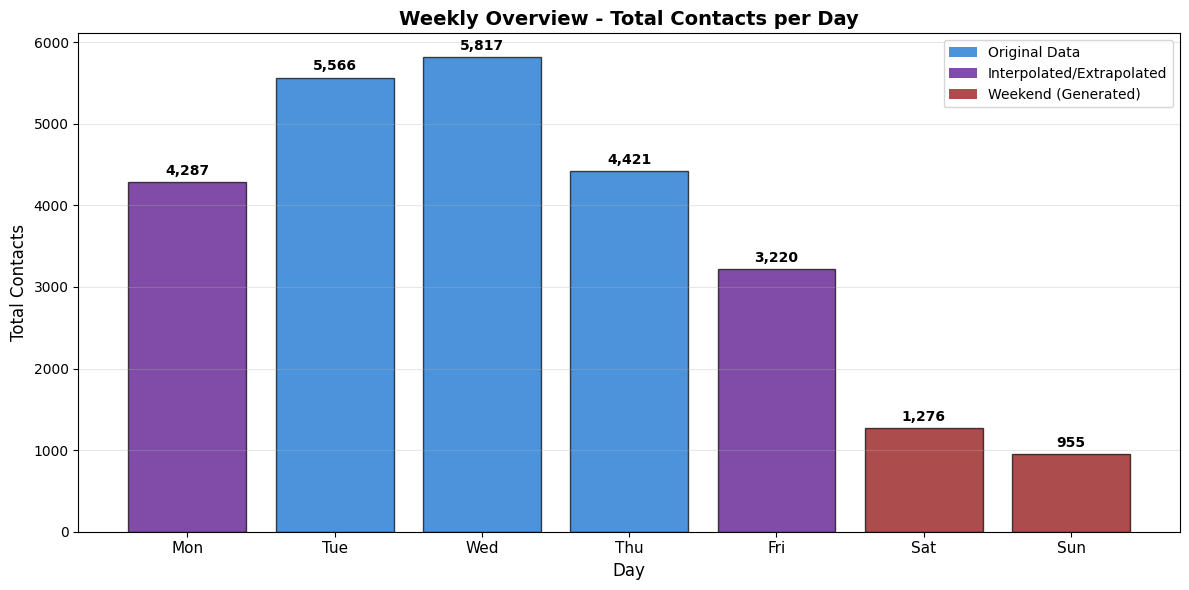

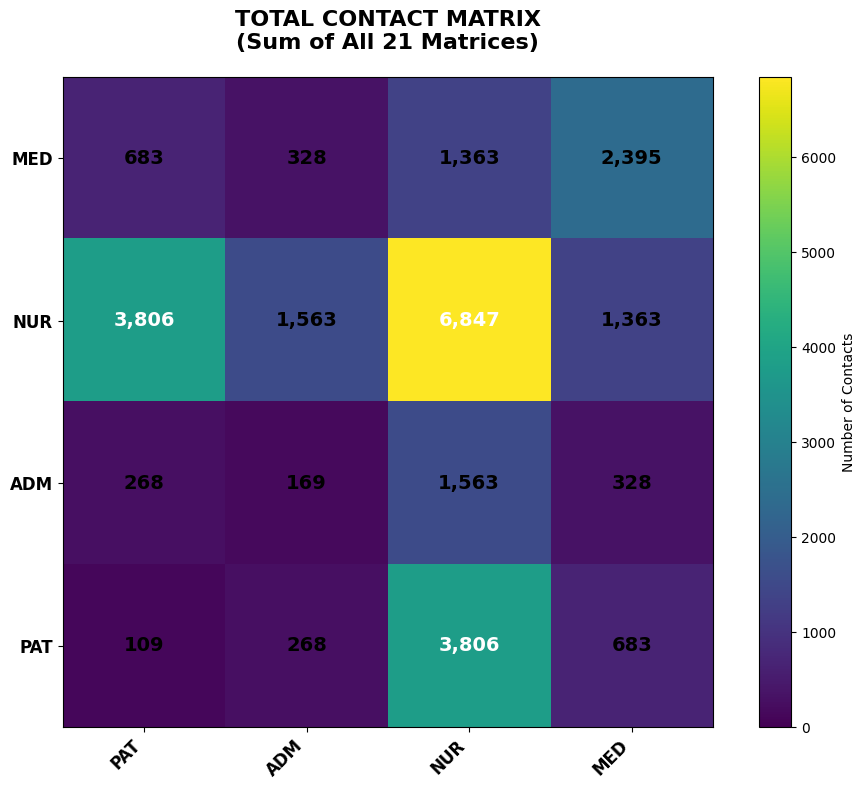


TOTAL CONTACT MATRIX - SUM OF ALL 21 MATRICES

Matrix (rows = From, columns = To):
--------------------------------------------------
                   PAT         ADM         NUR         MED
 ----------------------------------------------------------
MED      |         683         328       1,363       2,395  |        4,769 (Total From MED)
NUR      |       3,806       1,563       6,847       1,363  |       13,579 (Total From NUR)
ADM      |         268         169       1,563         328  |        2,328 (Total From ADM)
PAT      |         109         268       3,806         683  |        4,866 (Total From PAT)
 ----------------------------------------------------------
To Total |       4,866       2,328      13,579       4,769

GRAND TOTAL (all contacts): 25,542

CONTACTS BY ROLE

Contacts MADE by each role:
  MED: 4,769 contacts
  NUR: 13,579 contacts
  ADM: 2,328 contacts
  PAT: 4,866 contacts

Contacts RECEIVED by each role:
  PAT: 4,866 contacts
  ADM: 2,328 contacts
  NUR: 13,

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


# X-axis (columns): [PAT, ADM, NUR, MED]
# Y-axis (rows): [MED, NUR, ADM, PAT]
x_order = ["PAT", "ADM", "NUR", "MED"]
y_order = ["MED", "NUR", "ADM", "PAT"]
R = 4

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
shifts = ["Morning", "Afternoon", "Night"]

D = len(days)
S = len(shifts)

# Initialize with NaN
C = np.full((D, S, R, R), np.nan)

# ===========================================
# ORIGINAL MATRICES (as provided)
# ===========================================

# MONDAY
# -----
# Monday AFTERNOON
C[0, 1] = np.array([
    [34, 17, 12, 207],   # MED row: to PAT, ADM, NUR, MED
    [97, 117, 218, 12],  # NUR row: to PAT, ADM, NUR, MED
    [15, 2, 117, 17],    # ADM row: to PAT, ADM, NUR, MED
    [0, 15, 97, 34]      # PAT row: to PAT, ADM, NUR, MED
])

# Monday NIGHT
C[0, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [131, 0, 112, 0],    # NUR row
    [0, 0, 0, 0],        # ADM row
    [2, 0, 131, 0]       # PAT row
])

# Monday MORNING is NaN (to be interpolated)

# TUESDAY
# -------
# Tuesday MORNING
C[1, 0] = np.array([
    [81, 53, 198, 301],  # MED row
    [559, 92, 902, 198], # NUR row
    [21, 1, 92, 53],     # ADM row
    [18, 21, 559, 81]    # PAT row
])

# Tuesday AFTERNOON
C[1, 1] = np.array([
    [79, 47, 72, 290],   # MED row
    [203, 156, 654, 72], # NUR row
    [30, 3, 156, 47],    # ADM row
    [0, 30, 203, 79]     # PAT row
])

# Tuesday NIGHT
C[1, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [52, 0, 101, 0],     # NUR row
    [0, 0, 0, 0],        # ADM row
    [10, 0, 52, 0]       # PAT row
])

# WEDNESDAY
# ---------
# Wednesday MORNING
C[2, 0] = np.array([
    [71, 51, 206, 339],  # MED row
    [578, 318, 836, 206], # NUR row
    [45, 9, 318, 51],    # ADM row
    [18, 45, 578, 71]    # PAT row
])

# Wednesday AFTERNOON
C[2, 1] = np.array([
    [86, 13, 73, 368],   # MED row
    [143, 146, 287, 73], # NUR row
    [30, 4, 146, 13],    # ADM row
    [7, 30, 143, 86]     # PAT row
])

# Wednesday NIGHT
C[2, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [119, 6, 173, 0],    # NUR row
    [3, 0, 6, 0],        # ADM row
    [0, 3, 119, 0]       # PAT row
])

# THURSDAY
# --------
# Thursday MORNING
C[3, 0] = np.array([
    [113, 37, 196, 266], # MED row
    [449, 256, 698, 196], # NUR row
    [42, 12, 256, 37],   # ADM row
    [16, 42, 449, 113]   # PAT row
])

# Thursday AFTERNOON
C[3, 1] = np.array([
    [51, 23, 50, 216],   # MED row
    [106, 63, 200, 50],  # NUR row
    [16, 6, 63, 23],     # ADM row
    [13, 16, 106, 51]    # PAT row
])

# Thursday NIGHT
C[3, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [59, 8, 48, 0],      # NUR row
    [1, 0, 8, 0],        # ADM row
    [6, 1, 59, 0]        # PAT row
])

# FRIDAY
# ------
# Friday MORNING
C[4, 0] = np.array([
    [58, 30, 214, 141],  # MED row
    [452, 169, 1077, 214], # NUR row
    [24, 78, 169, 30],   # ADM row
    [7, 24, 452, 58]     # PAT row
])

# Friday AFTERNOON
C[4, 1] = np.array([
    [1, 0, 0, 0],        # MED row
    [3, 3, 4, 0],        # NUR row
    [0, 0, 3, 0],        # ADM row
    [0, 0, 3, 1]         # PAT row
])

# Friday NIGHT is NaN (to be extrapolated)

# SATURDAY - all NaN (to be generated)
# SUNDAY - all NaN (to be generated)

# -----------------------------------
# CREATE A COPY FOR FINAL RESULTS
# -----------------------------------
C_final = np.copy(C).astype(float)

# -----------------------------------
# STEP 1: INTERPOLATE MONDAY MORNING (from Tue-Fri morning)
# -----------------------------------
def interpolate_monday_morning(tue, wed, thu, fri):
    """
    Interpolate Monday morning value for a single matrix element
    using Tue-Fri morning values
    """
    # Collect known values with their day indices
    days = []
    values = []
    
    if not np.isnan(tue):
        days.append(1)
        values.append(tue)
    if not np.isnan(wed):
        days.append(2)
        values.append(wed)
    if not np.isnan(thu):
        days.append(3)
        values.append(thu)
    if not np.isnan(fri):
        days.append(4)
        values.append(fri)
    
    # Case 1: No data available
    if len(values) == 0:
        return 0.0
    
    # Case 2: Only one data point
    elif len(values) == 1:
        # Monday is typically lighter, use 80% of the single value
        return values[0] * 0.8
    
    # Case 3: Two or more data points
    else:
        # Calculate trend
        if len(values) >= 3:
            # Use linear regression for better trend
            z = np.polyfit(days, values, 1)
            intercept = z[1]
            monday_val = intercept
        else:
            # Only two points - use linear interpolation
            f = interp1d(days, values, kind='linear', fill_value='extrapolate')
            monday_val = float(f(0))
        
        # Apply realistic constraints
        min_val = min(values)
        monday_val = max(min_val * 0.5, min(monday_val, min_val * 1.2))
        
        return max(0, monday_val)

# Extract Tuesday-Friday morning data
tue_morning = C_final[1, 0]
wed_morning = C_final[2, 0]
thu_morning = C_final[3, 0]
fri_morning = C_final[4, 0]

# Initialize Monday morning matrix
mon_morning = np.zeros((R, R))

# Interpolate each element for Monday morning only
for i in range(R):
    for j in range(R):
        tue_val = tue_morning[i, j]
        wed_val = wed_morning[i, j]
        thu_val = thu_morning[i, j]
        fri_val = fri_morning[i, j]
        
        mon_val = interpolate_monday_morning(tue_val, wed_val, thu_val, fri_val)
        mon_morning[i, j] = mon_val

# Store Monday morning
C_final[0, 0] = mon_morning

# -----------------------------------
# STEP 2: EXTRAPOLATE FRIDAY NIGHT FROM FRIDAY AFTERNOON
# -----------------------------------
FRIDAY_NIGHT_FACTOR = 0.4
fri_afternoon = C_final[4, 1]
fri_night = fri_afternoon * FRIDAY_NIGHT_FACTOR
C_final[4, 2] = fri_night

# -----------------------------------
# STEP 3: GENERATE WEEKEND MORNINGS FROM FRIDAY MORNING
# -----------------------------------
SAT_MORNING_FACTOR = 0.4
SUN_MORNING_FACTOR = 0.3

fri_morning = C_final[4, 0]
sat_morning = fri_morning * SAT_MORNING_FACTOR
sun_morning = fri_morning * SUN_MORNING_FACTOR
C_final[5, 0] = sat_morning
C_final[6, 0] = sun_morning

# -----------------------------------
# STEP 4: GENERATE WEEKEND AFTERNOON AND NIGHT FROM FRIDAY AFTERNOON/NIGHT
# -----------------------------------
SAT_AFTERNOON_FACTOR = 0.4
SAT_NIGHT_FACTOR = 0.4
SUN_AFTERNOON_FACTOR = 0.3
SUN_NIGHT_FACTOR = 0.3

fri_afternoon = C_final[4, 1]
fri_night = C_final[4, 2]

sat_afternoon = fri_afternoon * SAT_AFTERNOON_FACTOR
sat_night = fri_night * SAT_NIGHT_FACTOR
sun_afternoon = fri_afternoon * SUN_AFTERNOON_FACTOR
sun_night = fri_night * SUN_NIGHT_FACTOR

C_final[5, 1] = sat_afternoon
C_final[5, 2] = sat_night
C_final[6, 1] = sun_afternoon
C_final[6, 2] = sun_night

# -----------------------------------
# STEP 5: CONVERT TO INTEGER ARRAY - GREATEST INTEGER VALUE (FLOOR)
# -----------------------------------
C_final_int = np.zeros((D, S, R, R), dtype=int)

for d in range(D):
    for s in range(S):
        for i in range(R):
            for j in range(R):
                val = C_final[d, s, i, j]
                if np.isnan(val):
                    C_final_int[d, s, i, j] = 0
                else:
                    C_final_int[d, s, i, j] = int(np.floor(val))

# ===========================================
# CALCULATE TOTAL CONTACT MATRIX (SUM OVER ALL DAYS AND SHIFTS)
# ===========================================
total_matrix = np.zeros((R, R), dtype=int)

for d in range(D):
    for s in range(S):
        total_matrix += C_final_int[d, s]

# ===========================================
# PLOTTING
# ===========================================

# Set up plot style
plt.style.use('default')

# Color maps
cmap_original = 'Blues'
cmap_interpolated = 'Purples'
cmap_weekend = 'OrRd'

# -------------------------------------------------------------------
# PLOT 1: Master plot with all 21 matrices
# -------------------------------------------------------------------
fig = plt.figure(figsize=(20, 24))
fig.suptitle('Hospital Contact Networks - Complete Week (All 21 Matrices)', 
             fontsize=20, fontweight='bold', y=0.98)

for d in range(D):
    for s in range(S):
        idx = d * S + s + 1
        ax = fig.add_subplot(D, S, idx)
        
        matrix = C_final_int[d, s]
        
        # Determine matrix type
        if (d, s) in [(0, 0)]:
            cmap = cmap_interpolated
            title_color = '#4B0082'
            type_text = 'Interpolated'
        elif (d, s) in [(4, 2)]:
            cmap = cmap_interpolated
            title_color = '#4B0082'
            type_text = 'Extrapolated'
        elif d >= 5:
            cmap = cmap_weekend
            title_color = '#8B0000'
            type_text = 'Weekend'
        else:
            cmap = cmap_original
            title_color = '#0066cc'
            type_text = 'Original'
        
        vmax = np.max(C_final_int)
        if vmax == 0:
            vmax = 1
        
        im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=vmax)
        
        # Title
        ax.set_title(f'{days[d]}\n{shifts[s]}\n({type_text})', 
                    fontsize=9, fontweight='bold', color=title_color)
        
        # Axis labels
        ax.set_xticks(np.arange(R))
        ax.set_yticks(np.arange(R))
        ax.set_xticklabels(x_order, fontsize=6)
        ax.set_yticklabels(y_order, fontsize=6)
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=6)
        
        # Value annotations
        for i in range(R):
            for j in range(R):
                value = matrix[i, j]
                if value > 0:
                    bg_intensity = value / vmax
                    text_color = 'black' if bg_intensity < 0.65 else 'white'
                    ax.text(j, i, str(value), ha='center', va='center',
                           color=text_color, fontsize=7, fontweight='bold')
        
        # Total at bottom
        total = np.sum(matrix)
        ax.set_xlabel(f'Total: {total}', fontsize=7, fontweight='bold')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig(FIG_CONTACT / f'{days[d]}_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------------
# PLOT 2: Weekly overview - Bar chart of daily totals
# -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

daily_totals = [np.sum(C_final_int[d]) for d in range(D)]
x_days = np.arange(D)

# Color code the bars
colors = []
for d in range(D):
    if d == 0:
        colors.append('#4B0082')  # Monday (interpolated)
    elif d == 4:
        colors.append('#4B0082')  # Friday (partly generated)
    elif d >= 5:
        colors.append('#8B0000')  # Weekend
    else:
        colors.append('#0066cc')  # Original weekdays

bars = ax.bar(x_days, daily_totals, color=colors, alpha=0.7, edgecolor='black')
ax.set_xlabel('Day', fontsize=12)
ax.set_ylabel('Total Contacts', fontsize=12)
ax.set_title('Weekly Overview - Total Contacts per Day', fontsize=14, fontweight='bold')
ax.set_xticks(x_days)
ax.set_xticklabels(days, fontsize=11)

# Add value labels
for bar, total in zip(bars, daily_totals):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 50,
            f'{total:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.grid(True, alpha=0.3, axis='y')

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#0066cc', alpha=0.7, label='Original Data'),
    Patch(facecolor='#4B0082', alpha=0.7, label='Interpolated/Extrapolated'),
    Patch(facecolor='#8B0000', alpha=0.7, label='Weekend (Generated)')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig(FIG_CONTACT / f'Bar_Chart.png', dpi=150, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------------
# PLOT 3: Total Contact Matrix (Sum over all days and shifts)
# -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

vmax = np.max(total_matrix)
if vmax == 0:
    vmax = 1

im = ax.imshow(total_matrix, cmap='viridis', vmin=0, vmax=vmax)

# Title
ax.set_title('TOTAL CONTACT MATRIX\n(Sum of All 21 Matrices)', 
            fontsize=16, fontweight='bold', pad=20)

# Axis labels
ax.set_xticks(np.arange(R))
ax.set_yticks(np.arange(R))
ax.set_xticklabels(x_order, fontsize=12, fontweight='bold')
ax.set_yticklabels(y_order, fontsize=12, fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=12)

# Add value annotations
for i in range(R):
    for j in range(R):
        value = total_matrix[i, j]
        if value > 0:
            bg_intensity = value / vmax
            text_color = 'white' if bg_intensity > 0.5 else 'black'
            ax.text(j, i, f'{value:,}', ha='center', va='center',
                   color=text_color, fontsize=14, fontweight='bold')

# Add row and column totals
row_totals = np.sum(total_matrix, axis=1)
col_totals = np.sum(total_matrix, axis=0)
grand_total = np.sum(total_matrix)

# Add colorbar
plt.colorbar(im, ax=ax, label='Number of Contacts')

plt.tight_layout()
plt.savefig(FIG_CONTACT / f'Total_constact_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------------
# PRINT TOTAL MATRIX STATISTICS
# -------------------------------------------------------------------
print("\n" + "="*60)
print("TOTAL CONTACT MATRIX - SUM OF ALL 21 MATRICES")
print("="*60)

print("\nMatrix (rows = From, columns = To):")
print("-" * 50)
print(f"{'':10s}", end="")
for role in x_order:
    print(f"{role:>12s}", end="")
print()
print(" " + "-" * 58)

for i, role_from in enumerate(y_order):
    print(f"{role_from:8s} |", end="")
    for j in range(R):
        print(f"{total_matrix[i, j]:12,d}", end="")
    print(f"  | {row_totals[i]:12,d} (Total From {role_from})")
print(" " + "-" * 58)
print(f"{'To Total':8s} |", end="")
for j in range(R):
    print(f"{col_totals[j]:12,d}", end="")
print()

print("\n" + "="*60)
print(f"GRAND TOTAL (all contacts): {grand_total:,}")
print("="*60)

# -------------------------------------------------------------------
# BREAKDOWN BY ROLE
# -------------------------------------------------------------------
print("\n" + "="*60)
print("CONTACTS BY ROLE")
print("="*60)

print("\nContacts MADE by each role:")
for i, role_from in enumerate(y_order):
    print(f"  {role_from}: {row_totals[i]:,} contacts")

print("\nContacts RECEIVED by each role:")
for j, role_to in enumerate(x_order):
    print(f"  {role_to}: {col_totals[j]:,} contacts")

print("\n" + "="*60)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Labels
labels1 = ["PAT", "ADM", "NUR", "MED"]
labels2 = ["MED", "NUR", "ADM", "PAT"]

# Matrix 1: Average Contact Duration
avg_matrix = np.array([
    [51.27, 33.75, 34.65, 52.99],   # MED row
    [46.39, 38.92, 47.82, 34.65],   # NUR row
    [38.85, 48.52, 38.92, 33.75],   # ADM row
    [43.09, 38.85, 46.39, 51.27] 
])

# Matrix 2: Synthetic Contact Duration
syn_matrix = np.array([
    [12669, 47228, 11070, 35004],
    [47228, 327389, 60832, 176564],
    [11070, 60832, 8588, 10224],
    [35004, 176564, 10224, 4731]
])

# # Matrix 2: Synthetic Contact Duration
# syn_matrix = np.array([
#     [12573, 47228, 11365, 35311],
#     [47956, 33258, 61494, 178651],
#     [11171, 61494, 8200, 10224],
#     [35311, 16626, 10224, 4731]
# ])
def plot_matrix(matrix, title, filename):
    plt.figure()
    im = plt.imshow(matrix)
    plt.colorbar(im, label="Duration")
    
    plt.xticks(range(len(labels1)), labels1)
    plt.yticks(range(len(labels2)), labels2)
    
    # Print values inside cells
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            text = f"{matrix[i, j]:.2f}" if matrix.dtype == float else f"{matrix[i, j]}"
            plt.text(j, i, text, ha="center", va="center")

    plt.title(title)
    plt.xlabel("Contact Group")
    plt.ylabel("Contact Group")

    # Save figure
    plt.savefig(FIG_CONTACT / filename, dpi=300, bbox_inches="tight")
    plt.show()

# Plot and save
plot_matrix(avg_matrix, "Average Contact Duration", "average_contact_duration.png")
plot_matrix(syn_matrix, "Synthetic Contact Duration", "synthetic_contact_duration.png")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# -----------------------------------
# ROLE LABELS AND POPULATION SIZES
# -----------------------------------
labels_rows = ["MED", "NUR", "ADM", "PAT"]  # Source roles (rows)
labels_cols = ["PAT", "ADM", "NUR", "MED"]  # Target roles (columns)
R = 4
N_r = np.array([11, 27, 8, 29])  # [MED, NUR, ADM, PAT]

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
shifts = ["Morning", "Afternoon", "Night"]
D = len(days)
S = len(shifts)

# Shift duration in seconds (8 hours)
SHIFT_SECONDS = 8 * 3600  # 28800 seconds

# ===========================================
# STEP 1: REARRANGED TAU MATRIX (in seconds)
# Rows: MED, NUR, ADM, PAT
# Columns: PAT, ADM, NUR, MED
# ===========================================
tau_matrix = np.array([
    #     PAT     ADM     NUR     MED
    [51.27, 33.75, 34.65, 52.99],   # MED row
    [46.39, 38.92, 47.82, 34.65],   # NUR row
    [38.85, 48.52, 38.92, 33.75],   # ADM row
    [43.09, 38.85, 46.39, 51.27]    # PAT row
])

print("\n" + "="*80)
print("TAU MATRIX (duration in seconds)")
print("Rows: MED, NUR, ADM, PAT (source roles)")
print("Columns: PAT, ADM, NUR, MED (target roles)")
print("="*80)
print(f"{'FROM':10s} {'TO PAT':>12s} {'TO ADM':>12s} {'TO NUR':>12s} {'TO MED':>12s}")
print("-"*80)
for i, row_label in enumerate(["MED", "NUR", "ADM", "PAT"]):
    print(f"{row_label:8s} |", end="")
    for j in range(4):
        print(f"{tau_matrix[i, j]:12.3f}", end="")
    print()
print("-"*80)
print(f"Shift duration: {SHIFT_SECONDS} seconds ({SHIFT_SECONDS/3600:.0f} hours)")
print(f"Population sizes: MED={N_r[0]}, NUR={N_r[1]}, ADM={N_r[2]}, PAT={N_r[3]}")
print("="*80)

# ===========================================
# STEP 2: ORIGINAL CONTACT FREQUENCY MATRICES N_{rs}^{(i)}
# These are in order: rows [MED, NUR, ADM, PAT], columns [PAT, ADM, NUR, MED]
# ===========================================
# Initialize with NaN
C_frequency = np.full((D, S, R, R), np.nan)

# MONDAY
# Monday AFTERNOON
C_frequency[0, 1] = np.array([
    [34, 17, 12, 207],   # MED row: to PAT, ADM, NUR, MED
    [97, 117, 218, 12],  # NUR row: to PAT, ADM, NUR, MED
    [15, 2, 117, 17],    # ADM row: to PAT, ADM, NUR, MED
    [0, 15, 97, 34]      # PAT row: to PAT, ADM, NUR, MED
])

# Monday NIGHT
C_frequency[0, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [131, 0, 112, 0],    # NUR row
    [0, 0, 0, 0],        # ADM row
    [2, 0, 131, 0]       # PAT row
])

# TUESDAY
# Tuesday MORNING
C_frequency[1, 0] = np.array([
    [81, 53, 198, 301],  # MED row
    [559, 92, 902, 198], # NUR row
    [21, 1, 92, 53],     # ADM row
    [18, 21, 559, 81]    # PAT row
])

# Tuesday AFTERNOON
C_frequency[1, 1] = np.array([
    [79, 47, 72, 290],   # MED row
    [203, 156, 654, 72], # NUR row
    [30, 3, 156, 47],    # ADM row
    [0, 30, 203, 79]     # PAT row
])

# Tuesday NIGHT
C_frequency[1, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [52, 0, 101, 0],     # NUR row
    [0, 0, 0, 0],        # ADM row
    [10, 0, 52, 0]       # PAT row
])

# WEDNESDAY
# Wednesday MORNING
C_frequency[2, 0] = np.array([
    [71, 51, 206, 339],  # MED row
    [578, 318, 836, 206], # NUR row
    [45, 9, 318, 51],    # ADM row
    [18, 45, 578, 71]    # PAT row
])

# Wednesday AFTERNOON
C_frequency[2, 1] = np.array([
    [86, 13, 73, 368],   # MED row
    [143, 146, 287, 73], # NUR row
    [30, 4, 146, 13],    # ADM row
    [7, 30, 143, 86]     # PAT row
])

# Wednesday NIGHT
C_frequency[2, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [119, 6, 173, 0],    # NUR row
    [3, 0, 6, 0],        # ADM row
    [0, 3, 119, 0]       # PAT row
])

# THURSDAY
# Thursday MORNING
C_frequency[3, 0] = np.array([
    [113, 37, 196, 266], # MED row
    [449, 256, 698, 196], # NUR row
    [42, 12, 256, 37],   # ADM row
    [16, 42, 449, 113]   # PAT row
])

# Thursday AFTERNOON
C_frequency[3, 1] = np.array([
    [51, 23, 50, 216],   # MED row
    [106, 63, 200, 50],  # NUR row
    [16, 6, 63, 23],     # ADM row
    [13, 16, 106, 51]    # PAT row
])

# Thursday NIGHT
C_frequency[3, 2] = np.array([
    [0, 0, 0, 0],        # MED row
    [59, 8, 48, 0],      # NUR row
    [1, 0, 8, 0],        # ADM row
    [6, 1, 59, 0]        # PAT row
])

# FRIDAY
# Friday MORNING
C_frequency[4, 0] = np.array([
    [58, 30, 214, 141],  # MED row
    [452, 169, 1077, 214], # NUR row
    [24, 78, 169, 30],   # ADM row
    [7, 24, 452, 58]     # PAT row
])

# Friday AFTERNOON
C_frequency[4, 1] = np.array([
    [1, 0, 0, 0],        # MED row
    [3, 3, 4, 0],        # NUR row
    [0, 0, 3, 0],        # ADM row
    [0, 0, 3, 1]         # PAT row
])

# ===========================================
# STEP 3: FILL MISSING DATA
# ===========================================
C_final_frequency = np.copy(C_frequency).astype(float)

# Function to interpolate Monday morning
def interpolate_monday_morning(tue, wed, thu, fri):
    days_vals = []
    values = []
    
    if not np.isnan(tue):
        days_vals.append(1)
        values.append(tue)
    if not np.isnan(wed):
        days_vals.append(2)
        values.append(wed)
    if not np.isnan(thu):
        days_vals.append(3)
        values.append(thu)
    if not np.isnan(fri):
        days_vals.append(4)
        values.append(fri)
    
    if len(values) == 0:
        return 0.0
    elif len(values) == 1:
        return values[0] * 0.8
    else:
        if len(values) >= 3:
            z = np.polyfit(days_vals, values, 1)
            monday_val = z[1]
        else:
            f = interp1d(days_vals, values, kind='linear', fill_value='extrapolate')
            monday_val = float(f(0))
        
        min_val = min(values)
        monday_val = max(min_val * 0.5, min(monday_val, min_val * 1.2))
        return max(0, monday_val)

# Fill Monday morning
mon_morning = np.zeros((R, R))
for i in range(R):
    for j in range(R):
        mon_morning[i, j] = interpolate_monday_morning(
            C_final_frequency[1, 0, i, j],
            C_final_frequency[2, 0, i, j],
            C_final_frequency[3, 0, i, j],
            C_final_frequency[4, 0, i, j]
        )
C_final_frequency[0, 0] = mon_morning

# Fill Friday night
fri_afternoon = C_final_frequency[4, 1]
C_final_frequency[4, 2] = fri_afternoon * 0.4

# Fill weekend
fri_morning = C_final_frequency[4, 0]
fri_afternoon = C_final_frequency[4, 1]
fri_night = C_final_frequency[4, 2]

# Weekend factors
WEEKEND_FACTOR1 = 0.4
WEEKEND_FACTOR2 = 0.3
C_final_frequency[5, 0] = fri_morning * WEEKEND_FACTOR1  # Sat morning
C_final_frequency[5, 1] = fri_afternoon * WEEKEND_FACTOR1  # Sat afternoon
C_final_frequency[5, 2] = fri_night * WEEKEND_FACTOR1  # Sat night
C_final_frequency[6, 0] = fri_morning * WEEKEND_FACTOR2  # Sun morning
C_final_frequency[6, 1] = fri_afternoon * WEEKEND_FACTOR2  # Sun afternoon
C_final_frequency[6, 2] = fri_night * WEEKEND_FACTOR2  # Sun night

# Convert to integers (keep original for contact matrix calculation)
C_frequency_int = np.zeros((D, S, R, R), dtype=int)
for d in range(D):
    for s in range(S):
        for i in range(R):
            for j in range(R):
                val = C_final_frequency[d, s, i, j]
                if np.isnan(val):
                    C_frequency_int[d, s, i, j] = 0
                else:
                    C_frequency_int[d, s, i, j] = int(np.floor(val))

# ===========================================
# STEP 4: COMPUTE CONTACT MATRIX C_rs = (N_rs * τ_rs) / (N_r * 8 * 3600)
# Units: Contact rate in hours of contact per person in source role
# ===========================================
C_contact = np.zeros((D, S, R, R), dtype=float)

for d in range(D):
    for s in range(S):
        for r in range(R):  # r is the row (from role)
            for s_col in range(R):  # s_col is the column (to role)
                N_rs = C_frequency_int[d, s, r, s_col]
                tau_rs = tau_matrix[r, s_col]  # in seconds
                N_r_val = N_r[r]  # Population size of source role
                
                if N_r_val > 0:
                    # Formula: (N_rs * τ_rs) / (N_r * 8 * 3600)
                    # This gives hours of contact per person in source role
                    C_contact[d, s, r, s_col] = (N_rs * tau_rs) / (N_r_val * SHIFT_SECONDS)
                else:
                    C_contact[d, s, r, s_col] = 0.0

# Round to 6 decimal places for precision
C_contact = np.round(C_contact, 6)

# ===========================================
# STEP 5: CALCULATE AVERAGE CONTACT MATRIX ACROSS ALL SHIFTS AND DAYS
# ===========================================
avg_contact_matrix = np.mean(C_contact, axis=(0, 1))  # Average over days and shifts
avg_contact_matrix = np.round(avg_contact_matrix, 6)

# ===========================================
# STEP 6: VISUALIZATION
# ===========================================
plt.style.use('default')

# Plot 1: All 21 contact matrices
fig = plt.figure(figsize=(20, 24))

for d in range(D):
    for s in range(S):
        idx = d * S + s + 1
        ax = fig.add_subplot(D, S, idx)
        
        matrix = C_contact[d, s]
        
        # Determine matrix type for coloring
        if (d, s) in [(0, 0)]:
            cmap = 'Purples'
            title_color = '#4B0082'
            type_text = 'Interpolated'
        elif (d, s) in [(4, 2)]:
            cmap = 'Purples'
            title_color = '#4B0082'
            type_text = 'Extrapolated'
        elif d >= 5:
            cmap = 'OrRd'
            title_color = '#8B0000'
            type_text = 'Weekend'
        else:
            cmap = 'Blues'
            title_color = '#0066cc'
            type_text = 'Original'
        
        vmax = np.max(C_contact)
        if vmax == 0:
            vmax = 1
        
        im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=vmax)
        
        # Title
        ax.set_title(f'{days[d]}\n{shifts[s]}\n({type_text})', 
                    fontsize=8, fontweight='bold', color=title_color)
        
        # Axis labels
        ax.set_xticks(np.arange(R))
        ax.set_yticks(np.arange(R))
        ax.set_xticklabels([f"TO {role}" for role in labels_cols], fontsize=6)
        ax.set_yticklabels([f"FROM {role}" for role in labels_rows], fontsize=6)
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=6)
        
        # Value annotations
        for i in range(R):
            for j in range(R):
                value = matrix[i, j]
                if value > 0.0001:  # Only show non-negligible values
                    text = f'{value:.4f}'
                    bg_intensity = value / vmax
                    text_color = 'black' if bg_intensity < 0.65 else 'white'
                    ax.text(j, i, text, ha='center', va='center',
                           color=text_color, fontsize=5, fontweight='bold')
        
        # Total at bottom
        total = np.sum(matrix)
        ax.set_xlabel(f'Sum: {total:.4f} hrs/person', fontsize=5, fontweight='bold')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig(FIG_CONTACT / 'all_contact_matrices_per_person.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: Average contact matrix
fig, ax = plt.subplots(figsize=(10, 8))

vmax = np.max(avg_contact_matrix)
if vmax == 0:
    vmax = 1

im = ax.imshow(avg_contact_matrix, cmap='viridis', vmin=0, vmax=vmax)

# Title
ax.set_title(f'AVERAGE CONTACT MATRIX\nC_rs = (N_rs * τ_rs) / (N_r * {SHIFT_SECONDS})\n(Averaged over all shifts and days, in hours per person)', 
            fontsize=14, fontweight='bold', pad=20)

# Axis labels
ax.set_xticks(np.arange(R))
ax.set_yticks(np.arange(R))
ax.set_xticklabels([f"TO {role}" for role in labels_cols], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"FROM {role}" for role in labels_rows], fontsize=12, fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=12)

# Add value annotations
for i in range(R):
    for j in range(R):
        value = avg_contact_matrix[i, j]
        text = f'{value:.4f}'
        bg_intensity = value / vmax
        text_color = 'white' if bg_intensity > 0.5 else 'black'
        ax.text(j, i, text, ha='center', va='center',
               color=text_color, fontsize=12, fontweight='bold')

# Add colorbar
plt.colorbar(im, ax=ax, label='Contact Rate (hours of contact per person in source role)')

plt.tight_layout()
plt.savefig(FIG_CONTACT / 'average_contact_matrix_per_person.png', dpi=300, bbox_inches='tight')
plt.show()

# ===========================================
# STEP 7: PRINT RESULTS
# ===========================================
print("\n" + "="*80)
print("CONTACT MATRIX C_rs = (N_rs * τ_rs) / (N_r * 8 * 3600)")
print("Units: hours of contact per person in source role")
print("="*80)
print(f"\nPopulation sizes N_r:")
print(f"  MED: {N_r[0]}")
print(f"  NUR: {N_r[1]}")
print(f"  ADM: {N_r[2]}")
print(f"  PAT: {N_r[3]}")
print(f"Shift duration: {SHIFT_SECONDS} seconds ({SHIFT_SECONDS/3600:.0f} hours)")

print("\n" + "="*80)
print("AVERAGE CONTACT MATRIX (over all 21 time periods)")
print("Rows: FROM MED, FROM NUR, FROM ADM, FROM PAT")
print("Columns: TO PAT, TO ADM, TO NUR, TO MED")
print(f"Units: hours of contact per person in source role per {SHIFT_SECONDS/3600:.0f}-hour shift")
print("="*80)
print("\n" + " "*10 + " ".join([f"{col:>15s}" for col in ["TO PAT", "TO ADM", "TO NUR", "TO MED"]]))
print("-" * 80)

for i, from_role in enumerate(labels_rows):
    print(f"FROM {from_role:6s} |", end="")
    for j in range(R):
        print(f"{avg_contact_matrix[i, j]:15.6f}", end="")
    print()

print("-" * 80)

# ===========================================
# STEP 8: KEY METRICS
# ===========================================
print("\n" + "="*80)
print("KEY METRICS")
print("="*80)

# Total contact rates by role (sum of contacts FROM each role)
row_sums = np.sum(avg_contact_matrix, axis=1)
# Total contacts received by each role (sum of contacts TO each role)
col_sums = np.sum(avg_contact_matrix, axis=0)

print(f"\nTotal contact rate FROM each role (hours of contact per person in source role per {SHIFT_SECONDS/3600:.0f}-hr shift):")
for i, role in enumerate(labels_rows):
    print(f"  FROM {role}: {row_sums[i]:.6f}")

print(f"\nTotal contact rate TO each role (hours of contact received per person in source role per {SHIFT_SECONDS/3600:.0f}-hr shift):")
for j, role in enumerate(labels_cols):
    print(f"  TO {role}: {col_sums[j]:.6f}")

# Highest contact pairs
print("\nTop 5 highest contact rates (hours per person per shift):")
pairs = []
for i in range(R):
    for j in range(R):
        pairs.append((avg_contact_matrix[i, j], f"FROM {labels_rows[i]} → TO {labels_cols[j]}"))
pairs.sort(reverse=True)

for i in range(min(5, len(pairs))):
    print(f"  {i+1}. {pairs[i][1]}: {pairs[i][0]:.6f}")

# ===========================================
# STEP 9: SAMPLE CALCULATIONS TO VERIFY
# ===========================================
print("\n" + "="*80)
print("SAMPLE CALCULATIONS TO VERIFY FORMULA:")
print("="*80)

# Monday Afternoon, MED → PAT
n_rs = C_frequency_int[0, 1, 0, 0]
tau = tau_matrix[0, 0]
n_r = N_r[0]
result = C_contact[0, 1, 0, 0]
print(f"Monday Afternoon, FROM MED → TO PAT:")
print(f"  N_rs = {n_rs}")
print(f"  τ_rs = {tau} seconds")
print(f"  N_r (MED) = {n_r}")
print(f"  Shift seconds = {SHIFT_SECONDS}")
print(f"  Contact rate = ({n_rs} * {tau}) / ({n_r} * {SHIFT_SECONDS}) = {result:.6f} hours per person")

# Monday Afternoon, MED → MED
n_rs = C_frequency_int[0, 1, 0, 3]
tau = tau_matrix[0, 3]
n_r = N_r[0]
result = C_contact[0, 1, 0, 3]
print(f"\nMonday Afternoon, FROM MED → TO MED:")
print(f"  N_rs = {n_rs}")
print(f"  τ_rs = {tau} seconds")
print(f"  N_r (MED) = {n_r}")
print(f"  Contact rate = ({n_rs} * {tau}) / ({n_r} * {SHIFT_SECONDS}) = {result:.6f} hours per person")

# Tuesday Morning, NUR → ADM
n_rs = C_frequency_int[1, 0, 1, 1]  # NUR row (index 1), ADM col (index 1)
tau = tau_matrix[1, 1]  # NUR row, ADM col
n_r = N_r[1]  # NUR population
result = C_contact[1, 0, 1, 1]
print(f"\nTuesday Morning, FROM NUR → TO ADM:")
print(f"  N_rs = {n_rs}")
print(f"  τ_rs = {tau} seconds")
print(f"  N_r (NUR) = {n_r}")
print(f"  Contact rate = ({n_rs} * {tau}) / ({n_r} * {SHIFT_SECONDS}) = {result:.6f} hours per person")

# ===========================================
# STEP 10: SAVE TO FILE
# ===========================================
with open(DATA_PROCESSED_DIR / 'contact_matrices_per_person.txt', 'w') as f:
    f.write("="*90 + "\n")
    f.write("HOSPITAL CONTACT MATRICES (PER PERSON)\n")
    f.write("C_rs = (N_rs * τ_rs) / (N_r * 8 * 3600)\n")
    f.write(f"Units: hours of contact per person in source role per {SHIFT_SECONDS/3600:.0f}-hour shift\n")
    f.write("Rows: FROM MED, FROM NUR, FROM ADM, FROM PAT\n")
    f.write("Columns: TO PAT, TO ADM, TO NUR, TO MED\n")
    f.write("="*90 + "\n\n")
    
    f.write(f"Population sizes:\n")
    f.write(f"  MED: {N_r[0]}\n")
    f.write(f"  NUR: {N_r[1]}\n")
    f.write(f"  ADM: {N_r[2]}\n")
    f.write(f"  PAT: {N_r[3]}\n\n")
    
    f.write(f"Shift duration: {SHIFT_SECONDS} seconds ({SHIFT_SECONDS/3600:.0f} hours)\n\n")
    
    f.write("AVERAGE CONTACT MATRIX (over all shifts and days):\n")
    f.write("-"*80 + "\n")
    f.write(f"{'':12s} {'TO PAT':>12s} {'TO ADM':>12s} {'TO NUR':>12s} {'TO MED':>12s}\n")
    f.write("-"*80 + "\n")
    for i, from_role in enumerate(labels_rows):
        f.write(f"FROM {from_role:6s} |")
        for j in range(R):
            f.write(f"{avg_contact_matrix[i, j]:12.6f}")
        f.write("\n")
    f.write("-"*80 + "\n\n")
    
    f.write("ALL 21 SHIFT MATRICES:\n")
    f.write("="*80 + "\n\n")
    
    for d in range(D):
        for s in range(S):
            f.write(f"\n{days[d]} {shifts[s]}:\n")
            f.write("-"*70 + "\n")
            matrix = C_contact[d, s]
            f.write(f"{'':12s} {'TO PAT':>10s} {'TO ADM':>10s} {'TO NUR':>10s} {'TO MED':>10s}\n")
            for i, from_role in enumerate(labels_rows):
                f.write(f"FROM {from_role:6s} |")
                for j in range(R):
                    f.write(f"{matrix[i, j]:10.6f}")
                f.write("\n")



## 2. Role-wise epidemic dynamics


In [ ]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===========================================
# PARAMETERS
# ===========================================
R = 4
labels = ["MED","NUR","ADM","PAT"]

S0 = np.array([11,27,8,29], dtype=float)

B1 = 24*np.diag([0.020,0.030,0.010,0.040])
B2 = 24*np.diag([0.030,0.045,0.015,0.060])

D1 = np.array([0.10,0.08,0.15,0.04])
D2 = np.array([0.08,0.07,0.12,0.03])

L_morning   = np.diag([0.6,0.5,0.4,0.3])
L_afternoon = np.diag([0.5,0.4,0.3,0.2])
L_night     = np.diag([0.2,0.15,0.10,0.05])

eta = [1.0, 0.7]

DAYS, SHIFTS = 7, 3
Delta_t = 1/3
q = DAYS * SHIFTS

# ===========================================
# CONTACT MATRICES (fraction of shift)
# ===========================================
C_contact = np.zeros((DAYS, SHIFTS, R, R))

# --- Monday ---#
C_contact[0,0] = np.array([[0.089334,0.030682,0.168875,0.226144],
                           [0.256768,0.044045,0.384233,0.068801],
                           [0.033724,0.0,0.148653,0.042188],
                           [0.003302,0.009303,0.239060,0.033885]])
C_contact[0,1] = np.array([[0.044020,0.014489,0.010500,0.276993],
                           [0.046295,0.046848,0.107251,0.004278],
                           [0.020234,0.003369,0.158113,0.019922],
                           [0.0,0.005582,0.043102,0.016697]])
C_contact[0,2] = np.array([[0,0,0,0],
                           [0.062522,0,0.055101,0],
                           [0,0,0,0],
                           [0.000825,0,0.058210,0]])

# --- Tuesday ---
C_contact[1,0] = np.array([[0.104870,0.045170,0.173250,0.402778],
                           [0.266790,0.036838,0.443762,0.070583],
                           [0.028328,0.001685,0.124328,0.062109],
                           [0.007429,0.007815,0.248391,0.039778]])
C_contact[1,1] = np.array([[0.102281,0.040057,0.063000,0.388058],
                           [0.096884,0.062464,0.321752,0.025667],
                           [0.040469,0.005054,0.210817,0.055078],
                           [0.0,0.011164,0.090203,0.038796]])
C_contact[1,2] = np.array([[0,0,0,0],
                           [0.024818,0,0.049690,0],
                           [0,0,0,0],
                           [0.004127,0,0.023106,0]])

# --- Wednesday ---
C_contact[2,0] = np.array([[0.091923,0.043466,0.180250,0.453627],
                           [0.275858,0.127331,0.411291,0.073435],
                           [0.060703,0.015162,0.429742,0.059766],
                           [0.007429,0.016746,0.256834,0.034868]])
C_contact[2,1] = np.array([[0.111344,0.011080,0.063875,0.492432],
                           [0.068249,0.058460,0.141197,0.026023],
                           [0.040469,0.006739,0.197303,0.015234],
                           [0.002889,0.011164,0.063542,0.042234]])
C_contact[2,2] = np.array([[0,0,0,0],
                           [0.056794,0.002402,0.085112,0],
                           [0.004047,0,0.008108,0],
                           [0,0.001116,0.052877,0]])

# --- Thursday ---
C_contact[3,0] = np.array([[0.146301,0.031534,0.171500,0.355943],
                           [0.214291,0.102505,0.343399,0.069870],
                           [0.056656,0.020217,0.345956,0.043359],
                           [0.006604,0.015629,0.199513,0.055493]])
C_contact[3,1] = np.array([[0.066030,0.019602,0.043750,0.289036],
                           [0.050590,0.025226,0.098395,0.017824],
                           [0.021583,0.010108,0.085138,0.026953],
                           [0.005366,0.005954,0.047101,0.025046]])
C_contact[3,2] = np.array([[0,0,0,0],
                           [0.028159,0.003203,0.023615,0],
                           [0.001349,0,0.010811,0],
                           [0.002476,0.000372,0.026217,0]])

# --- Friday ---
C_contact[4,0] = np.array([[0.075092,0.025568,0.187250,0.188677],
                           [0.215723,0.067670,0.529857,0.076287],
                           [0.032375,0.131408,0.228385,0.035156],
                           [0.002889,0.008931,0.200846,0.028483]])
C_contact[4,1] = np.array([[0.001295,0,0,0],
                           [0.001432,0.001201,0.001968,0],
                           [0,0,0.004054,0],
                           [0,0,0.001333,0.000491]])
C_contact[4,2] = np.array([[0,0,0,0],
                           [0.000477,0.000400,0.000492,0],
                           [0,0,0.001351,0],
                           [0,0,0.000444,0]])

# --- Saturday ---
C_contact[5,0] = np.array([[0.029778,0.010227,0.074375,0.074935],
                           [0.085907,0.026828,0.211549,0.030301],
                           [0.012141,0.052226,0.090543,0.014062],
                           [0.000825,0.003349,0.079983,0.011295]])
C_contact[5,1] = np.array([[0,0,0,0],
                           [0.000477,0.000400,0.000492,0],
                           [0,0,0.001351,0],
                           [0,0,0.000444,0]])
C_contact[5,2] = np.zeros((4,4))

# --- Sunday ---
C_contact[6,0] = np.array([[0.022010,0.007670,0.056000,0.056202],
                           [0.064431,0.020021,0.158908,0.022815],
                           [0.009443,0.038749,0.067569,0.010547],
                           [0.000825,0.002605,0.059987,0.008349]])
C_contact[6,1] = np.array([[0,0,0,0],
                           [0,0,0.000492,0],
                           [0,0,0,0],
                           [0,0,0,0]])
C_contact[6,2] = np.zeros((4,4))

# ===========================================
# SHIFT ACCESS
# ===========================================
def get_shift(k):
    d = k // SHIFTS
    s = k % SHIFTS
    C = C_contact[d, s]
    L = [L_morning, L_afternoon, L_night][s]
    return C, L

# ===========================================
# FULL MULTI-STRAIN MODEL
# ===========================================
def full_model(t, y):

    S = y[0:R]
    I1 = y[R:2*R]
    I2 = y[2*R:3*R]

    k = int((t / Delta_t) % q)
    C, L = get_shift(k)

    lambda1 =  C @ B1 @I1
    lambda2 = C @ B2 @ I2

    dS = np.zeros(R)
    dI1 = np.zeros(R)
    dI2 = np.zeros(R)

    for i in range(R):
        inf1 = (1 - eta[0]*L[i,i]) * S[i] * lambda1[i]
        inf2 = (1 - eta[1]*L[i,i]) * S[i] * lambda2[i]

        dS[i]  = -inf1 - inf2 + D1[i]*I1[i] + D2[i]*I2[i]
        dI1[i] = inf1 - D1[i]*I1[i]
        dI2[i] = inf2 - D2[i]*I2[i]

    return np.concatenate([dS, dI1, dI2])

# ===========================================
# INITIAL CONDITION
# ===========================================
I0_scale = 0.05
I1_init = np.ones(R) * I0_scale
I2_init = np.ones(R) * I0_scale * 0.5
S_init  = S0 - (I1_init + I2_init)

y0 = np.concatenate([S_init, I1_init, I2_init])

# ===========================================
# SIMULATION
# ===========================================
t_eval = np.linspace(0, 30, 800)
sol = solve_ivp(full_model, (0,30), y0, t_eval=t_eval, vectorized=False)

t = sol.t
Y = sol.y

S  = Y[0:R]
I1 = Y[R:2*R]
I2 = Y[2*R:3*R]

# ===========================================
# ROLE-WISE TOTALS AND DOMINANCE
# ===========================================
I1_role_total = I1
I2_role_total = I2

# Total infections (all roles combined)
I1_total = np.sum(I1_role_total, axis=0)
I2_total = np.sum(I2_role_total, axis=0)
dominance_ratio_total = I2_total / (I1_total + 1e-10)

# Role-wise dominance ratio
dominance_ratio_role = I2_role_total / (I1_role_total + 1e-10)

# ===========================================
# PLOTS - ONLY THREE SUBPLOTS
# ===========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Color and line style combinations for different roles
colors = ['blue', 'green', 'red', 'purple']
line_styles = ['-', '--', '-.', ':']

# Plot (a) - Strain 1 (Role-wise)
for i in range(R):
    axes[0].plot(t, I1_role_total[i], color=colors[i], linestyle=line_styles[i], 
                 linewidth=2, label=f"{labels[i]} Strain 1")
axes[0].plot(t, I1_total, 'k--', linewidth=3, label='Total Strain 1', alpha=0.7)
axes[0].set_title('(a)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Infected')
axes[0].legend(loc='best', fontsize=8)
#axes[0].grid(True, alpha=0.3)

# Plot (b) - Strain 2 (Role-wise)
for i in range(R):
    axes[1].plot(t, I2_role_total[i], color=colors[i], linestyle=line_styles[i], 
                 linewidth=2, label=f"{labels[i]} Strain 2")
axes[1].plot(t, I2_total, 'k-', linewidth=3, label='Total Strain 2', alpha=0.7)
axes[1].set_title('(b)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Infected')
axes[1].legend(loc='best', fontsize=8)
#axes[1].grid(True, alpha=0.3)

# Plot (c) - Role-wise Dominance Ratio (I2/I1)
for i in range(R):
    axes[2].plot(t, dominance_ratio_role[i], color=colors[i], linestyle=line_styles[i], 
                 linewidth=2, label=f"{labels[i]} (I2/I1)")
axes[2].plot(t, dominance_ratio_total, 'k-', linewidth=3, label='Total (I2/I1)', alpha=0.7)
axes[2].axhline(1, color='gray', linestyle='--', linewidth=1.5, label='Equal dominance')
axes[2].set_title('(c)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Time (days)')
axes[2].set_ylabel('Dominance Ratio')
axes[2].legend(loc='best', fontsize=8)
#axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_EPIDEMIC / "Temporal_Infection_plot.png")
plt.show()

In [ ]:
# ===========================================
# NATURE-STYLE MULTIPANEL FIGURE
# ===========================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.style.use('seaborn-v0_8-white')

# ===========================================
# FIGURE + GRID
# ===========================================
fig = plt.figure(figsize=(29,8))
gs = fig.add_gridspec(1, 3, wspace=0.25)

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])

# ===========================================
# ROLE COLORS
# ===========================================
role_colors = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd']

# ===========================================
# LINE STYLES + MARKERS
# ===========================================
line_styles = ['-', ':', '-.', (0,(3,1,1,1))]
markers = ['*', '^', '>', 'o']

# ===========================================
# TOTAL STYLE
# ===========================================
total_color = 'black'

# ===========================================
# (A) STRAIN 1
# ===========================================
for i in range(R):

    ax1.plot(
        t,
        I1_role_total[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=40,
        linewidth=3.5,markersize=12,
        alpha=0.9
    )

ax1.plot(
    t,
    I1_total,
    linestyle='--',
    color=total_color,
    linewidth=3.5
)

ax1.set_xlabel('Time (days)', fontsize=20)
ax1.set_ylabel('Infected', fontsize=20)

ax1.grid(alpha=0.3)

# ===========================================
# (B) STRAIN 2
# ===========================================
for i in range(R):

    ax2.plot(
        t,
        I2_role_total[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=40,
        linewidth=3.5,markersize=12,
        alpha=0.9
    )

ax2.plot(
    t,
    I2_total,
    linestyle='--',
    color=total_color,
    linewidth=3.5
)

ax2.set_xlabel('Time (days)', fontsize=20)

ax2.grid(alpha=0.3)

# ===========================================
# (C) DOMINANCE
# ===========================================
for i in range(R):

    ax3.plot(
        t,
        dominance_ratio_role[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=50, markersize=12,
        linewidth=3.5,
        alpha=0.9
    )

ax3.plot(
    t,
    dominance_ratio_total,
    linestyle='--',
    color=total_color,
    linewidth=3.5
)

ax3.axhline(
    1,
    color='gray',
    linestyle=':',
    linewidth=2.5
)

ax3.set_xlabel('Time (days)', fontsize=18)

ax3.grid(alpha=0.3)

# ===========================================
# COMMON AXIS STYLING
# ===========================================
axes = [ax1, ax2, ax3]

for ax in axes:

    # Tick parameters
    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=2,
        labelsize=22,
        pad=8
    )

    ax.tick_params(
        axis='both',
        which='minor',
        direction='out',
        length=3,
        width=1.0
    )

    # Spine thickness
    for spine in ax.spines.values():
        spine.set_linewidth(1.3)

    # Show all spines
    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

# ===========================================
# PANEL LABELS
# ===========================================
ax1.text(
    -0.15, 1.05, 'A',
    transform=ax1.transAxes,
    fontsize=22,
    fontweight='bold'
)

ax2.text(
    -0.15, 1.05, 'B',
    transform=ax2.transAxes,
    fontsize=22,
    fontweight='bold'
)

ax3.text(
    -0.15, 1.05, 'C',
    transform=ax3.transAxes,
    fontsize=22,
    fontweight='bold'
)

# ===========================================
# LEGEND
# ===========================================
handles = []

for i in range(R):

    h = plt.Line2D(
        [0], [0],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        lw=3,
        markersize=15,
        label=labels[i]
    )

    handles.append(h)

# Total handle
handles.append(
    plt.Line2D(
        [0], [0],
        color='black',
        linestyle='--',
        lw=2.5,
        label='Total'
    )
)

fig.legend(
    handles=handles,
    loc='upper center',
    ncol=5,
    frameon=False,
    fontsize=20,
    bbox_to_anchor=(0.5, 1.08)
)


axes = [ax1, ax2, ax3]

for ax in axes:

    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.xaxis.set_major_locator(MaxNLocator(5))
# ===========================================
# LAYOUT
# ===========================================
plt.tight_layout()

# ===========================================
# SAVE
# ===========================================
plt.savefig(
    FIG_EPIDEMIC / "Infection_dynamics_Lyon.png",
    dpi=400,
    bbox_inches='tight'
)

plt.show()

## 3. Periodic next-generation matrix and reproduction number


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigvals, expm

# ==========================================================
# GLOBAL STYLE (Nature Communications style)
# ==========================================================
plt.rcParams.update({
    "font.size": 14,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.6,
    "figure.dpi": 400,
    "savefig.dpi": 400
})

# ==========================================================
# DIMENSION
# ==========================================================
R = 4

# ==========================================================
# TIME DISCRETIZATION
# ==========================================================
DAYS = 7
SHIFTS = 3

T = 17.0
q = DAYS * SHIFTS

Delta_t = T / q

# ==========================================================
# PARAMETER GRIDS
# ==========================================================
beta_vals = np.linspace(0.1, 1.0, 60)

eta_vals = np.linspace(0.0, 1.0, 60)

ell_vals = np.linspace(0.0, 1.0, 60)

# ==========================================================
# EPIDEMIOLOGICAL PARAMETERS
# ==========================================================
beta_base = np.array([
    0.33,
    0.44,
    0.5,
    0.62
])

gamma = np.array([
    0.10,
    0.03,
    0.07,
    0.05
])

L_morning = np.diag([0.6, 0.5, 0.4, 0.3])
L_afternoon = np.diag([0.5, 0.4, 0.3, 0.2])
L_night = np.diag([0.2, 0.15, 0.10, 0.05])

L_shift = [L_morning, L_afternoon, L_night]

# ==========================================================
# CONTACT MATRICES
# ==========================================================
C_contact = np.zeros((DAYS, SHIFTS, R, R))

# ----------------------------------------------------------
# MONDAY
# ----------------------------------------------------------
C_contact[0,0] = np.array([
    [0.089334,0.030682,0.168875,0.226144],
    [0.256768,0.044045,0.384233,0.068801],
    [0.033724,0.0,0.148653,0.042188],
    [0.003302,0.009303,0.239060,0.033885]
])

C_contact[0,1] = np.array([
    [0.044020,0.014489,0.010500,0.276993],
    [0.046295,0.046848,0.107251,0.004278],
    [0.020234,0.003369,0.158113,0.019922],
    [0.0,0.005582,0.043102,0.016697]
])

C_contact[0,2] = np.array([
    [0,0,0,0],
    [0.062522,0,0.055101,0],
    [0,0,0,0],
    [0.000825,0,0.058210,0]
])

# ----------------------------------------------------------
# TUESDAY
# ----------------------------------------------------------
C_contact[1,0] = np.array([
    [0.104870,0.045170,0.173250,0.402778],
    [0.266790,0.036838,0.443762,0.070583],
    [0.028328,0.001685,0.124328,0.062109],
    [0.007429,0.007815,0.248391,0.039778]
])

C_contact[1,1] = np.array([
    [0.102281,0.040057,0.063000,0.388058],
    [0.096884,0.062464,0.321752,0.025667],
    [0.040469,0.005054,0.210817,0.055078],
    [0.0,0.011164,0.090203,0.038796]
])

C_contact[1,2] = np.array([
    [0,0,0,0],
    [0.024818,0,0.049690,0],
    [0,0,0,0],
    [0.004127,0,0.023106,0]
])

# ----------------------------------------------------------
# WEDNESDAY
# ----------------------------------------------------------
C_contact[2,0] = np.array([
    [0.091923,0.043466,0.180250,0.453627],
    [0.275858,0.127331,0.411291,0.073435],
    [0.060703,0.015162,0.429742,0.059766],
    [0.007429,0.016746,0.256834,0.034868]
])

C_contact[2,1] = np.array([
    [0.111344,0.011080,0.063875,0.492432],
    [0.068249,0.058460,0.141197,0.026023],
    [0.040469,0.006739,0.197303,0.015234],
    [0.002889,0.011164,0.063542,0.042234]
])

C_contact[2,2] = np.array([
    [0,0,0,0],
    [0.056794,0.002402,0.085112,0],
    [0.004047,0,0.008108,0],
    [0,0.001116,0.052877,0]
])

# ----------------------------------------------------------
# THURSDAY
# ----------------------------------------------------------
C_contact[3,0] = np.array([
    [0.146301,0.031534,0.171500,0.355943],
    [0.214291,0.102505,0.343399,0.069870],
    [0.056656,0.020217,0.345956,0.043359],
    [0.006604,0.015629,0.199513,0.055493]
])

C_contact[3,1] = np.array([
    [0.066030,0.019602,0.043750,0.289036],
    [0.050590,0.025226,0.098395,0.017824],
    [0.021583,0.010108,0.085138,0.026953],
    [0.005366,0.005954,0.047101,0.025046]
])

C_contact[3,2] = np.array([
    [0,0,0,0],
    [0.028159,0.003203,0.023615,0],
    [0.001349,0,0.010811,0],
    [0.002476,0.000372,0.026217,0]
])

# ----------------------------------------------------------
# FRIDAY
# ----------------------------------------------------------
C_contact[4,0] = np.array([
    [0.075092,0.025568,0.187250,0.188677],
    [0.215723,0.067670,0.529857,0.076287],
    [0.032375,0.131408,0.228385,0.035156],
    [0.002889,0.008931,0.200846,0.028483]
])

C_contact[4,1] = np.array([
    [0.001295,0,0,0],
    [0.001432,0.001201,0.001968,0],
    [0,0,0.004054,0],
    [0,0,0.001333,0.000491]
])

C_contact[4,2] = np.array([
    [0,0,0,0],
    [0.000477,0.000400,0.000492,0],
    [0,0,0.001351,0],
    [0,0,0.000444,0]
])

# ----------------------------------------------------------
# SATURDAY
# ----------------------------------------------------------
C_contact[5,0] = np.array([
    [0.029778,0.010227,0.074375,0.074935],
    [0.085907,0.026828,0.211549,0.030301],
    [0.012141,0.052226,0.090543,0.014062],
    [0.000825,0.003349,0.079983,0.011295]
])

C_contact[5,1] = np.array([
    [0,0,0,0],
    [0.000477,0.000400,0.000492,0],
    [0,0,0.001351,0],
    [0,0,0.000444,0]
])

C_contact[5,2] = np.zeros((R,R))

# ----------------------------------------------------------
# SUNDAY
# ----------------------------------------------------------
C_contact[6,0] = np.array([
    [0.022010,0.007670,0.056000,0.056202],
    [0.064431,0.020021,0.158908,0.022815],
    [0.009443,0.038749,0.067569,0.010547],
    [0.000825,0.002605,0.059987,0.008349]
])

C_contact[6,1] = np.array([
    [0,0,0,0],
    [0,0,0.000492,0],
    [0,0,0,0],
    [0,0,0,0]
])

C_contact[6,2] = np.zeros((R,R))

# ==========================================================
# CONTACT FUNCTION
# ==========================================================
def cf(k):

    day = k // SHIFTS
    shift = k % SHIFTS

    return C_contact[day, shift]

# ==========================================================
# BUILD MATRICES
# ==========================================================
def build_F_V(k, eta, ell, beta_scale):

    day = k // SHIFTS
    shift = k % SHIFTS

    B = beta_scale * np.diag(beta_base)
    L = ell * L_shift[shift]
    C = C_contact[day, shift]

    F = (np.eye(R) - eta * L) @ C @ B

    V = np.diag(gamma)

    return F, V

# ==========================================================
# FUNDAMENTAL MATRIX
# ==========================================================
def compute_Phi(eta, ell, beta_scale):

    Phi = [np.eye(R)]

    for k in range(q):

        F, V = build_F_V(k, eta, ell, beta_scale)

        A_mat = F - V

        Phi_k = expm(A_mat * Delta_t)

        Phi.append(Phi_k @ Phi[-1])

    return Phi

# ==========================================================
# NEXT GENERATION OPERATOR
# ==========================================================
def compute_K(eta, ell, beta_scale):

    Phi = compute_Phi(eta, ell, beta_scale)

    Ck = np.zeros((R,R))

    Sum_term = np.zeros((R,R))

    for k in range(q):

        F, V = build_F_V(k, eta, ell, beta_scale)

        Phi_k = Phi[k]

        Ck += Phi_k * Delta_t

        Sum_term += np.linalg.inv(V) @ F @ Phi_k * Delta_t

    return np.linalg.inv(Ck) @ Sum_term

# ==========================================================
# TRUE PERIODIC R0
# ==========================================================
def compute_R0(eta, ell, beta_scale):

    K = compute_K(eta, ell, beta_scale)

    return np.max(np.real(eigvals(K)))

# ==========================================================
# COMPUTE R0 : beta vs eta
# ==========================================================
R0_beta_eta = np.zeros((len(eta_vals), len(beta_vals)))

for i, eta in enumerate(eta_vals):

    print(f"beta-eta progress {i+1}/{len(eta_vals)}")

    for j, beta in enumerate(beta_vals):

        R0_beta_eta[i,j] = compute_R0(
            eta=eta,
            ell=0.6,
            beta_scale=beta
        )

# ==========================================================
# COMPUTE R0 : ell vs eta
# ==========================================================
R0_ell_eta = np.zeros((len(ell_vals), len(eta_vals)))

for i, ell in enumerate(ell_vals):

    print(f"ell-eta progress {i+1}/{len(ell_vals)}")

    for j, eta in enumerate(eta_vals):

        R0_ell_eta[i,j] = compute_R0(
            eta=eta,
            ell=ell,
            beta_scale=1.0
        )

# ==========================================================
# DOMINANCE MAPS
# ==========================================================
dR_deta1, dR_dbeta = np.gradient(
    R0_beta_eta,
    eta_vals,
    beta_vals
)

Dominance_beta_eta = np.abs(dR_dbeta) - np.abs(dR_deta1)

dR_dell, dR_deta2 = np.gradient(
    R0_ell_eta,
    ell_vals,
    eta_vals
)

Dominance_ell_eta = np.abs(dR_deta2) - np.abs(dR_dell)

# ==========================================================
# FIGURE 1 : R0 MAPS
# ==========================================================
fig, axes = plt.subplots(1,2, figsize=(25,8))

# ----------------------------------------------------------
# beta vs eta
# ----------------------------------------------------------
ax = axes[0]

im = ax.imshow(
    R0_beta_eta,
    extent=[
        beta_vals.min(),
        beta_vals.max(),
        eta_vals.min(),
        eta_vals.max()
    ],
    origin='lower',
    aspect='auto',
    cmap='plasma'
)

cs = ax.contour(
    beta_vals,
    eta_vals,
    R0_beta_eta,
    levels=[1],
    colors='black',
    linestyles='--',
    linewidths=2.5
)

ax.clabel(cs, fmt=r'$R_{0,2}=1$', fontsize=25)

ax.set_xlabel(r'$\beta_{\mathrm{scale}}$' , fontsize=25)

ax.set_ylabel(r'$\alpha$' , fontsize=25)

ax.set_xticks([0.1,0.4,0.7,1.0])

ax.set_yticks([0,0.25,0.5,0.75,1])

ax.text(
    -0.14,
    1.03,
    'A',
    transform=ax.transAxes,
    fontsize=27,
    fontweight='bold'
)

cbar1 = plt.colorbar(im, ax=ax)
cbar1.set_label(r'$R_{0,2}$', rotation=90, labelpad=20 , fontsize=25)

# ----------------------------------------------------------
# ell vs eta
# ----------------------------------------------------------
ax = axes[1]

R0_ell_eta_T = R0_ell_eta.T

im2 = ax.imshow(
    R0_ell_eta_T,
    extent=[
        ell_vals.min(),
        ell_vals.max(),
        eta_vals.min(),
        eta_vals.max()
    ],
    origin='lower',
    aspect='auto',
    cmap='plasma'
)

cs2 = ax.contour(
    ell_vals,
    eta_vals,
    R0_ell_eta_T,
    levels=[1],
    colors='black',
    linestyles='--',
    linewidths=2
)

ax.clabel(cs2, fmt=r'$R_{0,2}=1$', fontsize=25)

ax.set_xlabel(r'$\ell_{\mathrm{scale}}$' , fontsize=27)

ax.set_ylabel(r'$\alpha$' , fontsize=27)

ax.set_xticks([0,0.25,0.5,0.75,1])

ax.set_yticks([0,0.25,0.5,0.75,1])

ax.text(
    -0.14,
    1.03,
    'B',
    transform=ax.transAxes,
    fontsize=27,
    fontweight='bold'
)

cbar2 = plt.colorbar(im2, ax=ax)
cbar2.set_label(r'$R_{0,2}$', rotation=90, labelpad=25 , fontsize=25)
# ==========================================================
# APPLY TICK MARKS TO BOTH SUBPLOTS
# ==========================================================
for ax in axes:

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=2.5,
        labelsize=28,
        bottom=True,
        top=False,
        left=True,
        right=False
    )
    
cbar = [cbar1, cbar2]
for cbr in cbar:
    cbr.ax.tick_params(labelsize=24)
plt.tight_layout()


plt.savefig(
    FIG_R0 / "Hospital_R0_combined.png",
    bbox_inches='tight', facecolor='white'
)

# ==========================================================
# FIGURE 2 : DOMINANCE MAPS
# ==========================================================
fig, axes = plt.subplots(1,2, figsize=(25,8))

# ----------------------------------------------------------
# beta vs eta dominance
# ----------------------------------------------------------
ax = axes[0]

im = ax.imshow(
    Dominance_beta_eta,
    extent=[
        beta_vals.min(),
        beta_vals.max(),
        eta_vals.min(),
        eta_vals.max()
    ],
    origin='lower',
    aspect='auto',
    cmap='coolwarm',
    vmin=-np.max(np.abs(Dominance_beta_eta)),
    vmax=np.max(np.abs(Dominance_beta_eta))
)

cs = ax.contour(
    beta_vals,
    eta_vals,
    Dominance_beta_eta,
    levels=[0],
    colors='black',
    linestyles='--',
    linewidths=2.5 , fontsize=25
)

ax.clabel(cs, fmt=r'$D=0$', fontsize=25)

ax.set_xlabel(r'$\beta_\text{scale}$' , fontsize=27)

ax.set_ylabel(r'$\alpha$' , fontsize=27)

ax.set_xticks([0.1,0.4,0.7,1.0])

ax.set_yticks([0,0.25,0.5,0.75,1])

ax.text(
    -0.14,
    1.03,
    'A',
    transform=ax.transAxes,
    fontsize=27,
    fontweight='bold'
)

cbar3 = plt.colorbar(im, ax=ax)
cbar3.set_label(
    r'$|\partial_{\beta_{\mathrm{scale}}} R_{0,2}| - |\partial_\alpha R_{0,2}|$',
    rotation=90,
    labelpad=20 , fontsize=25
)

# ----------------------------------------------------------
# ell vs eta dominance
# ----------------------------------------------------------
ax = axes[1]

Dominance_ell_eta_T = Dominance_ell_eta.T

im2 = ax.imshow(
    Dominance_ell_eta_T,
    extent=[
        ell_vals.min(),
        ell_vals.max(),
        eta_vals.min(),
        eta_vals.max()
    ],
    origin='lower',
    aspect='auto',
    cmap='coolwarm',
    vmin=-np.max(np.abs(Dominance_ell_eta)),
    vmax=np.max(np.abs(Dominance_ell_eta))
)

cs2 = ax.contour(
    ell_vals,
    eta_vals,
    Dominance_ell_eta_T,
    levels=[0],
    colors='black',
    linestyles='--',
    linewidths=2.5
)

ax.clabel(cs2, fmt=r'$\partial_\alpha R_{0,2} = \partial_{\ell_{\mathrm{scale}}} R_{0,2}$', fontsize=26)

ax.set_xlabel(r'$\ell_\text{scale}$' , fontsize=27)

ax.set_ylabel(r'$\alpha$' , fontsize=27)

ax.set_xticks([0,0.25,0.5,0.75,1])

ax.set_yticks([0,0.25,0.5,0.75,1])

ax.text(
    -0.14,
    1.03,
    'B',
    transform=ax.transAxes,
    fontsize=27,
    fontweight='bold'
)

cbar4 = plt.colorbar(im2, ax=ax)
cbar4.set_label(
    r'$|\partial_\alpha R_{0,2}| - |\partial_{\ell_{\mathrm{scale}}} R_{0,2}|$',
    rotation=90,
    labelpad=20, fontsize=25
)
for i in range(2):

    axes[i].tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=2,
        labelsize=28,
        bottom=True,
        top=False,
        left=True,
        right=False
    )
# ==========================================================
# APPLY TICK MARKS TO BOTH SUBPLOTS
# ==========================================================
for ax in axes:

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=2,
        labelsize=28,
        bottom=True,
        top=False,
        left=True,
        right=False
    )
    
#axes = [ax1, ax2, ax3]

for ax in axes:

    # Tick parameters
    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=2.5,
        labelsize=28,
        pad=8
    )

    ax.tick_params(
        axis='both',
        which='minor',
        direction='out',
        length=3,
        width=2.5
    )

    # Spine thickness
    for spine in ax.spines.values():
        spine.set_linewidth(1.3)

    # Show all spines
    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

cbar = [cbar1,cbar2,cbar3, cbar4]
for cbr in cbar:
    cbr.ax.tick_params(labelsize=27)
plt.tight_layout()


plt.savefig(
    FIG_R0 / "Hospital_Dominance_combined.png",
    bbox_inches='tight', facecolor='white'
)

plt.show()

In [ ]:
cs = ax.contour(beta_vals, eta_vals, R0_beta_eta, levels=[1], colors='black')

# Extract the first contour line at R0,2 = 1
contour_segments = cs.allsegs[0]

valid_segments = [seg for seg in contour_segments if len(seg) >= 2]

if valid_segments:
    # Select the first contour segment
    segment = valid_segments[0]

    # First and last points
    x_start, y_start = segment[0]
    x_end, y_end = segment[-1]

    print("First contour segment where R0,2 = 1:")
    print(f"Start: beta_scale = {x_start:.6f}, alpha = {y_start:.6f}")
    print(f"End:   beta_scale = {x_end:.6f}, alpha = {y_end:.6f}")
else:
    print("No R0,2 = 1 contour found.")


In [ ]:
cs2 = ax.contour(
    ell_vals, eta_vals, R0_ell_eta.T,
    levels=[1], colors='black'
)

# Extract contour segments
contour_segments = cs2.allsegs[0]
valid_segments = [seg for seg in contour_segments if len(seg) >= 2]

if valid_segments:
    segment = valid_segments[0]

    # First and last points
    x_start, y_start = segment[0]
    x_end, y_end = segment[-1]

    print("First contour segment where R0,2 = 1 (ell-alpha):")
    print(f"Start: ell_scale = {x_start:.6f}, alpha = {y_start:.6f}")
    print(f"End:   ell_scale = {x_end:.6f}, alpha = {y_end:.6f}")
else:
    print("No R0,2 = 1 contour found.")

## 4. Additional reproduction-number analyses


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigvals

# ===========================================
# GLOBAL STYLE
# ===========================================
plt.rcParams.update({
    "font.size": 14,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.5,
    "figure.dpi": 1200,
    "savefig.dpi": 1200
})

# ===========================================
# PARAMETERS
# ===========================================
R = 4
D, S = 7, 3

labels_days = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
labels_shift = ["Morning","Afternoon","Night"]

# ===========================================
# TRANSMISSION MATRICES
# ===========================================
B1 = 24*np.diag([0.020,0.030,0.010,0.040])
B2 = 24*np.diag([0.030,0.045,0.015,0.060])

# ===========================================
# RECOVERY MATRICES
# ===========================================
gamma1 = np.array([0.10,0.08,0.15,0.04])
gamma2 = np.array([0.08,0.07,0.12,0.03])

D1 = np.diag(gamma1)
D2 = np.diag(gamma2)

# ===========================================
# CONTROL MATRICES
# ===========================================
L_morning = np.diag([0.6,0.5,0.4,0.3])
L_afternoon = np.diag([0.5,0.4,0.3,0.2])
L_night = np.diag([0.2,0.15,0.10,0.05])

L_shift = [L_morning, L_afternoon, L_night]

# ===========================================
# INTERVENTION STRENGTH
# ===========================================
eta1 = 1.0
eta2 = 0.6

# ===========================================
# CONTACT MATRICES
# ===========================================
C_contact = np.zeros((D,S,R,R))

# ----------------------------------------------------------
# MONDAY
# ----------------------------------------------------------
C_contact[0,0] = np.array([
    [0.089334,0.030682,0.168875,0.226144],
    [0.256768,0.044045,0.384233,0.068801],
    [0.033724,0.0,0.148653,0.042188],
    [0.003302,0.009303,0.239060,0.033885]
])

C_contact[0,1] = np.array([
    [0.044020,0.014489,0.010500,0.276993],
    [0.046295,0.046848,0.107251,0.004278],
    [0.020234,0.003369,0.158113,0.019922],
    [0.0,0.005582,0.043102,0.016697]
])

C_contact[0,2] = np.array([
    [0,0,0,0],
    [0.062522,0,0.055101,0],
    [0,0,0,0],
    [0.000825,0,0.058210,0]
])

# ----------------------------------------------------------
# TUESDAY
# ----------------------------------------------------------
C_contact[1,0] = np.array([
    [0.104870,0.045170,0.173250,0.402778],
    [0.266790,0.036838,0.443762,0.070583],
    [0.028328,0.001685,0.124328,0.062109],
    [0.007429,0.007815,0.248391,0.039778]
])

C_contact[1,1] = np.array([
    [0.102281,0.040057,0.063000,0.388058],
    [0.096884,0.062464,0.321752,0.025667],
    [0.040469,0.005054,0.210817,0.055078],
    [0.0,0.011164,0.090203,0.038796]
])

C_contact[1,2] = np.array([
    [0,0,0,0],
    [0.024818,0,0.049690,0],
    [0,0,0,0],
    [0.004127,0,0.023106,0]
])

# ----------------------------------------------------------
# WEDNESDAY
# ----------------------------------------------------------
C_contact[2,0] = np.array([
    [0.091923,0.043466,0.180250,0.453627],
    [0.275858,0.127331,0.411291,0.073435],
    [0.060703,0.015162,0.429742,0.059766],
    [0.007429,0.016746,0.256834,0.034868]
])

C_contact[2,1] = np.array([
    [0.111344,0.011080,0.063875,0.492432],
    [0.068249,0.058460,0.141197,0.026023],
    [0.040469,0.006739,0.197303,0.015234],
    [0.002889,0.011164,0.063542,0.042234]
])

C_contact[2,2] = np.array([
    [0,0,0,0],
    [0.056794,0.002402,0.085112,0],
    [0.004047,0,0.008108,0],
    [0,0.001116,0.052877,0]
])

# ----------------------------------------------------------
# THURSDAY
# ----------------------------------------------------------
C_contact[3,0] = np.array([
    [0.146301,0.031534,0.171500,0.355943],
    [0.214291,0.102505,0.343399,0.069870],
    [0.056656,0.020217,0.345956,0.043359],
    [0.006604,0.015629,0.199513,0.055493]
])

C_contact[3,1] = np.array([
    [0.066030,0.019602,0.043750,0.289036],
    [0.050590,0.025226,0.098395,0.017824],
    [0.021583,0.010108,0.085138,0.026953],
    [0.005366,0.005954,0.047101,0.025046]
])

C_contact[3,2] = np.array([
    [0,0,0,0],
    [0.028159,0.003203,0.023615,0],
    [0.001349,0,0.010811,0],
    [0.002476,0.000372,0.026217,0]
])

# ----------------------------------------------------------
# FRIDAY
# ----------------------------------------------------------
C_contact[4,0] = np.array([
    [0.075092,0.025568,0.187250,0.188677],
    [0.215723,0.067670,0.529857,0.076287],
    [0.032375,0.131408,0.228385,0.035156],
    [0.002889,0.008931,0.200846,0.028483]
])

C_contact[4,1] = np.array([
    [0.001295,0,0,0],
    [0.001432,0.001201,0.001968,0],
    [0,0,0.004054,0],
    [0,0,0.001333,0.000491]
])

C_contact[4,2] = np.array([
    [0,0,0,0],
    [0.000477,0.000400,0.000492,0],
    [0,0,0.001351,0],
    [0,0,0.000444,0]
])

# ----------------------------------------------------------
# SATURDAY
# ----------------------------------------------------------
C_contact[5,0] = np.array([
    [0.029778,0.010227,0.074375,0.074935],
    [0.085907,0.026828,0.211549,0.030301],
    [0.012141,0.052226,0.090543,0.014062],
    [0.000825,0.003349,0.079983,0.011295]
])

C_contact[5,1] = np.array([
    [0,0,0,0],
    [0.000477,0.000400,0.000492,0],
    [0,0,0.001351,0],
    [0,0,0.000444,0]
])

C_contact[5,2] = np.zeros((R,R))

# ----------------------------------------------------------
# SUNDAY
# ----------------------------------------------------------
C_contact[6,0] = np.array([
    [0.022010,0.007670,0.056000,0.056202],
    [0.064431,0.020021,0.158908,0.022815],
    [0.009443,0.038749,0.067569,0.010547],
    [0.000825,0.002605,0.059987,0.008349]
])

C_contact[6,1] = np.array([
    [0,0,0,0],
    [0,0,0.000492,0],
    [0,0,0,0],
    [0,0,0,0]
])

C_contact[6,2] = np.zeros((R,R))

# ===========================================
# COMPUTE SHIFT-WISE R0
# ===========================================
R0_shift_1 = np.zeros((D,S))
R0_shift_2 = np.zeros((D,S))

for d in range(D):

    for s in range(S):

        C = C_contact[d,s]
        L = L_shift[s]

        # STRAIN 1
        F1 = (np.eye(R) - eta1*L)  @ C @ B1
        K1 = F1 @ np.linalg.inv(D1)

        R0_shift_1[d,s] = np.max(np.real(eigvals(K1)))

        # STRAIN 2
        F2 = (np.eye(R) - eta2*L)  @ C @ B2
        K2 = F2 @ np.linalg.inv(D2)

        R0_shift_2[d,s] = np.max(np.real(eigvals(K2)))

# ===========================================
# CREATE FIGURE
# ===========================================
fig, axes = plt.subplots(1,2, figsize=(25,8))

# ===========================================
# PANEL A : STRAIN 1
# ===========================================
ax = axes[0]

im1 = ax.imshow(
    R0_shift_1.T,
    cmap='plasma',
    aspect='auto',
    origin='lower'
)

# GRID
ax.set_xticks(np.arange(D))
ax.set_yticks(np.arange(S))

ax.set_xticks(np.arange(-0.5, D, 1), minor=True)
ax.set_yticks(np.arange(-0.5, S, 1), minor=True)

ax.grid(
    which='minor',
    color='black',
    linestyle='-',
    linewidth=0.4
)

ax.tick_params(which='minor', bottom=False, left=False)

# LABELS
ax.set_xticklabels(labels_days, fontsize=22)
ax.set_yticklabels(labels_shift, fontsize=22)

ax.set_xlabel("Day of Week", fontsize=22)
ax.set_ylabel("Hospital Shift", fontsize=22)

ax.text(
    -0.12,
    1.03,
    'A',
    transform=ax.transAxes,
    fontsize=25,
    fontweight='bold'
)

# COLORBAR
cbar1 = plt.colorbar(im1, ax=ax)
cbar1.set_label(
    r"$R_{0,1}$",
    fontsize=22,
    rotation=90,
    labelpad=15
)

# ===========================================
# PANEL B : STRAIN 2
# ===========================================
ax = axes[1]

im2 = ax.imshow(
    R0_shift_2.T,
    cmap='plasma',
    aspect='auto',
    origin='lower'
)

# GRID
ax.set_xticks(np.arange(D))
ax.set_yticks(np.arange(S))

ax.set_xticks(np.arange(-0.5, D, 1), minor=True)
ax.set_yticks(np.arange(-0.5, S, 1), minor=True)

ax.grid(
    which='minor',
    color='black',
    linestyle='-',
    linewidth=0.4
)

ax.tick_params(which='minor', bottom=False, left=False)

# LABELS
ax.set_xticklabels(labels_days, fontsize=22)
ax.set_yticklabels(labels_shift, fontsize=22)

ax.set_xlabel("Day of Week", fontsize=25)
ax.set_ylabel("Hospital Shift", fontsize=25)

ax.text(
    -0.12,
    1.03,
    'B',
    transform=ax.transAxes,
    fontsize=25,
    fontweight='bold'
)

# COLORBAR
cbar2 = plt.colorbar(im2, ax=ax)
cbar2.set_label(
    r"$R_{0,2}$",
    fontsize=22,
    rotation=90,
    labelpad=15
)

# ===========================================
# TICK STYLE
# ===========================================
for ax in axes:

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=5,
        width=2,
        labelsize=25
    )
cbar = [cbar1,cbar2]
for cbr in cbar:
    cbr.ax.tick_params(labelsize=27)
# ===========================================
# SAVE
# ===========================================
plt.tight_layout()

plt.savefig(
    FIG_R0 / "Shiftwise_R0_Maps.png",
    dpi=400,
    bbox_inches='tight'
)

plt.show()

# ===========================================
# PRINT MATRICES
# ===========================================
print("\nR0 STRAIN-1")
print(R0_shift_1)

print("\nR0 STRAIN-2")
print(R0_shift_2)

## 5. Periodic sensitivity analysis


In [ ]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.linalg import eig


# =============================================================================
# PARAMETERS
# =============================================================================

R = 4

# The contact data contain 7 days with 3 shifts per day.
# Therefore the fundamental period is one week.
T = 7.0

N_DAYS = 7
SHIFTS_PER_DAY = 3
N_SHIFTS = 21

SHIFT_DURATION = T / N_SHIFTS

N_SUB = 30
N_INTERVALS = N_SHIFTS * N_SUB
N_POINTS = N_INTERVALS + 1

time = np.linspace(0.0, T, N_POINTS)
dt = time[1] - time[0]

eta = 0.5
ell = 0.5

# Global transmission scaling:
# B = beta_scale * B0, where B0 = diag(beta_base).
beta_scale = 1.0

# Global intervention scaling:
# L(t) = ell * L_shift(t).


# =============================================================================
# TRANSMISSION
# =============================================================================

beta_base = np.array([
    0.33,
    0.44,
    0.50,
    0.62
])

B0 = np.diag(beta_base)
B = beta_scale * B0


# =============================================================================
# RECOVERY
# =============================================================================

gamma = np.array([
    0.10,
    0.03,
    0.07,
    0.05
])

D = np.diag(gamma)
D_inv = np.diag(1.0 / gamma)
I = np.eye(R)


# =============================================================================
# INTERVENTION MATRICES
# =============================================================================

L_morning = np.diag([
    0.6, 0.5, 0.4, 0.3
])

L_afternoon = np.diag([
    0.5, 0.4, 0.3, 0.2
])

L_night = np.diag([
    0.2, 0.15, 0.10, 0.05
])

L_shift = np.array([
    L_morning,
    L_afternoon,
    L_night
])


# =============================================================================
# CONTACT MATRICES
# =============================================================================

C_contact = np.zeros(
    (7, 3, 4, 4)
)


C_contact[0, 0] = np.array([
    [0.089334, 0.030682, 0.168875, 0.226144],
    [0.256768, 0.044045, 0.384233, 0.068801],
    [0.033724, 0.000000, 0.148653, 0.042188],
    [0.003302, 0.009303, 0.239060, 0.033885]
])

C_contact[0, 1] = np.array([
    [0.044020, 0.014489, 0.010500, 0.276993],
    [0.046295, 0.046848, 0.107251, 0.004278],
    [0.020234, 0.003369, 0.158113, 0.019922],
    [0.000000, 0.005582, 0.043102, 0.016697]
])

C_contact[0, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.062522, 0.000000, 0.055101, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000825, 0.000000, 0.058210, 0.000000]
])

C_contact[1, 0] = np.array([
    [0.104870, 0.045170, 0.173250, 0.402778],
    [0.266790, 0.036838, 0.443762, 0.070583],
    [0.028328, 0.001685, 0.124328, 0.062109],
    [0.007429, 0.007815, 0.248391, 0.039778]
])

C_contact[1, 1] = np.array([
    [0.102281, 0.040057, 0.063000, 0.388058],
    [0.096884, 0.062464, 0.321752, 0.025667],
    [0.040469, 0.005054, 0.210817, 0.055078],
    [0.000000, 0.011164, 0.090203, 0.038796]
])

C_contact[1, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.024818, 0.000000, 0.049690, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.004127, 0.000000, 0.023106, 0.000000]
])

C_contact[2, 0] = np.array([
    [0.091923, 0.043466, 0.180250, 0.453627],
    [0.275858, 0.127331, 0.411291, 0.073435],
    [0.060703, 0.015162, 0.429742, 0.059766],
    [0.007429, 0.016746, 0.256834, 0.034868]
])

C_contact[2, 1] = np.array([
    [0.111344, 0.011080, 0.063875, 0.492432],
    [0.068249, 0.058460, 0.141197, 0.026023],
    [0.040469, 0.006739, 0.197303, 0.015234],
    [0.002889, 0.011164, 0.063542, 0.042234]
])

C_contact[2, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.056794, 0.002402, 0.085112, 0.000000],
    [0.004047, 0.000000, 0.008108, 0.000000],
    [0.000000, 0.001116, 0.052877, 0.000000]
])

C_contact[3, 0] = np.array([
    [0.146301, 0.031534, 0.171500, 0.355943],
    [0.214291, 0.102505, 0.343399, 0.069870],
    [0.056656, 0.020217, 0.345956, 0.043359],
    [0.006604, 0.015629, 0.199513, 0.055493]
])

C_contact[3, 1] = np.array([
    [0.066030, 0.019602, 0.043750, 0.289036],
    [0.050590, 0.025226, 0.098395, 0.017824],
    [0.021583, 0.010108, 0.085138, 0.026953],
    [0.005366, 0.005954, 0.047101, 0.025046]
])

C_contact[3, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.028159, 0.003203, 0.023615, 0.000000],
    [0.001349, 0.000000, 0.010811, 0.000000],
    [0.002476, 0.000372, 0.026217, 0.000000]
])

C_contact[4, 0] = np.array([
    [0.075092, 0.025568, 0.187250, 0.188677],
    [0.215723, 0.067670, 0.529857, 0.076287],
    [0.032375, 0.131408, 0.228385, 0.035156],
    [0.002889, 0.008931, 0.200846, 0.028483]
])

C_contact[4, 1] = np.array([
    [0.001295, 0.000000, 0.000000, 0.000000],
    [0.001432, 0.001201, 0.001968, 0.000000],
    [0.000000, 0.000000, 0.004054, 0.000000],
    [0.000000, 0.000000, 0.001333, 0.000491]
])

C_contact[4, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000477, 0.000400, 0.000492, 0.000000],
    [0.000000, 0.000000, 0.001351, 0.000000],
    [0.000000, 0.000000, 0.000444, 0.000000]
])

C_contact[5, 0] = np.array([
    [0.029778, 0.010227, 0.074375, 0.074935],
    [0.085907, 0.026828, 0.211549, 0.030301],
    [0.012141, 0.052226, 0.090543, 0.014062],
    [0.000825, 0.003349, 0.079983, 0.011295]
])

C_contact[5, 1] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000477, 0.000400, 0.000492, 0.000000],
    [0.000000, 0.000000, 0.001351, 0.000000],
    [0.000000, 0.000000, 0.000444, 0.000000]
])

C_contact[5, 2] = np.zeros((4, 4))

C_contact[6, 0] = np.array([
    [0.022010, 0.007670, 0.056000, 0.056202],
    [0.064431, 0.020021, 0.158908, 0.022815],
    [0.009443, 0.038749, 0.067569, 0.010547],
    [0.000825, 0.002605, 0.059987, 0.008349]
])

C_contact[6, 1] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000000, 0.000000, 0.000492, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000]
])

C_contact[6, 2] = np.zeros((4, 4))


# =============================================================================
# CONTACT SCALE
# =============================================================================

CONTACT_SCALE = 1
C_contact *= CONTACT_SCALE

C_contact *= CONTACT_SCALE


# =============================================================================
# GLOBAL-SCALE DERIVATIVES
# =============================================================================

# For beta_scale: dB/d(beta_scale) = B0.
# For ell:        dL(t)/dell = L_shift[shift].


# =============================================================================
# SHIFT INDEX AND TIME-DEPENDENT MATRICES
# =============================================================================

def intervention_derivative_matrix(shift):
    """For global ell scaling, dL(t)/dell = L_shift[shift]."""
    return L_shift[shift].copy()

def shift_id_from_time(t):
    if t >= T:
        return N_SHIFTS - 1

    return min(
        int(np.floor(t / SHIFT_DURATION)),
        N_SHIFTS - 1
    )


def matrices_at_time(t):
    q = shift_id_from_time(t)
    day = q // SHIFTS_PER_DAY
    shift = q % SHIFTS_PER_DAY

    C_t = C_contact[day, shift]
    L_t = ell * L_shift[shift]
    E_ell_t = intervention_derivative_matrix(shift)

    # CORRECTED ORDERING:
    #     F(t) = (I - eta L(t)) C(t) B
    F_t = (
        (I - eta * L_t)
        @ C_t
        @ B
    )

    A_t = F_t - D

    return C_t, L_t, E_ell_t, F_t, A_t


# =============================================================================
# FUNDAMENTAL MATRIX + BOTH SENSITIVITY MATRICES
# =============================================================================
#
# Phi_dot = A Phi
#
# J_beta_dot =
#     A J_beta
#     + (I - eta L) C E_beta Phi
#
# J_ell_dot =
#     A J_ell
#     + E_ell C B Phi
#
# Hence
#
# Phi_beta = J_beta
# Phi_ell  = -eta J_ell
#
# =============================================================================

def rhs_all(t, y):
    Phi_t = y[0:R * R].reshape(R, R)
    J_beta_t = y[R * R:2 * R * R].reshape(R, R)
    J_ell_t = y[2 * R * R:3 * R * R].reshape(R, R)

    C_t, L_t, E_ell_t, F_t, A_t = matrices_at_time(t)

    beta_scale_forcing = (
        (I - eta * L_t)
        @ C_t
        @ B0
        @ Phi_t
    )

    ell_forcing = (
        E_ell_t
        @ C_t
        @ B
        @ Phi_t
    )

    Phi_dot = A_t @ Phi_t
    J_beta_dot = A_t @ J_beta_t + beta_scale_forcing
    J_ell_dot = A_t @ J_ell_t + ell_forcing

    return np.concatenate([
        Phi_dot.ravel(),
        J_beta_dot.ravel(),
        J_ell_dot.ravel()
    ])


y0 = np.concatenate([
    I.ravel(),
    np.zeros((R, R)).ravel(),
    np.zeros((R, R)).ravel()
])

sol = solve_ivp(
    rhs_all,
    (0.0, T),
    y0,
    t_eval=time,
    method="DOP853",
    rtol=1e-11,
    atol=1e-13,
    max_step=dt / 2
)

if not sol.success:
    raise RuntimeError(sol.message)

Phi = sol.y[:R * R, :].T.reshape(N_POINTS, R, R)
J_beta = sol.y[R * R:2 * R * R, :].T.reshape(N_POINTS, R, R)
J_ell = sol.y[2 * R * R:3 * R * R, :].T.reshape(N_POINTS, R, R)


# =============================================================================
# STORE TIME-DEPENDENT MATRICES
# =============================================================================

C_time = np.zeros((N_POINTS, R, R))
L_time = np.zeros((N_POINTS, R, R))
E_ell_time = np.zeros((N_POINTS, R, R))
F_time = np.zeros((N_POINTS, R, R))

for i, t in enumerate(time):
    C_t, L_t, E_ell_t, F_t, _ = matrices_at_time(t)

    C_time[i] = C_t
    L_time[i] = L_t
    E_ell_time[i] = E_ell_t
    F_time[i] = F_t


# =============================================================================
# HEESTERBEEK--ROBERTS M AND N
# =============================================================================

M = np.trapezoid(
    Phi,
    x=time,
    axis=0
)

N_integrand = np.zeros_like(Phi)

for i in range(N_POINTS):
    # CORRECT HR ORDER:
    #     D^{-1} F(t) Phi(t)
    N_integrand[i] = (
        D_inv
        @ F_time[i]
        @ Phi[i]
    )

N = np.trapezoid(
    N_integrand,
    x=time,
    axis=0
)

M_inv = np.linalg.inv(M)
kappa = M_inv @ N


# =============================================================================
# DOMINANT LEFT AND RIGHT EIGENVECTORS
# =============================================================================

eigvals, eigvecs = eig(kappa)
idx = np.argmax(np.real(eigvals))

R0 = np.real(eigvals[idx])
v = np.real(eigvecs[:, idx])

if np.sum(v) < 0:
    v = -v

eigvals_left, eigvecs_left = eig(kappa.T)

idx_left = np.argmin(
    np.abs(eigvals_left - eigvals[idx])
)

w = np.real(eigvecs_left[:, idx_left])

if w @ v < 0:
    w = -w

w /= (w @ v)


# =============================================================================
# BETA_r SENSITIVITY
# =============================================================================
#
# F_beta = (I - eta L) C E_beta
#
# M_beta = integral J_beta dt
#
# N_beta = integral D^{-1}
#           [F_beta Phi + F J_beta] dt
#
# dR0/d beta_r =
#     w^T M^{-1}(N_beta - R0 M_beta)v
#
# =============================================================================

M_beta = np.trapezoid(
    J_beta,
    x=time,
    axis=0
)

N_beta_integrand = np.zeros_like(Phi)

S_beta_direct_t = np.zeros(N_POINTS)
S_beta_carry_t = np.zeros(N_POINTS)
S_beta_Minv_t = np.zeros(N_POINTS)

for i in range(N_POINTS):
    C_t = C_time[i]
    L_t = L_time[i]
    F_t = F_time[i]
    Phi_t = Phi[i]
    J_t = J_beta[i]

    F_beta_scale_t = (
        (I - eta * L_t)
        @ C_t
        @ B0
    )

    N_beta_integrand[i] = (
        D_inv
        @ (
            F_beta_scale_t @ Phi_t
            + F_t @ J_t
        )
    )

    direct_term = (
        M_inv
        @ D_inv
        @ F_beta_scale_t
        @ Phi_t
        @ v
    )

    carry_term = (
        M_inv
        @ D_inv
        @ F_t
        @ J_t
        @ v
    )

    minv_term = (
        M_inv
        @ J_t
        @ v
    )

    S_beta_direct_t[i] = w @ direct_term
    S_beta_carry_t[i] = w @ carry_term
    S_beta_Minv_t[i] = -R0 * (w @ minv_term)

N_beta = np.trapezoid(
    N_beta_integrand,
    x=time,
    axis=0
)

S_beta_matrix = (
    w
    @ M_inv
    @ (N_beta - R0 * M_beta)
    @ v
)

S_beta_direct = np.trapezoid(S_beta_direct_t, x=time)
S_beta_carry = np.trapezoid(S_beta_carry_t, x=time)
S_beta_Minv = np.trapezoid(S_beta_Minv_t, x=time)

S_beta_total = (
    S_beta_direct
    + S_beta_carry
    + S_beta_Minv
)


# =============================================================================
# ELL SENSITIVITY
# =============================================================================
#
# For
#
#     F(t) = (I - eta L(t)) C(t) B
#
# and
#
#     dL(t)/dell = E_ell(t),
#
# the correct derivative is
#
#     F_ell(t) = -eta E_ell(t) C(t) B.
#
# Define
#
#     J_ell(t)
#       = integral_0^t Phi(t,s)
#           E_ell(s) C(s) B Phi(s) ds.
#
# Then
#
#     Phi_ell(t) = -eta J_ell(t)
#
# and
#
#     M_ell = -eta integral J_ell(t) dt
#
#     N_ell = -eta integral D^{-1}
#               [E_ell C B Phi + F J_ell] dt.
#
# =============================================================================

M_ell = -eta * np.trapezoid(
    J_ell,
    x=time,
    axis=0
)

N_ell_integrand = np.zeros_like(Phi)

S_ell_direct_t = np.zeros(N_POINTS)
S_ell_carry_t = np.zeros(N_POINTS)
S_ell_Minv_t = np.zeros(N_POINTS)

for i in range(N_POINTS):
    E_t = E_ell_time[i]
    C_t = C_time[i]
    F_t = F_time[i]
    Phi_t = Phi[i]
    J_t = J_ell[i]

    F_ell_without_minus_eta = (
        E_t
        @ C_t
        @ B
    )

    N_ell_integrand[i] = (
        -eta
        * D_inv
        @ (
            F_ell_without_minus_eta @ Phi_t
            + F_t @ J_t
        )
    )

    direct_term = (
        M_inv
        @ D_inv
        @ F_ell_without_minus_eta
        @ Phi_t
        @ v
    )

    carry_term = (
        M_inv
        @ D_inv
        @ F_t
        @ J_t
        @ v
    )

    minv_term = (
        M_inv
        @ J_t
        @ v
    )

    # The minus sign from dF/dell = -eta E_ell C B
    # is included here.
    S_ell_direct_t[i] = -eta * (w @ direct_term)
    S_ell_carry_t[i] = -eta * (w @ carry_term)

    # -R0 M_ell gives a positive contribution because
    # M_ell = -eta integral J_ell dt.
    S_ell_Minv_t[i] = eta * R0 * (w @ minv_term)

N_ell = np.trapezoid(
    N_ell_integrand,
    x=time,
    axis=0
)

S_ell_matrix = (
    w
    @ M_inv
    @ (N_ell - R0 * M_ell)
    @ v
)

S_ell_direct = np.trapezoid(S_ell_direct_t, x=time)
S_ell_carry = np.trapezoid(S_ell_carry_t, x=time)
S_ell_Minv = np.trapezoid(S_ell_Minv_t, x=time)

S_ell_total = (
    S_ell_direct
    + S_ell_carry
    + S_ell_Minv
)


# =============================================================================
# CUMULATIVE CONTRIBUTIONS
# =============================================================================

Cum_beta_direct = cumulative_trapezoid(
    S_beta_direct_t,
    x=time,
    initial=0.0
)

Cum_beta_carry = cumulative_trapezoid(
    S_beta_carry_t,
    x=time,
    initial=0.0
)

Cum_beta_Minv = cumulative_trapezoid(
    S_beta_Minv_t,
    x=time,
    initial=0.0
)

Cum_beta_total = (
    Cum_beta_direct
    + Cum_beta_carry
    + Cum_beta_Minv
)

Cum_ell_direct = cumulative_trapezoid(
    S_ell_direct_t,
    x=time,
    initial=0.0
)

Cum_ell_carry = cumulative_trapezoid(
    S_ell_carry_t,
    x=time,
    initial=0.0
)

Cum_ell_Minv = cumulative_trapezoid(
    S_ell_Minv_t,
    x=time,
    initial=0.0
)

Cum_ell_total = (
    Cum_ell_direct
    + Cum_ell_carry
    + Cum_ell_Minv
)


# =============================================================================
# FINITE-DIFFERENCE VALIDATION
# =============================================================================

def compute_R0(beta_scale_value, ell_value):
    B_test = beta_scale_value * B0

    def matrices_local(t):
        q = shift_id_from_time(t)
        day = q // SHIFTS_PER_DAY
        shift = q % SHIFTS_PER_DAY

        C_t = C_contact[day, shift]
        L_t = ell_value * L_shift[shift]

        F_t = (
            (I - eta * L_t)
            @ C_t
            @ B_test
        )

        A_t = F_t - D

        return F_t, A_t

    def rhs_local(t, y):
        Phi_t = y.reshape(R, R)
        _, A_t = matrices_local(t)
        return (A_t @ Phi_t).ravel()

    sol_local = solve_ivp(
        rhs_local,
        (0.0, T),
        I.ravel(),
        t_eval=time,
        method="DOP853",
        rtol=1e-11,
        atol=1e-13,
        max_step=dt / 2
    )

    if not sol_local.success:
        raise RuntimeError(sol_local.message)

    Phi_local = sol_local.y.T.reshape(N_POINTS, R, R)

    F_local = np.zeros((N_POINTS, R, R))

    for i, t in enumerate(time):
        F_local[i], _ = matrices_local(t)

    M_local = np.trapezoid(
        Phi_local,
        x=time,
        axis=0
    )

    N_local_integrand = np.zeros_like(Phi_local)

    for i in range(N_POINTS):
        N_local_integrand[i] = (
            D_inv
            @ F_local[i]
            @ Phi_local[i]
        )

    N_local = np.trapezoid(
        N_local_integrand,
        x=time,
        axis=0
    )

    kappa_local = np.linalg.solve(
        M_local,
        N_local
    )

    eigvals_local = eig(kappa_local)[0]

    return np.max(np.real(eigvals_local))


BETA_SCALE_STEP = 1.0e-6
ELL_STEP = 1.0e-6

R0_beta_scale_plus = compute_R0(beta_scale + BETA_SCALE_STEP, ell)
R0_beta_scale_minus = compute_R0(beta_scale - BETA_SCALE_STEP, ell)

S_beta_fd = (
    R0_beta_scale_plus - R0_beta_scale_minus
) / (2.0 * BETA_SCALE_STEP)

R0_ell_plus = compute_R0(beta_scale, ell + ELL_STEP)
R0_ell_minus = compute_R0(beta_scale, ell - ELL_STEP)

S_ell_fd = (
    R0_ell_plus - R0_ell_minus
) / (2.0 * ELL_STEP)


# =============================================================================
# VALIDATION
# =============================================================================

beta_validation_error = abs(
    S_beta_total - S_beta_fd
)

beta_relative_error = (
    beta_validation_error
    / max(abs(S_beta_fd), 1.0e-14)
)

beta_decomposition_error = abs(
    S_beta_total - S_beta_matrix
)

ell_validation_error = abs(
    S_ell_total - S_ell_fd
)

ell_relative_error = (
    ell_validation_error
    / max(abs(S_ell_fd), 1.0e-14)
)

ell_decomposition_error = abs(
    S_ell_total - S_ell_matrix
)


# =============================================================================
# NATURE COMMUNICATIONS-STYLE 2 x 2 FIGURE
# =============================================================================

plt.rcParams.update({
    "font.size": 9,
    "axes.linewidth": 0.9,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8
})

fig, axes = plt.subplots(
    2,
    2,
    figsize=(7.2, 6.0),
    sharex=False
)

axA, axB = axes[0]
axC, axD = axes[1]

panel_fontsize = 12
label_fontsize = 11
tick_fontsize = 9
line_width = 1.8
zero_line_width = 0.8
legend_fontsize = 8.5


# -----------------------------------------------------------------------------
# A: beta_scale instantaneous decomposition
# -----------------------------------------------------------------------------

axA.plot(
    time,
    S_beta_direct_t,
    linewidth=line_width,
    label="Direct"
)

axA.plot(
    time,
    S_beta_carry_t,
    linewidth=line_width,
    linestyle="--",
    label="Carry-over"
)

axA.plot(
    time,
    S_beta_Minv_t,
    linewidth=line_width,
    linestyle="-.",
    label=r"$M^{-1}$ contribution"
)

axA.plot(
    time,
    S_beta_direct_t
    + S_beta_carry_t
    + S_beta_Minv_t,
    linewidth=line_width,
    linestyle=":",
    label=r"Total"
)

axA.axhline(
    0,
    linewidth=zero_line_width
)

axA.set_xlabel(
    r"Time $t$",
    fontsize=label_fontsize
)

axA.set_ylabel(
    r"Sensitivity contribution",
    fontsize=label_fontsize
)

axA.tick_params(
    axis="both",
    labelsize=tick_fontsize
)
for spine in axA.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)


axA.text(
    0.0,
    1.04,
    "A",
    transform=axA.transAxes,
    fontsize=panel_fontsize,
    fontweight="bold",
    va="bottom",
    ha="left"
)


# -----------------------------------------------------------------------------
# B: ell instantaneous decomposition
# -----------------------------------------------------------------------------

axB.plot(
    time,
    S_ell_direct_t,
    linewidth=line_width,
    label="Direct"
)

axB.plot(
    time,
    S_ell_carry_t,
    linewidth=line_width,
    linestyle="--",
    label="Carry-over"
)

axB.plot(
    time,
    S_ell_Minv_t,
    linewidth=line_width,
    linestyle="-.",
    label=r"$M^{-1}$ contribution"
)

axB.plot(
    time,
    S_ell_direct_t
    + S_ell_carry_t
    + S_ell_Minv_t,
    linewidth=line_width,
    linestyle=":",
    label=r"Total $\partial R_0/\partial\ell_r$"
)

axB.axhline(
    0,
    linewidth=zero_line_width
)

axB.set_xlabel(
    r"Time $t$",
    fontsize=label_fontsize
)

axB.set_ylabel(
    r"Sensitivity contribution",
    fontsize=label_fontsize
)

axB.tick_params(
    axis="both",
    labelsize=tick_fontsize
)
for spine in axB.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)


axB.text(
    0.0,
    1.04,
    "B",
    transform=axB.transAxes,
    fontsize=panel_fontsize,
    fontweight="bold",
    va="bottom",
    ha="left"
)


# -----------------------------------------------------------------------------
# C: beta_scale cumulative decomposition
# -----------------------------------------------------------------------------

axC.plot(
    time,
    Cum_beta_direct,
    linewidth=line_width,
    label="Cumulative direct"
)

axC.plot(
    time,
    Cum_beta_carry,
    linewidth=line_width,
    linestyle="--",
    label="Cumulative carry-over"
)

axC.plot(
    time,
    Cum_beta_Minv,
    linewidth=line_width,
    linestyle="-.",
    label=r"Cumulative $M^{-1}$"
)

axC.plot(
    time,
    Cum_beta_total,
    linewidth=line_width,
    linestyle=":",
    label="Total"
)

axC.axhline(
    0,
    linewidth=zero_line_width
)

axC.set_xlabel(
    r"Time $t$",
    fontsize=label_fontsize
)

axC.set_ylabel(
    r"Cumulative sensitivity",
    fontsize=label_fontsize
)

axC.tick_params(
    axis="both",
    labelsize=tick_fontsize
)
for spine in axC.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)


axC.text(
    0.0,
    1.04,
    "C",
    transform=axC.transAxes,
    fontsize=panel_fontsize,
    fontweight="bold",
    va="bottom",
    ha="left"
)


# -----------------------------------------------------------------------------
# D: ell cumulative decomposition
# -----------------------------------------------------------------------------

axD.plot(
    time,
    Cum_ell_direct,
    linewidth=line_width,
    label="Cumulative direct"
)

axD.plot(
    time,
    Cum_ell_carry,
    linewidth=line_width,
    linestyle="--",
    label="Cumulative carry-over"
)

axD.plot(
    time,
    Cum_ell_Minv,
    linewidth=line_width,
    linestyle="-.",
    label=r"Cumulative $M^{-1}$"
)

axD.plot(
    time,
    Cum_ell_total,
    linewidth=line_width,
    linestyle=":",
    label="Total"
)

axD.axhline(
    0,
    linewidth=zero_line_width
)

axD.set_xlabel(
    r"Time $t$",
    fontsize=label_fontsize
)

axD.set_ylabel(
    r"Cumulative sensitivity",
    fontsize=label_fontsize
)

axD.tick_params(
    axis="both",
    labelsize=tick_fontsize
)
for spine in axD.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)


axD.text(
    0.0,
    1.04,
    "D",
    transform=axD.transAxes,
    fontsize=panel_fontsize,
    fontweight="bold",
    va="bottom",
    ha="left"
)



handles, labels = axA.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=len(labels),
    frameon=False,
    fontsize=legend_fontsize,
    handlelength=2.8,
    columnspacing=1.8
)

plt.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.09,
    top=0.90,
    wspace=0.28,
    hspace=0.32
)

plt.savefig(
    FIG_SENSITIVITY / "FIG_combined_CB_temporal_sensitivities_global_scales.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# NUMERICAL RESULTS AND VALIDATION
# =============================================================================

print("\n")
print("=" * 90)
print("CORRECTED CB-ORDERING PERIODIC SENSITIVITY")
print("=" * 90)

print(f"Period T                         = {T:.6f}")
print(f"eta                              = {eta:.6f}")
print(f"ell scale                        = {ell:.6f}")
print(f"beta scale                       = {beta_scale:.6f}")
print(f"R0                               = {R0:.12f}")
print(f"w^T v                            = {w @ v:.12f}")

print("\nBETA_SCALE SENSITIVITY")
print(f"S_direct                         = {S_beta_direct:.12e}")
print(f"S_carry-over                     = {S_beta_carry:.12e}")
print(f"S_Minv                           = {S_beta_Minv:.12e}")
print(f"S_total decomposed               = {S_beta_total:.12e}")
print(f"S_matrix formula                 = {S_beta_matrix:.12e}")
print(f"S_finite difference              = {S_beta_fd:.12e}")
print(f"Absolute FD error                = {beta_validation_error:.4e}")
print(f"Relative FD error                = {beta_relative_error:.4e}")
print(f"Decomposition/matrix error       = {beta_decomposition_error:.4e}")

print("\nELL_SCALE SENSITIVITY")
print(f"S_direct                         = {S_ell_direct:.12e}")
print(f"S_carry-over                     = {S_ell_carry:.12e}")
print(f"S_Minv                           = {S_ell_Minv:.12e}")
print(f"S_total decomposed               = {S_ell_total:.12e}")
print(f"S_matrix formula                 = {S_ell_matrix:.12e}")
print(f"S_finite difference              = {S_ell_fd:.12e}")
print(f"Absolute FD error                = {ell_validation_error:.4e}")
print(f"Relative FD error                = {ell_relative_error:.4e}")
print(f"Decomposition/matrix error       = {ell_decomposition_error:.4e}")

print("=" * 90)


## 6. Intervention timing and shift allocation


In [ ]:

import numpy as np

R = 4
labels = ["MED", "NUR", "ADM", "PAT"]
DAYS, SHIFTS = 7, 3
# Revised intervention profiles requested by the user.
# ell remains constrained to [0, 1]; these are the L(t) weights.
L_morning   = 1.6 * np.diag([0.6, 0.5, 0.4, 0.3])
L_afternoon = 1.6 * np.diag([0.5, 0.4, 0.3, 0.2])
L_night     = 2.0 * np.diag([0.2, 0.15, 0.10, 0.05])

C_contact = np.zeros((DAYS, SHIFTS, R, R))

# --- Monday ---#
C_contact[0,0] = np.array([[0.089334,0.030682,0.168875,0.226144],
                           [0.256768,0.044045,0.384233,0.068801],
                           [0.033724,0.0,0.148653,0.042188],
                           [0.003302,0.009303,0.239060,0.033885]])
C_contact[0,1] = np.array([[0.044020,0.014489,0.010500,0.276993],
                           [0.046295,0.046848,0.107251,0.004278],
                           [0.020234,0.003369,0.158113,0.019922],
                           [0.0,0.005582,0.043102,0.016697]])
C_contact[0,2] = np.array([[0,0,0,0],
                           [0.062522,0,0.055101,0],
                           [0,0,0,0],
                           [0.000825,0,0.058210,0]])

# --- Tuesday ---
C_contact[1,0] = np.array([[0.104870,0.045170,0.173250,0.402778],
                           [0.266790,0.036838,0.443762,0.070583],
                           [0.028328,0.001685,0.124328,0.062109],
                           [0.007429,0.007815,0.248391,0.039778]])
C_contact[1,1] = np.array([[0.102281,0.040057,0.063000,0.388058],
                           [0.096884,0.062464,0.321752,0.025667],
                           [0.040469,0.005054,0.210817,0.055078],
                           [0.0,0.011164,0.090203,0.038796]])
C_contact[1,2] = np.array([[0,0,0,0],
                           [0.024818,0,0.049690,0],
                           [0,0,0,0],
                           [0.004127,0,0.023106,0]])

# --- Wednesday ---
C_contact[2,0] = np.array([[0.091923,0.043466,0.180250,0.453627],
                           [0.275858,0.127331,0.411291,0.073435],
                           [0.060703,0.015162,0.429742,0.059766],
                           [0.007429,0.016746,0.256834,0.034868]])
C_contact[2,1] = np.array([[0.111344,0.011080,0.063875,0.492432],
                           [0.068249,0.058460,0.141197,0.026023],
                           [0.040469,0.006739,0.197303,0.015234],
                           [0.002889,0.011164,0.063542,0.042234]])
C_contact[2,2] = np.array([[0,0,0,0],
                           [0.056794,0.002402,0.085112,0],
                           [0.004047,0,0.008108,0],
                           [0,0.001116,0.052877,0]])

# --- Thursday ---
C_contact[3,0] = np.array([[0.146301,0.031534,0.171500,0.355943],
                           [0.214291,0.102505,0.343399,0.069870],
                           [0.056656,0.020217,0.345956,0.043359],
                           [0.006604,0.015629,0.199513,0.055493]])
C_contact[3,1] = np.array([[0.066030,0.019602,0.043750,0.289036],
                           [0.050590,0.025226,0.098395,0.017824],
                           [0.021583,0.010108,0.085138,0.026953],
                           [0.005366,0.005954,0.047101,0.025046]])
C_contact[3,2] = np.array([[0,0,0,0],
                           [0.028159,0.003203,0.023615,0],
                           [0.001349,0,0.010811,0],
                           [0.002476,0.000372,0.026217,0]])

# --- Friday ---
C_contact[4,0] = np.array([[0.075092,0.025568,0.187250,0.188677],
                           [0.215723,0.067670,0.529857,0.076287],
                           [0.032375,0.131408,0.228385,0.035156],
                           [0.002889,0.008931,0.200846,0.028483]])
C_contact[4,1] = np.array([[0.001295,0,0,0],
                           [0.001432,0.001201,0.001968,0],
                           [0,0,0.004054,0],
                           [0,0,0.001333,0.000491]])
C_contact[4,2] = np.array([[0,0,0,0],
                           [0.000477,0.000400,0.000492,0],
                           [0,0,0.001351,0],
                           [0,0,0.000444,0]])

# --- Saturday ---
C_contact[5,0] = np.array([[0.029778,0.010227,0.074375,0.074935],
                           [0.085907,0.026828,0.211549,0.030301],
                           [0.012141,0.052226,0.090543,0.014062],
                           [0.000825,0.003349,0.079983,0.011295]])
C_contact[5,1] = np.array([[0,0,0,0],
                           [0.000477,0.000400,0.000492,0],
                           [0,0,0.001351,0],
                           [0,0,0.000444,0]])
C_contact[5,2] = np.zeros((4,4))

# --- Sunday ---
C_contact[6,0] = np.array([[0.022010,0.007670,0.056000,0.056202],
                           [0.064431,0.020021,0.158908,0.022815],
                           [0.009443,0.038749,0.067569,0.010547],
                           [0.000825,0.002605,0.059987,0.008349]])
C_contact[6,1] = np.array([[0,0,0,0],
                           [0,0,0.000492,0],
                           [0,0,0,0],
                           [0,0,0,0]])
C_contact[6,2] = np.zeros((4,4))





# =============================================================================
# Shared baseline model and periodic M-N reproduction-number calculation
# =============================================================================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import eigvals, expm
from scipy.optimize import brentq
from scipy.stats import spearmanr, kendalltau

OUTDIR = CSV_TIMING
FIGOUT = FIG_INTERVENTION
OUTDIR.mkdir(parents=True, exist_ok=True)
FIGOUT.mkdir(parents=True, exist_ok=True)

R = 4
labels = ["MED", "NUR", "ADM", "PAT"]
DAYS, SHIFTS = 7, 3
N_SHIFTS = DAYS * SHIFTS
T = 7.0
SHIFT_DURATION = T / N_SHIFTS
I4 = np.eye(R)
L_BY_SHIFT = [L_morning, L_afternoon, L_night]
DAY_NAMES = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
SHIFT_NAMES = ["Morning", "Noon", "Night"]

# Shared baseline parameter set used in BOTH standalone analyses.
BETA_BASE = np.array([0.33, 0.44, 0.50, 0.62], dtype=float)
B = np.diag(BETA_BASE)
GAMMA = np.array([0.10, 0.03, 0.07, 0.05], dtype=float)
D = np.diag(GAMMA)
D_INV = np.diag(1.0 / GAMMA)
ETA = 0.5
ELL_BASE = 0.5
C_BY_SHIFT = [C_contact[d, s].copy() for d in range(DAYS) for s in range(SHIFTS)]

N_QUAD = 36
RTOL = 2e-9
ATOL = 2e-11
FD_EPS = 2e-4

_SHIFT_EXP_CACHE = {}

_SHIFT_EXP_CACHE = {}

def periodic_R0_MN(F_by_shift, Dmat=D, n_quad=N_QUAD):
    """
    Compute R0^p = rho(M^{-1} N) for piecewise-constant F(t).
    Phi'=(F-D)Phi, Phi(0)=I,
    M=int_0^T Phi(t)dt, N=D^{-1}int_0^T F(t)Phi(t)dt.

    An augmented matrix exponential gives E=exp[(F-D)H] and
    Q=int_0^H exp[(F-D)tau]dt. This integrates each constant shift exactly
    up to floating-point error, without time-stepping across discontinuities.
    """
    Dmat = np.asarray(Dmat, dtype=float)
    if Dmat.shape != (R, R) or np.any(np.diag(Dmat) <= 0):
        raise ValueError("D must be a 4x4 diagonal matrix with positive rates.")
    Dinv = np.diag(1.0 / np.diag(Dmat))
    if len(F_by_shift) != N_SHIFTS:
        raise ValueError(f"Expected {N_SHIFTS} shift-specific F matrices.")
    Phi_start = I4.copy()
    M = np.zeros((R, R))
    N = np.zeros((R, R))
    for q, Fq in enumerate(F_by_shift):
        Fq = np.asarray(Fq, dtype=float)
        Aq = Fq - Dmat
        cache_key = (np.ascontiguousarray(Aq).tobytes(), float(SHIFT_DURATION))
        cached = _SHIFT_EXP_CACHE.get(cache_key)
        if cached is None:
            augmented = np.zeros((2*R, 2*R))
            augmented[:R, :R] = Aq
            augmented[:R, R:] = I4
            E_aug = expm(augmented * SHIFT_DURATION)
            E = E_aug[:R, :R]
            Q = E_aug[:R, R:]
            _SHIFT_EXP_CACHE[cache_key] = (E, Q)
        else:
            E, Q = cached
        M += Q @ Phi_start
        N += Dinv @ Fq @ Q @ Phi_start
        Phi_start = E @ Phi_start
    K = np.linalg.solve(M, N)
    eigs = eigvals(K, check_finite=False)
    return float(np.max(np.abs(eigs))), M, N, K

# =============================================================================
# ANALYSIS 1: TEMPORAL SENSITIVITY AND THRESHOLD CONTROL
# No parameter-perturbation robustness analysis is included.
# =============================================================================

BASE_ETA = float(ETA)
BASE_L_SCALE = 1.0


def admissible_ell_max(eta_value, l_scale, Lmat):
    """Largest ell in [ELL_BASE,1] preserving nonnegative transmission multipliers."""
    max_l = max(float(np.max(np.diag(L))) for L in Lmat)
    if eta_value <= 0 or l_scale <= 0 or max_l <= 0:
        return 1.0
    return min(1.0, 1.0 / (eta_value * l_scale * max_l))


def make_F_timing(delta_by_shift=None, eta_value=BASE_ETA, l_scale=BASE_L_SCALE,
                  ell_base=ELL_BASE, Lmat=None, Bmat=B):
    delta = np.zeros(N_SHIFTS) if delta_by_shift is None else np.asarray(delta_by_shift, dtype=float)
    if delta.shape != (N_SHIFTS,):
        raise ValueError(f"delta_by_shift must have shape ({N_SHIFTS},)")
    if np.any(ell_base + delta < -1e-12):
        raise ValueError("Intervention intensity cannot be negative.")
    Lmat = L_BY_SHIFT if Lmat is None else Lmat
    F = []
    for q, Cq in enumerate(C_BY_SHIFT):
        sh = q % SHIFTS
        ell_q = ell_base + delta[q]
        factor = I4 - eta_value * ell_q * l_scale * Lmat[sh]
        if np.min(np.diag(factor)) < -1e-9:
            raise ValueError("Intervention produced a negative transmission multiplier.")
        F.append(factor @ Cq @ Bmat)
    return F


def R0_timing(delta_by_shift=None, eta_value=BASE_ETA, l_scale=BASE_L_SCALE,
              ell_base=ELL_BASE, Lmat=None, Bmat=B):
    return periodic_R0_MN(make_F_timing(delta_by_shift, eta_value, l_scale,
                                        ell_base, Lmat, Bmat), D)[0]


def shift_label(q):
    return f"{DAY_NAMES[q // SHIFTS]} {SHIFT_NAMES[q % SHIFTS]}"


def best_shift_sensitivities(eta_value, l_scale=1.0):
    rbase = R0_timing(eta_value=eta_value, l_scale=l_scale)
    rows = []
    eps = 1e-4
    for q in range(N_SHIFTS):
        plus = np.zeros(N_SHIFTS); minus = np.zeros(N_SHIFTS)
        plus[q] = eps; minus[q] = -eps
        derivative = (R0_timing(plus, eta_value, l_scale) -
                      R0_timing(minus, eta_value, l_scale)) / (2 * eps)
        rows.append({"shift_index": q+1, "day": DAY_NAMES[q//SHIFTS],
                     "shift": SHIFT_NAMES[q%SHIFTS],
                     "dR0_dell": derivative, "beneficial_sensitivity": -derivative})
    df = pd.DataFrame(rows).sort_values("beneficial_sensitivity", ascending=False)
    df["sensitivity_rank"] = np.arange(1, len(df)+1)
    return rbase, df


print("=" * 86)
print("ANALYSIS 1 — TEMPORAL SENSITIVITY AND THRESHOLD CONTROL")
print("=" * 86)
R0_BASE, sens = best_shift_sensitivities(BASE_ETA, BASE_L_SCALE)
print(f"Baseline R0^p (eta={BASE_ETA:.3f}, L_scale={BASE_L_SCALE:.3f}) = {R0_BASE:.10f}")
print("\nLocal sensitivity ranking at baseline:")
print(sens.head(10).to_string(index=False, float_format=lambda x: f"{x:.7g}"))
sens.to_csv(OUTDIR / "temporal_sensitivity_all_shifts.csv", index=False)

# At maximum admissible intensity, compare the actual finite-dose effect of each shift.
ell_max_base = admissible_ell_max(BASE_ETA, BASE_L_SCALE, L_BY_SHIFT)
max_delta_base = max(0.0, ell_max_base - ELL_BASE)
finite_rows = []
for q in range(N_SHIFTS):
    alloc = np.zeros(N_SHIFTS); alloc[q] = max_delta_base
    r_after = R0_timing(alloc, BASE_ETA, BASE_L_SCALE)
    finite_rows.append({"shift_index": q+1, "shift_label": shift_label(q),
                        "ell_max_admissible": ell_max_base,
                        "delta_ell": max_delta_base, "R0_baseline": R0_BASE,
                        "R0_after_single_shift": r_after,
                        "absolute_reduction": R0_BASE-r_after,
                        "relative_reduction_percent": 100*(R0_BASE-r_after)/R0_BASE,
                        "below_one": bool(r_after < 1.0)})
finite_df = pd.DataFrame(finite_rows).sort_values("absolute_reduction", ascending=False)
finite_df.to_csv(OUTDIR / "temporal_maximum_single_shift_effect.csv", index=False)
print("\nLargest finite-dose reductions at maximum admissible intensity:")
print(finite_df.head(8).to_string(index=False, float_format=lambda x: f"{x:.7g}"))

# How many shifts are needed? Rank by local sensitivity and elevate each selected shift
# to the largest common admissible ell. Check the exact nonlinear R0 for every top-k set.
ranked_q = (sens["shift_index"].astype(int).to_numpy() - 1).tolist()
k_rows = []
for k in range(1, N_SHIFTS+1):
    alloc = np.zeros(N_SHIFTS)
    alloc[np.asarray(ranked_q[:k], dtype=int)] = max_delta_base
    r_after = R0_timing(alloc, BASE_ETA, BASE_L_SCALE)
    k_rows.append({"k_shifts": k,
                   "selected_shifts": "; ".join(shift_label(q) for q in ranked_q[:k]),
                   "delta_ell_each": max_delta_base, "R0_after": r_after,
                   "below_one": bool(r_after < 1.0)})
    if r_after < 1.0:
        break
k_df = pd.DataFrame(k_rows)
k_df.to_csv(OUTDIR / "temporal_minimum_top_ranked_shifts.csv", index=False)
first_cross = k_df[k_df["below_one"]]
print("\nTop-ranked shift accumulation at maximum admissible intensity:")
print(k_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))
if len(first_cross):
    print(f"\nMinimum number of top-ranked shifts required for R0^p < 1: {int(first_cross.iloc[0]['k_shifts'])}")
else:
    print("\nEven all shifts at the tested maximum intensity did not achieve R0^p < 1.")

# Sweep eta while holding the original L profiles and ell baseline fixed. For each eta,
# choose the shift with the largest baseline local sensitivity and test it at max intensity.
eta_values = np.linspace(BASE_ETA, 1.0, 26)
eta_rows = []
for eta_v in eta_values:
    rbase, sdf = best_shift_sensitivities(float(eta_v), BASE_L_SCALE)
    ell_max = admissible_ell_max(float(eta_v), BASE_L_SCALE, L_BY_SHIFT)
    dmax = max(0.0, ell_max - ELL_BASE)
    qbest = int(sdf.iloc[0]["shift_index"]) - 1
    alloc = np.zeros(N_SHIFTS); alloc[qbest] = dmax
    r_single = R0_timing(alloc, float(eta_v), BASE_L_SCALE)
    eta_rows.append({"eta": eta_v, "R0_baseline": rbase,
                     "best_shift_by_local_sensitivity": shift_label(qbest),
                     "ell_max_admissible": ell_max, "delta_ell_best_shift": dmax,
                     "R0_after_best_single_shift": r_single,
                     "single_shift_below_one": bool(r_single < 1.0)})
eta_df = pd.DataFrame(eta_rows)
eta_df.to_csv(OUTDIR / "temporal_eta_sweep.csv", index=False)
print("\nIncreasing eta (L_scale=1):")
print(eta_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))

# Sweep L_scale at the original eta. Scaling L scales the intervention profile in every
# shift; separately report the resulting baseline and the effect of maximising one shift.
max_scale = 1.0 / (BASE_ETA * max(float(np.max(np.diag(L))) for L in L_BY_SHIFT))
lscale_values = np.linspace(1.0, max_scale, 26)
lscale_rows = []
for ls in lscale_values:
    rbase, sdf = best_shift_sensitivities(BASE_ETA, float(ls))
    ell_max = admissible_ell_max(BASE_ETA, float(ls), L_BY_SHIFT)
    dmax = max(0.0, ell_max - ELL_BASE)
    qbest = int(sdf.iloc[0]["shift_index"]) - 1
    alloc = np.zeros(N_SHIFTS); alloc[qbest] = dmax
    r_single = R0_timing(alloc, BASE_ETA, float(ls))
    lscale_rows.append({"L_scale": ls, "R0_baseline_after_global_L_scaling": rbase,
                        "best_shift_by_local_sensitivity": shift_label(qbest),
                        "ell_max_admissible": ell_max,
                        "R0_after_maximising_best_single_shift": r_single,
                        "global_scaled_baseline_below_one": bool(rbase < 1.0),
                        "single_shift_below_one": bool(r_single < 1.0)})
lscale_df = pd.DataFrame(lscale_rows)
lscale_df.to_csv(OUTDIR / "temporal_L_scale_sweep.csv", index=False)
print("\nScaling L_shift = L_scale * L_base at fixed eta:")
print(lscale_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))

# Continuous threshold values (not just the first point on the plotting grid).
q_best_baseline = int(sens.iloc[0]["shift_index"]) - 1
def best_single_r0_for_eta(eta_v):
    ell_max = admissible_ell_max(float(eta_v), BASE_L_SCALE, L_BY_SHIFT)
    alloc = np.zeros(N_SHIFTS); alloc[q_best_baseline] = max(0.0, ell_max - ELL_BASE)
    return R0_timing(alloc, float(eta_v), BASE_L_SCALE)
eta_critical = np.nan
if best_single_r0_for_eta(BASE_ETA) >= 1.0 and best_single_r0_for_eta(1.0) < 1.0:
    eta_critical = brentq(lambda e: best_single_r0_for_eta(e) - 1.0, BASE_ETA, 1.0, xtol=1e-9)

def best_single_r0_for_lscale(ls):
    _, sdf = best_shift_sensitivities(BASE_ETA, float(ls))
    q = int(sdf.iloc[0]["shift_index"]) - 1
    ell_max = admissible_ell_max(BASE_ETA, float(ls), L_BY_SHIFT)
    alloc = np.zeros(N_SHIFTS); alloc[q] = max(0.0, ell_max - ELL_BASE)
    return R0_timing(alloc, BASE_ETA, float(ls))
lscale_critical = np.nan
if best_single_r0_for_lscale(1.0) >= 1.0 and best_single_r0_for_lscale(max_scale) < 1.0:
    lscale_critical = brentq(lambda ls: best_single_r0_for_lscale(ls) - 1.0, 1.0, max_scale, xtol=1e-9)
pd.DataFrame([{"eta_critical_for_best_single_shift_R0_equal_one": eta_critical,
               "L_scale_critical_for_best_single_shift_R0_equal_one": lscale_critical,
               "best_shift_at_baseline": shift_label(q_best_baseline),
               "eta_range_tested": f"[{BASE_ETA}, 1.0]",
               "L_scale_range_tested": f"[1.0, {max_scale:.8g}]"}]).to_csv(OUTDIR / "temporal_critical_thresholds.csv", index=False)
print("\nCritical thresholds:")
print(f"  eta critical for best single shift: {eta_critical:.8g}" if np.isfinite(eta_critical) else "  No eta threshold found in tested interval.")
print(f"  L_scale critical for best single shift: {lscale_critical:.8g}" if np.isfinite(lscale_critical) else "  No L_scale threshold found in admissible interval.")

# Publication figures: ranking and threshold response to eta / L scaling.
plt.rcParams.update({"font.family":"sans-serif", "font.sans-serif":["Arial","DejaVu Sans"],
                     "font.size":8, "axes.labelsize":8, "axes.titlesize":9,
                     "pdf.fonttype":42, "ps.fonttype":42, "savefig.dpi":600})
fig, ax = plt.subplots(figsize=(8.0, 4.2), constrained_layout=True)
plot_df = finite_df.sort_values("absolute_reduction", ascending=True)
ax.barh(plot_df["shift_label"], plot_df["absolute_reduction"])
ax.set_xlabel(r"Reduction in $R_0^p$ at maximum admissible single-shift intensity")
ax.set_ylabel("Targeted shift")
ax.set_title("Temporal intervention: finite-dose reduction by shift")
fig.savefig(FIGOUT / "temporal_single_shift_reductions.pdf", bbox_inches="tight")
fig.savefig(FIGOUT / "temporal_single_shift_reductions.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.8, 4.2), constrained_layout=True)
ax.plot(eta_df["eta"], eta_df["R0_after_best_single_shift"], marker="o", ms=2.5,
        label="Best single-shift intervention")
ax.plot(eta_df["eta"], eta_df["R0_baseline"], linestyle="--", label="Baseline")
ax.axhline(1.0, color="black", linestyle=":", linewidth=1, label=r"$R_0^p=1$")
ax.set_xlabel(r"Control efficiency, $\eta$")
ax.set_ylabel(r"Periodic reproduction number, $R_0^p$")
ax.legend(frameon=False)
ax.set_title("Temporal threshold response to increasing control efficiency")
fig.savefig(FIGOUT / "temporal_eta_sweep.pdf", bbox_inches="tight")
fig.savefig(FIGOUT / "temporal_eta_sweep.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.8, 4.2), constrained_layout=True)
ax.plot(lscale_df["L_scale"], lscale_df["R0_baseline_after_global_L_scaling"], marker="o", ms=2.5,
        label="Globally scaled baseline")
ax.plot(lscale_df["L_scale"], lscale_df["R0_after_maximising_best_single_shift"], marker="s", ms=2.5,
        label="After best single-shift escalation")
ax.axhline(1.0, color="black", linestyle=":", linewidth=1, label=r"$R_0^p=1$")
ax.set_xlabel(r"Intervention-profile scale, $L_j=L_{\mathrm{scale}}L_j^{\mathrm{base}}$")
ax.set_ylabel(r"Periodic reproduction number, $R_0^p$")
ax.legend(frameon=False)
ax.set_title("Temporal threshold response to scaling intervention profiles")
fig.savefig(FIGOUT / "temporal_L_scale_sweep.pdf", bbox_inches="tight")
fig.savefig(FIGOUT / "temporal_L_scale_sweep.png", bbox_inches="tight")
plt.close(fig)

print(f"\nComplete. Results and figures saved in: {OUTDIR.resolve()}")


In [ ]:

import numpy as np

R = 4
labels = ["MED", "NUR", "ADM", "PAT"]
DAYS, SHIFTS = 7, 3
# Revised intervention profiles requested by the user.
# ell remains constrained to [0, 1]; these are the L(t) weights.
L_morning   = 1.6 * np.diag([0.6, 0.5, 0.4, 0.3])
L_afternoon = 1.6 * np.diag([0.5, 0.4, 0.3, 0.2])
L_night     = 2.0 * np.diag([0.2, 0.15, 0.10, 0.05])

C_contact = np.zeros((DAYS, SHIFTS, R, R))

# --- Monday ---#
C_contact[0,0] = np.array([[0.089334,0.030682,0.168875,0.226144],
                           [0.256768,0.044045,0.384233,0.068801],
                           [0.033724,0.0,0.148653,0.042188],
                           [0.003302,0.009303,0.239060,0.033885]])
C_contact[0,1] = np.array([[0.044020,0.014489,0.010500,0.276993],
                           [0.046295,0.046848,0.107251,0.004278],
                           [0.020234,0.003369,0.158113,0.019922],
                           [0.0,0.005582,0.043102,0.016697]])
C_contact[0,2] = np.array([[0,0,0,0],
                           [0.062522,0,0.055101,0],
                           [0,0,0,0],
                           [0.000825,0,0.058210,0]])

# --- Tuesday ---
C_contact[1,0] = np.array([[0.104870,0.045170,0.173250,0.402778],
                           [0.266790,0.036838,0.443762,0.070583],
                           [0.028328,0.001685,0.124328,0.062109],
                           [0.007429,0.007815,0.248391,0.039778]])
C_contact[1,1] = np.array([[0.102281,0.040057,0.063000,0.388058],
                           [0.096884,0.062464,0.321752,0.025667],
                           [0.040469,0.005054,0.210817,0.055078],
                           [0.0,0.011164,0.090203,0.038796]])
C_contact[1,2] = np.array([[0,0,0,0],
                           [0.024818,0,0.049690,0],
                           [0,0,0,0],
                           [0.004127,0,0.023106,0]])

# --- Wednesday ---
C_contact[2,0] = np.array([[0.091923,0.043466,0.180250,0.453627],
                           [0.275858,0.127331,0.411291,0.073435],
                           [0.060703,0.015162,0.429742,0.059766],
                           [0.007429,0.016746,0.256834,0.034868]])
C_contact[2,1] = np.array([[0.111344,0.011080,0.063875,0.492432],
                           [0.068249,0.058460,0.141197,0.026023],
                           [0.040469,0.006739,0.197303,0.015234],
                           [0.002889,0.011164,0.063542,0.042234]])
C_contact[2,2] = np.array([[0,0,0,0],
                           [0.056794,0.002402,0.085112,0],
                           [0.004047,0,0.008108,0],
                           [0,0.001116,0.052877,0]])

# --- Thursday ---
C_contact[3,0] = np.array([[0.146301,0.031534,0.171500,0.355943],
                           [0.214291,0.102505,0.343399,0.069870],
                           [0.056656,0.020217,0.345956,0.043359],
                           [0.006604,0.015629,0.199513,0.055493]])
C_contact[3,1] = np.array([[0.066030,0.019602,0.043750,0.289036],
                           [0.050590,0.025226,0.098395,0.017824],
                           [0.021583,0.010108,0.085138,0.026953],
                           [0.005366,0.005954,0.047101,0.025046]])
C_contact[3,2] = np.array([[0,0,0,0],
                           [0.028159,0.003203,0.023615,0],
                           [0.001349,0,0.010811,0],
                           [0.002476,0.000372,0.026217,0]])

# --- Friday ---
C_contact[4,0] = np.array([[0.075092,0.025568,0.187250,0.188677],
                           [0.215723,0.067670,0.529857,0.076287],
                           [0.032375,0.131408,0.228385,0.035156],
                           [0.002889,0.008931,0.200846,0.028483]])
C_contact[4,1] = np.array([[0.001295,0,0,0],
                           [0.001432,0.001201,0.001968,0],
                           [0,0,0.004054,0],
                           [0,0,0.001333,0.000491]])
C_contact[4,2] = np.array([[0,0,0,0],
                           [0.000477,0.000400,0.000492,0],
                           [0,0,0.001351,0],
                           [0,0,0.000444,0]])

# --- Saturday ---
C_contact[5,0] = np.array([[0.029778,0.010227,0.074375,0.074935],
                           [0.085907,0.026828,0.211549,0.030301],
                           [0.012141,0.052226,0.090543,0.014062],
                           [0.000825,0.003349,0.079983,0.011295]])
C_contact[5,1] = np.array([[0,0,0,0],
                           [0.000477,0.000400,0.000492,0],
                           [0,0,0.001351,0],
                           [0,0,0.000444,0]])
C_contact[5,2] = np.zeros((4,4))

# --- Sunday ---
C_contact[6,0] = np.array([[0.022010,0.007670,0.056000,0.056202],
                           [0.064431,0.020021,0.158908,0.022815],
                           [0.009443,0.038749,0.067569,0.010547],
                           [0.000825,0.002605,0.059987,0.008349]])
C_contact[6,1] = np.array([[0,0,0,0],
                           [0,0,0.000492,0],
                           [0,0,0,0],
                           [0,0,0,0]])
C_contact[6,2] = np.zeros((4,4))





# =============================================================================
# Shared baseline model and periodic M-N reproduction-number calculation
# =============================================================================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import eigvals, expm
from scipy.optimize import brentq
from scipy.stats import spearmanr, kendalltau

OUTDIR = CSV_ROLES
FIGOUT = FIG_INTERVENTION
OUTDIR.mkdir(parents=True, exist_ok=True)
FIGOUT.mkdir(parents=True, exist_ok=True)

R = 4
labels = ["MED", "NUR", "ADM", "PAT"]
DAYS, SHIFTS = 7, 3
N_SHIFTS = DAYS * SHIFTS
T = 7.0
SHIFT_DURATION = T / N_SHIFTS
I4 = np.eye(R)
L_BY_SHIFT = [L_morning, L_afternoon, L_night]
DAY_NAMES = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
SHIFT_NAMES = ["Morning", "Noon", "Night"]

# Shared baseline parameter set used in BOTH standalone analyses.
BETA_BASE = np.array([0.33, 0.44, 0.50, 0.62], dtype=float)
B = np.diag(BETA_BASE)
GAMMA = np.array([0.10, 0.03, 0.07, 0.05], dtype=float)
D = np.diag(GAMMA)
D_INV = np.diag(1.0 / GAMMA)
ETA = 0.5
ELL_BASE = 0.5
C_BY_SHIFT = [C_contact[d, s].copy() for d in range(DAYS) for s in range(SHIFTS)]

N_QUAD = 36
RTOL = 2e-9
ATOL = 2e-11
FD_EPS = 2e-4

_SHIFT_EXP_CACHE = {}

_SHIFT_EXP_CACHE = {}

def periodic_R0_MN(F_by_shift, Dmat=D, n_quad=N_QUAD):
o floating-point error, without time-stepping across discontinuities.
    Dmat = np.asarray(Dmat, dtype=float)
    if Dmat.shape != (R, R) or np.any(np.diag(Dmat) <= 0):
        raise ValueError("D must be a 4x4 diagonal matrix with positive rates.")
    Dinv = np.diag(1.0 / np.diag(Dmat))
    if len(F_by_shift) != N_SHIFTS:
        raise ValueError(f"Expected {N_SHIFTS} shift-specific F matrices.")
    Phi_start = I4.copy()
    M = np.zeros((R, R))
    N = np.zeros((R, R))
    for q, Fq in enumerate(F_by_shift):
        Fq = np.asarray(Fq, dtype=float)
        Aq = Fq - Dmat
        cache_key = (np.ascontiguousarray(Aq).tobytes(), float(SHIFT_DURATION))
        cached = _SHIFT_EXP_CACHE.get(cache_key)
        if cached is None:
            augmented = np.zeros((2*R, 2*R))
            augmented[:R, :R] = Aq
            augmented[:R, R:] = I4
            E_aug = expm(augmented * SHIFT_DURATION)
            E = E_aug[:R, :R]
            Q = E_aug[:R, R:]
            _SHIFT_EXP_CACHE[cache_key] = (E, Q)
        else:
            E, Q = cached
        M += Q @ Phi_start
        N += Dinv @ Fq @ Q @ Phi_start
        Phi_start = E @ Phi_start
    K = np.linalg.solve(M, N)
    eigs = eigvals(K, check_finite=False)
    return float(np.max(np.abs(eigs))), M, N, K

# =============================================================================
# ANALYSIS 2: OCCUPATIONAL-ROLE TARGETING AND THRESHOLD CONTROL
# No parameter-perturbation robustness analysis is included.
# =============================================================================

BASE_ETA = float(ETA)
BASE_L_SCALE = 1.0
ROLE_TEST_INCREMENT = 0.05


def role_ell_max(role_index, eta_value, l_scale, Lmat):
    max_l_role = max(float(np.diag(L)[role_index]) for L in Lmat)
    if eta_value <= 0 or l_scale <= 0 or max_l_role <= 0:
        return 1.0
    return min(1.0, 1.0 / (eta_value * l_scale * max_l_role))


def make_F_role(role_delta=None, eta_value=BASE_ETA, l_scale=BASE_L_SCALE,
                ell_base=ELL_BASE, Lmat=None, Bmat=B):
    delta = np.zeros(R) if role_delta is None else np.asarray(role_delta, dtype=float)
    if delta.shape != (R,):
        raise ValueError("role_delta must contain four role-specific increments.")
    if np.any(ell_base + delta < -1e-12):
        raise ValueError("Role intervention intensity cannot be negative.")
    Lmat = L_BY_SHIFT if Lmat is None else Lmat
    Flist = []
    for q in range(N_SHIFTS):
        day, sh = divmod(q, SHIFTS)
        ell_vec = ell_base + delta
        mult = I4 - eta_value * l_scale * np.diag(ell_vec) @ Lmat[sh]
        if np.min(np.diag(mult)) < -1e-9:
            raise ValueError("Role intervention produced a negative transmission multiplier.")
        Flist.append(mult @ C_contact[day, sh] @ Bmat)
    return Flist


def R0_role(role_delta=None, eta_value=BASE_ETA, l_scale=BASE_L_SCALE,
            ell_base=ELL_BASE, Lmat=None, Bmat=B):
    return periodic_R0_MN(make_F_role(role_delta, eta_value, l_scale,
                                      ell_base, Lmat, Bmat), D)[0]


def role_label(role_index):
    return labels[role_index]


def role_sensitivity(eta_value, l_scale=1.0):
    rbase = R0_role(eta_value=eta_value, l_scale=l_scale)
    rows = []
    eps = 1e-5
    for ridx, role in enumerate(labels):
        plus = np.zeros(R); minus = np.zeros(R)
        plus[ridx] = eps; minus[ridx] = -eps
        derivative = (R0_role(plus, eta_value, l_scale) -
                      R0_role(minus, eta_value, l_scale)) / (2*eps)
        alloc = np.zeros(R); alloc[ridx] = ROLE_TEST_INCREMENT
        r_after = R0_role(alloc, eta_value, l_scale)
        rows.append({"role": role, "dR0_dell": derivative,
                     "beneficial_sensitivity": -derivative,
                     "R0_after_delta_ell_0_05": r_after,
                     "reduction_at_delta_ell_0_05": rbase-r_after,
                     "relative_reduction_percent": 100*(rbase-r_after)/rbase})
    df = pd.DataFrame(rows).sort_values("reduction_at_delta_ell_0_05", ascending=False)
    df["rank"] = np.arange(1, len(df)+1)
    return rbase, df


print("=" * 86)
print("ANALYSIS 2 — OCCUPATIONAL-ROLE TARGETING AND THRESHOLD CONTROL")
print("=" * 86)
R0_BASE, role_df = role_sensitivity(BASE_ETA, BASE_L_SCALE)
print(f"Baseline R0^p (eta={BASE_ETA:.3f}, L_scale={BASE_L_SCALE:.3f}) = {R0_BASE:.10f}")
print("\nRole ranking at equal increment Delta ell=0.05:")
print(role_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))
role_df.to_csv(OUTDIR / "role_targeting_equal_increment.csv", index=False)

# Maximum admissible finite-dose effect for each role considered separately.
max_rows = []
for ridx, role in enumerate(labels):
    ell_max = role_ell_max(ridx, BASE_ETA, BASE_L_SCALE, L_BY_SHIFT)
    delta_max = max(0.0, ell_max - ELL_BASE)
    alloc = np.zeros(R); alloc[ridx] = delta_max
    r_after = R0_role(alloc, BASE_ETA, BASE_L_SCALE)
    max_rows.append({"role": role, "ell_max_admissible": ell_max,
                     "delta_ell_max": delta_max, "R0_baseline": R0_BASE,
                     "R0_after_single_role_maximum": r_after,
                     "absolute_reduction": R0_BASE-r_after,
                     "relative_reduction_percent": 100*(R0_BASE-r_after)/R0_BASE,
                     "below_one": bool(r_after < 1.0)})
max_df = pd.DataFrame(max_rows).sort_values("absolute_reduction", ascending=False)
max_df.to_csv(OUTDIR / "role_targeting_maximum_single_role_effect.csv", index=False)
print("\nMaximum admissible single-role interventions:")
print(max_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))

# Evaluate all nonempty role combinations at their own maximum admissible intensities.
# The smallest successful combination answers how many roles are needed for R0<1.
from itertools import combinations
combo_rows = []
for k in range(1, R+1):
    for combo in combinations(range(R), k):
        alloc = np.zeros(R)
        for ridx in combo:
            alloc[ridx] = max(0.0, role_ell_max(ridx, BASE_ETA, BASE_L_SCALE, L_BY_SHIFT)-ELL_BASE)
        r_after = R0_role(alloc, BASE_ETA, BASE_L_SCALE)
        combo_rows.append({"number_of_roles": k,
                           "roles_targeted": "; ".join(labels[i] for i in combo),
                           "R0_after": r_after, "below_one": bool(r_after < 1.0),
                           "delta_ell_by_role": "; ".join(f"{labels[i]}:{alloc[i]:.6g}" for i in combo)})
combo_df = pd.DataFrame(combo_rows).sort_values(["number_of_roles", "R0_after"])
combo_df.to_csv(OUTDIR / "role_combinations_threshold.csv", index=False)
first_success = combo_df[combo_df["below_one"]]
print("\nRole combinations at maximum admissible role-specific intensity:")
print(combo_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))
if len(first_success):
    kmin = int(first_success.iloc[0]["number_of_roles"])
    print(f"\nMinimum number of roles required for R0^p < 1: {kmin}; best combination: {first_success.iloc[0]['roles_targeted']}")
else:
    print("\nEven the joint maximum admissible intervention across all roles did not achieve R0^p < 1.")

# Increase eta with L_scale fixed. For each eta, identify the strongest role by finite-dose
# reduction at Delta ell=0.05 and test each single role at its maximum admissible intensity.
eta_values = np.linspace(BASE_ETA, 1.0, 26)
eta_rows = []
for eta_v in eta_values:
    rbase, sdf = role_sensitivity(float(eta_v), BASE_L_SCALE)
    winner = str(sdf.iloc[0]["role"])
    for ridx, role in enumerate(labels):
        ell_max = role_ell_max(ridx, float(eta_v), BASE_L_SCALE, L_BY_SHIFT)
        delta_max = max(0.0, ell_max - ELL_BASE)
        alloc = np.zeros(R); alloc[ridx] = delta_max
        r_after = R0_role(alloc, float(eta_v), BASE_L_SCALE)
        eta_rows.append({"eta": eta_v, "R0_baseline": rbase,
                         "role": role, "best_role_at_delta_ell_0_05": winner,
                         "ell_max_admissible": ell_max,
                         "R0_after_maximum_single_role_intervention": r_after,
                         "single_role_below_one": bool(r_after < 1.0)})
eta_df = pd.DataFrame(eta_rows)
eta_df.to_csv(OUTDIR / "role_eta_sweep.csv", index=False)
print("\nEta sweep (single-role maximum-dose threshold results):")
print(eta_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))

# Scale every intervention profile L_q by L_scale at fixed eta. Report both the resulting
# baseline and each single-role maximum-dose result. L_scale is bounded so multipliers stay >=0.
max_base_l = max(float(np.max(np.diag(L))) for L in L_BY_SHIFT)
max_lscale = 1.0 / (BASE_ETA * max_base_l)
lscale_values = np.linspace(1.0, max_lscale, 26)
lscale_rows = []
for ls in lscale_values:
    rbase, sdf = role_sensitivity(BASE_ETA, float(ls))
    winner = str(sdf.iloc[0]["role"])
    row = {"L_scale": ls, "R0_baseline_after_global_L_scaling": rbase,
           "best_role_at_delta_ell_0_05": winner,
           "global_scaled_baseline_below_one": bool(rbase < 1.0)}
    for ridx, role in enumerate(labels):
        ell_max = role_ell_max(ridx, BASE_ETA, float(ls), L_BY_SHIFT)
        delta_max = max(0.0, ell_max - ELL_BASE)
        alloc = np.zeros(R); alloc[ridx] = delta_max
        row[f"R0_after_max_{role}"] = R0_role(alloc, BASE_ETA, float(ls))
        row[f"{role}_single_role_below_one"] = bool(row[f"R0_after_max_{role}"] < 1.0)
    alloc_all = np.array([max(0.0, role_ell_max(i, BASE_ETA, float(ls), L_BY_SHIFT)-ELL_BASE) for i in range(R)])
    row["R0_after_all_roles_max"] = R0_role(alloc_all, BASE_ETA, float(ls))
    row["all_roles_below_one"] = bool(row["R0_after_all_roles_max"] < 1.0)
    lscale_rows.append(row)
lscale_df = pd.DataFrame(lscale_rows)
lscale_df.to_csv(OUTDIR / "role_L_scale_sweep.csv", index=False)
print("\nL_scale sweep at fixed eta:")
print(lscale_df.to_string(index=False, float_format=lambda x: f"{x:.7g}"))

# Continuous threshold values for each single-role intervention.
def single_role_r0_max(role_idx, eta_value, l_scale):
    ell_max = role_ell_max(role_idx, float(eta_value), float(l_scale), L_BY_SHIFT)
    alloc = np.zeros(R); alloc[role_idx] = max(0.0, ell_max - ELL_BASE)
    return R0_role(alloc, float(eta_value), float(l_scale))

critical_rows = []
for ridx, role in enumerate(labels):
    eta_critical = np.nan
    if single_role_r0_max(ridx, BASE_ETA, BASE_L_SCALE) >= 1.0 and single_role_r0_max(ridx, 1.0, BASE_L_SCALE) < 1.0:
        eta_critical = brentq(lambda e: single_role_r0_max(ridx, e, BASE_L_SCALE) - 1.0, BASE_ETA, 1.0, xtol=1e-9)
    lscale_critical = np.nan
    if single_role_r0_max(ridx, BASE_ETA, 1.0) >= 1.0 and single_role_r0_max(ridx, BASE_ETA, max_lscale) < 1.0:
        lscale_critical = brentq(lambda ls: single_role_r0_max(ridx, BASE_ETA, ls) - 1.0, 1.0, max_lscale, xtol=1e-9)
    critical_rows.append({"role": role,
                          "eta_critical_for_single_role_R0_equal_one": eta_critical,
                          "L_scale_critical_for_single_role_R0_equal_one": lscale_critical})
critical_df = pd.DataFrame(critical_rows)
critical_df.to_csv(OUTDIR / "role_critical_thresholds.csv", index=False)
print("\nContinuous critical thresholds for single-role control:")
print(critical_df.to_string(index=False, float_format=lambda x: f"{x:.8g}"))

# Publication figures.
plt.rcParams.update({"font.family":"sans-serif", "font.sans-serif":["Arial","DejaVu Sans"],
                     "font.size":8, "axes.labelsize":8, "axes.titlesize":9,
                     "pdf.fonttype":42, "ps.fonttype":42, "savefig.dpi":600})
fig, ax = plt.subplots(figsize=(6.8, 4.2), constrained_layout=True)
plot_df = max_df.sort_values("absolute_reduction", ascending=True)
ax.barh(plot_df["role"], plot_df["absolute_reduction"])
ax.set_xlabel(r"Reduction in $R_0^p$ at maximum admissible single-role intensity")
ax.set_ylabel("Targeted role")
ax.set_title("Occupational-role targeting: maximum finite-dose reduction")
fig.savefig(FIGOUT / "role_maximum_single_role_reductions.pdf", bbox_inches="tight")
fig.savefig(FIGOUT / "role_maximum_single_role_reductions.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.8, 4.2), constrained_layout=True)
for role in labels:
    grp = eta_df[eta_df["role"] == role]
    ax.plot(grp["eta"], grp["R0_after_maximum_single_role_intervention"], label=role)
ax.axhline(1.0, color="black", linestyle=":", linewidth=1, label=r"$R_0^p=1$")
ax.set_xlabel(r"Control efficiency, $\eta$")
ax.set_ylabel(r"$R_0^p$ after maximum single-role intervention")
ax.set_title("Role-specific threshold response to increasing control efficiency")
ax.legend(frameon=False, ncol=2)
fig.savefig(FIGOUT / "role_eta_sweep.pdf", bbox_inches="tight")
fig.savefig(FIGOUT / "role_eta_sweep.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.8, 4.2), constrained_layout=True)
ax.plot(lscale_df["L_scale"], lscale_df["R0_baseline_after_global_L_scaling"], linestyle="--", label="Globally scaled baseline")
for role in labels:
    ax.plot(lscale_df["L_scale"], lscale_df[f"R0_after_max_{role}"], label=f"Max {role} only")
ax.plot(lscale_df["L_scale"], lscale_df["R0_after_all_roles_max"], linewidth=2.0, label="All roles")
ax.axhline(1.0, color="black", linestyle=":", linewidth=1, label=r"$R_0^p=1$")
ax.set_xlabel(r"Intervention-profile scale, $L_j=L_{\mathrm{scale}}L_j^{\mathrm{base}}$")
ax.set_ylabel(r"Periodic reproduction number, $R_0^p$")
ax.set_title("Role-specific threshold response to scaling intervention profiles")
ax.legend(frameon=False, ncol=2)
fig.savefig(FIGOUT / "role_L_scale_sweep.pdf", bbox_inches="tight")
fig.savefig(FIGOUT / "role_L_scale_sweep.png", bbox_inches="tight")
plt.close(fig)

print(f"\nComplete. Results and figures saved in: {OUTDIR.resolve()}")

## 7. Periodic versus constant-average contact comparison


## PERIODIC VS CONSTANT MEAN CONTACT MATRIX COMPARISION

In [ ]:


import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp


# ============================================================================
# GLOBAL PARAMETERS
# ============================================================================

R = 4

labels = [
    "MED",
    "NUR",
    "ADM",
    "PAT"
]


# ============================================================================
# POPULATION
# ============================================================================
#
# These are role population sizes.
#
# The dynamical variables themselves are NOT absolute population numbers.
# They are normalized by these role populations.
# ============================================================================

N_role = np.array(
    [11,27,8,29],
    dtype=float
)

N_total = np.sum(N_role)

population_fraction = N_role / N_total


# ============================================================================
# TRANSMISSION MATRICES
# ============================================================================

B1 = (
    24.0
    * np.diag(
        [0.020, 0.030, 0.010, 0.040]
    )
)

B2 = (
    24.0
    * np.diag(
        [0.030, 0.045, 0.015, 0.060]
    )
)


# ============================================================================
# RECOVERY RATES
# ============================================================================

D1 = np.array(
    [0.10, 0.08, 0.15, 0.04],
    dtype=float
)

D2 = np.array(
    [0.08, 0.07, 0.12, 0.03],
    dtype=float
)


# ============================================================================
# ISOLATION MATRICES
# ============================================================================

L_morning = np.diag(
    [0.6, 0.5, 0.4, 0.3]
)

L_afternoon = np.diag(
    [0.5, 0.4, 0.3, 0.2]
)

L_night = np.diag(
    [0.2, 0.15, 0.10, 0.05]
)


# ============================================================================
# STRAIN-SPECIFIC ISOLATION EFFECTIVENESS
# ============================================================================

eta = np.array(
    [1.0, 0.7],
    dtype=float
)


# ============================================================================
# TIME STRUCTURE
# ============================================================================

DAYS = 7
SHIFTS = 3

N_SHIFT_TOTAL = DAYS * SHIFTS

Delta_t = 1.0 / 3.0


# ============================================================================
# CONTACT MATRICES
# ============================================================================

C_contact = np.zeros(
    (DAYS, SHIFTS, R, R),
    dtype=float
)


# ============================================================================
# MONDAY
# ============================================================================

C_contact[0, 0] = np.array([
    [0.089334, 0.030682, 0.168875, 0.226144],
    [0.256768, 0.044045, 0.384233, 0.068801],
    [0.033724, 0.000000, 0.148653, 0.042188],
    [0.003302, 0.009303, 0.239060, 0.033885]
])

C_contact[0, 1] = np.array([
    [0.044020, 0.014489, 0.010500, 0.276993],
    [0.046295, 0.046848, 0.107251, 0.004278],
    [0.020234, 0.003369, 0.158113, 0.019922],
    [0.000000, 0.005582, 0.043102, 0.016697]
])

C_contact[0, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.062522, 0.000000, 0.055101, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000825, 0.000000, 0.058210, 0.000000]
])


# ============================================================================
# TUESDAY
# ============================================================================

C_contact[1, 0] = np.array([
    [0.104870, 0.045170, 0.173250, 0.402778],
    [0.266790, 0.036838, 0.443762, 0.070583],
    [0.028328, 0.001685, 0.124328, 0.062109],
    [0.007429, 0.007815, 0.248391, 0.039778]
])

C_contact[1, 1] = np.array([
    [0.102281, 0.040057, 0.063000, 0.388058],
    [0.096884, 0.062464, 0.321752, 0.025667],
    [0.040469, 0.005054, 0.210817, 0.055078],
    [0.000000, 0.011164, 0.090203, 0.038796]
])

C_contact[1, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.024818, 0.000000, 0.049690, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.004127, 0.000000, 0.023106, 0.000000]
])


# ============================================================================
# WEDNESDAY
# ============================================================================

C_contact[2, 0] = np.array([
    [0.091923, 0.043466, 0.180250, 0.453627],
    [0.275858, 0.127331, 0.411291, 0.073435],
    [0.060703, 0.015162, 0.429742, 0.059766],
    [0.007429, 0.016746, 0.256834, 0.034868]
])

C_contact[2, 1] = np.array([
    [0.111344, 0.011080, 0.063875, 0.492432],
    [0.068249, 0.058460, 0.141197, 0.026023],
    [0.040469, 0.006739, 0.197303, 0.015234],
    [0.002889, 0.011164, 0.063542, 0.042234]
])

C_contact[2, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.056794, 0.002402, 0.085112, 0.000000],
    [0.004047, 0.000000, 0.008108, 0.000000],
    [0.000000, 0.001116, 0.052877, 0.000000]
])


# ============================================================================
# THURSDAY
# ============================================================================

C_contact[3, 0] = np.array([
    [0.146301, 0.031534, 0.171500, 0.355943],
    [0.214291, 0.102505, 0.343399, 0.069870],
    [0.056656, 0.020217, 0.345956, 0.043359],
    [0.006604, 0.015629, 0.199513, 0.055493]
])

C_contact[3, 1] = np.array([
    [0.066030, 0.019602, 0.043750, 0.289036],
    [0.050590, 0.025226, 0.098395, 0.017824],
    [0.021583, 0.010108, 0.085138, 0.026953],
    [0.005366, 0.005954, 0.047101, 0.025046]
])

C_contact[3, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.028159, 0.003203, 0.023615, 0.000000],
    [0.001349, 0.000000, 0.010811, 0.000000],
    [0.002476, 0.000372, 0.026217, 0.000000]
])


# ============================================================================
# FRIDAY
# ============================================================================

C_contact[4, 0] = np.array([
    [0.075092, 0.025568, 0.187250, 0.188677],
    [0.215723, 0.067670, 0.529857, 0.076287],
    [0.032375, 0.131408, 0.228385, 0.035156],
    [0.002889, 0.008931, 0.200846, 0.028483]
])

C_contact[4, 1] = np.array([
    [0.001295, 0.000000, 0.000000, 0.000000],
    [0.001432, 0.001201, 0.001968, 0.000000],
    [0.000000, 0.000000, 0.004054, 0.000000],
    [0.000000, 0.000000, 0.001333, 0.000491]
])

C_contact[4, 2] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000477, 0.000400, 0.000492, 0.000000],
    [0.000000, 0.000000, 0.001351, 0.000000],
    [0.000000, 0.000000, 0.000444, 0.000000]
])


# ============================================================================
# SATURDAY
# ============================================================================

C_contact[5, 0] = np.array([
    [0.029778, 0.010227, 0.074375, 0.074935],
    [0.085907, 0.026828, 0.211549, 0.030301],
    [0.012141, 0.052226, 0.090543, 0.014062],
    [0.000825, 0.003349, 0.079983, 0.011295]
])

C_contact[5, 1] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000477, 0.000400, 0.000492, 0.000000],
    [0.000000, 0.000000, 0.001351, 0.000000],
    [0.000000, 0.000000, 0.000444, 0.000000]
])

C_contact[5, 2] = np.zeros(
    (R, R)
)


# ============================================================================
# SUNDAY
# ============================================================================

C_contact[6, 0] = np.array([
    [0.022010, 0.007670, 0.056000, 0.056202],
    [0.064431, 0.020021, 0.158908, 0.022815],
    [0.009443, 0.038749, 0.067569, 0.010547],
    [0.000825, 0.002605, 0.059987, 0.008349]
])

C_contact[6, 1] = np.array([
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000000, 0.000000, 0.000492, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000]
])

C_contact[6, 2] = np.zeros(
    (R, R)
)


# ============================================================================
# AVERAGE MATRICES
# ============================================================================

C_average = np.mean(
    C_contact,
    axis=(0, 1)
)

L_average = (
    L_morning
    + L_afternoon
    + L_night
) / 3.0


# ============================================================================
# PRINT BASIC INFORMATION
# ============================================================================

np.set_printoptions(
    precision=8,
    suppress=True
)

print("\n")
print("=" * 90)
print("NORMALIZED PERIODIC VS CONSTANT-AVERAGE MODEL")
print("=" * 90)

print("\nRole populations:")
for i in range(R):
    print(
        f"  {labels[i]:<5s} : "
        f"N = {N_role[i]:.0f}   "
        f"population fraction = {population_fraction[i]:.6f}"
    )

print(f"\nTotal population = {N_total:.0f}")

print("\nAverage contact matrix:")
print("-" * 90)
print(C_average)

print("\nAverage isolation matrix:")
print("-" * 90)
print(L_average)


# ============================================================================
# SHIFT FUNCTION
# ============================================================================

def get_shift(k):

    day = k // SHIFTS
    shift = k % SHIFTS

    C = C_contact[
        day,
        shift
    ]

    if shift == 0:
        L = L_morning

    elif shift == 1:
        L = L_afternoon

    else:
        L = L_night

    return C, L


# ============================================================================
# PERIODIC MODEL
# ============================================================================
#
# STATE:
#
# y =
# [s_MED, s_NUR, s_ADM, s_PAT,
#  i1_MED, i1_NUR, i1_ADM, i1_PAT,
#  i2_MED, i2_NUR, i2_ADM, i2_PAT]
#
# Every quantity is normalized by its ROLE population.
# ============================================================================

def periodic_model(t, y):

    s = y[0:R]

    i1 = y[R:2*R]

    i2 = y[2*R:3*R]


    # ------------------------------------------------------------
    # Current shift
    # ------------------------------------------------------------

    k = int(
        np.floor(
            t / Delta_t
        )
    ) % N_SHIFT_TOTAL

    C, L = get_shift(k)


    # ------------------------------------------------------------
    # Force of infection
    #
    # IMPORTANT:
    # i1 and i2 are prevalence within each role.
    # ------------------------------------------------------------

    lambda1 = (
        B1
        @ C
        @ i1
    )

    lambda2 = (
        B2
        @ C
        @ i2
    )


    # ------------------------------------------------------------
    # Derivatives
    # ------------------------------------------------------------

    ds = np.zeros(R)

    di1 = np.zeros(R)

    di2 = np.zeros(R)


    for i in range(R):

        protection1 = (
            1.0
            - eta[0]
            * L[i, i]
        )

        protection2 = (
            1.0
            - eta[1]
            * L[i, i]
        )


        inf1 = (
            protection1
            * s[i]
            * lambda1[i]
        )

        inf2 = (
            protection2
            * s[i]
            * lambda2[i]
        )


        ds[i] = (
            -inf1
            -inf2
            + D1[i] * i1[i]
            + D2[i] * i2[i]
        )

        di1[i] = (
            inf1
            - D1[i] * i1[i]
        )

        di2[i] = (
            inf2
            - D2[i] * i2[i]
        )


    return np.concatenate(
        [
            ds,
            di1,
            di2
        ]
    )


# ============================================================================
# CONSTANT-AVERAGE MODEL
# ============================================================================

def constant_model(t, y):

    s = y[0:R]

    i1 = y[R:2*R]

    i2 = y[2*R:3*R]


    # ------------------------------------------------------------
    # Constant average force of infection
    # ------------------------------------------------------------

    lambda1 = (
        B1
        @ C_average
        @ i1
    )

    lambda2 = (
        B2
        @ C_average
        @ i2
    )


    # ------------------------------------------------------------
    # Derivatives
    # ------------------------------------------------------------

    ds = np.zeros(R)

    di1 = np.zeros(R)

    di2 = np.zeros(R)


    for i in range(R):

        protection1 = (
            1.0
            - eta[0]
            * L_average[i, i]
        )

        protection2 = (
            1.0
            - eta[1]
            * L_average[i, i]
        )


        inf1 = (
            protection1
            * s[i]
            * lambda1[i]
        )

        inf2 = (
            protection2
            * s[i]
            * lambda2[i]
        )


        ds[i] = (
            -inf1
            -inf2
            + D1[i] * i1[i]
            + D2[i] * i2[i]
        )

        di1[i] = (
            inf1
            - D1[i] * i1[i]
        )

        di2[i] = (
            inf2
            - D2[i] * i2[i]
        )


    return np.concatenate(
        [
            ds,
            di1,
            di2
        ]
    )



I1_INITIAL_PREVALENCE = 0.05

I2_INITIAL_PREVALENCE = 0.025


i1_init = (
    np.ones(R)
    * I1_INITIAL_PREVALENCE
)

i2_init = (
    np.ones(R)
    * I2_INITIAL_PREVALENCE
)


s_init = (
    1.0
    - i1_init
    - i2_init
)


# Safety check
if np.any(s_init < 0.0):

    raise ValueError(
        "Initial susceptible prevalence is negative."
    )


y0 = np.concatenate(
    [
        s_init,
        i1_init,
        i2_init
    ]
)


# ============================================================================
# SIMULATION SETTINGS
# ============================================================================

T_START = 0.0

T_END = 200.0

N_TIME = 1000


t_eval = np.linspace(
    T_START,
    T_END,
    N_TIME
)


# ============================================================================
# RUN PERIODIC MODEL
# ============================================================================

print("\n")
print("=" * 90)
print("RUNNING NORMALIZED PERIODIC MODEL")
print("=" * 90)

sol_periodic = solve_ivp(
    periodic_model,
    (
        T_START,
        T_END
    ),
    y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-8,
    atol=1e-10,
    vectorized=False
)


if not sol_periodic.success:

    raise RuntimeError(
        "Periodic model failed:\n"
        + sol_periodic.message
    )


# ============================================================================
# RUN CONSTANT MODEL
# ============================================================================

print("\n")
print("=" * 90)
print("RUNNING NORMALIZED CONSTANT-AVERAGE MODEL")
print("=" * 90)

sol_constant = solve_ivp(
    constant_model,
    (
        T_START,
        T_END
    ),
    y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-8,
    atol=1e-10,
    vectorized=False
)


if not sol_constant.success:

    raise RuntimeError(
        "Constant model failed:\n"
        + sol_constant.message
    )


# ============================================================================
# EXTRACT TIME
# ============================================================================

t = sol_periodic.t


# ============================================================================
# EXTRACT PERIODIC SOLUTION
# ============================================================================

Yp = sol_periodic.y

S_periodic = Yp[
    0:R,
    :
]

I1_periodic = Yp[
    R:2*R,
    :
]

I2_periodic = Yp[
    2*R:3*R,
    :
]


# ============================================================================
# EXTRACT CONSTANT SOLUTION
# ============================================================================

Yc = sol_constant.y

S_constant = Yc[
    0:R,
    :
]

I1_constant = Yc[
    R:2*R,
    :
]

I2_constant = Yc[
    2*R:3*R,
    :
]


# ============================================================================
# TOTAL NORMALIZED INFECTION
# ============================================================================
#
# Population-weighted prevalence:
#
#       I_total = sum_i w_i I_i
#
# where:
#
#       w_i = N_i / N_total
#
# This is a FRACTION of the entire population.
# ============================================================================

I1_total_periodic = np.sum(
    population_fraction[:, None]
    * I1_periodic,
    axis=0
)

I2_total_periodic = np.sum(
    population_fraction[:, None]
    * I2_periodic,
    axis=0
)

I1_total_constant = np.sum(
    population_fraction[:, None]
    * I1_constant,
    axis=0
)

I2_total_constant = np.sum(
    population_fraction[:, None]
    * I2_constant,
    axis=0
)


# ============================================================================
# ABSOLUTE DIFFERENCES
# ============================================================================
#
# Periodic - constant-average
# ============================================================================

Delta_I1_role = (
    I1_constant
    - I1_periodic
)

Delta_I2_role = (
    I2_constant
    - I2_periodic
)

Delta_I1_total = (
    I1_total_constant
    - I1_total_periodic
)

Delta_I2_total = (
    I2_total_constant
    - I2_total_periodic
)



EPS = 1e-12


relative_I1_role = (
    100.0
    * Delta_I1_role
    / (
        np.abs(I1_constant)
        + EPS
    )
)

relative_I2_role = (
    100.0
    * Delta_I2_role
    / (
        np.abs(I2_constant)
        + EPS
    )
)

relative_I1_total = (
    100.0
    * Delta_I1_total
    / (
        np.abs(I1_total_constant)
        + EPS
    )
)

relative_I2_total = (
    100.0
    * Delta_I2_total
    / (
        np.abs(I2_total_constant)
        + EPS
    )
)


# ============================================================================
# NATURE-STYLE PLOT SETTINGS
# ============================================================================

plt.rcParams.update({

    "font.family": "sans-serif",

    "font.size": 15,

    "axes.labelsize": 21,

    "axes.titlesize": 20,

    "xtick.labelsize": 16,

    "ytick.labelsize": 16,

    "legend.fontsize": 13,

    "axes.linewidth": 1.2,

    "xtick.direction": "out",

    "ytick.direction": "out",

    "xtick.major.width": 1.2,

    "ytick.major.width": 1.2,

    "figure.dpi": 150,

    "savefig.dpi": 300,

    "pdf.fonttype": 42,

    "ps.fonttype": 42
})


# ============================================================================
# ROLE COLORS
# ============================================================================

role_colors = [
    "#1f77b4",
    "#2ca02c",
    "#d62728",
    "#9467bd"
]


# ============================================================================
# LINE STYLES + MARKERS
# ============================================================================

line_styles = [
    "-",
    ":",
    "-.",
    (0, (3, 1, 1, 1))
]

markers = [
    "*",
    "^",
    ">",
    "o"
]


# ============================================================================
# TOTAL STYLE
# ============================================================================

total_color = "black"


# ============================================================================
# FIGURE 1
#
# ABSOLUTE DIFFERENCE
#
# ONLY DIFFERENCE IS SHOWN.
# ============================================================================

fig1, axes1 = plt.subplots(
    1,
    2,
    figsize=(15, 6.2),
    sharex=True
)


# ============================================================================
# (A) STRAIN 1 DIFFERENCE
# ============================================================================

ax1 = axes1[0]

for i in range(R):

    ax1.plot(
        t,
        Delta_I1_role[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=40,
        linewidth=3.0,
        markersize=10,
        alpha=0.9,
        label=labels[i]
    )


ax1.plot(
    t,
    Delta_I1_total,
    linestyle="--",
    color=total_color,
    linewidth=3.5,
    label="Total"
)


ax1.axhline(
    0.0,
    color="gray",
    linestyle=":",
    linewidth=1.4
)


ax1.set_xlabel(
    "Time (days)",
    fontsize=24
)

ax1.set_ylabel(
    r"$\Delta I_1$",
    fontsize=24
)

ax1.set_title(
    "(a) Strain 1",
    fontsize=21,
    fontweight="bold"
)

ax1.grid(
    alpha=0.25,
    linewidth=0.8
)

ax1.legend(
    frameon=False,
    ncol=2,
    loc="best"
)


# ============================================================================
# (B) STRAIN 2 DIFFERENCE
# ============================================================================

ax2 = axes1[1]

for i in range(R):

    ax2.plot(
        t,
        Delta_I2_role[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=40,
        linewidth=3.0,
        markersize=10,
        alpha=0.9,
        label=labels[i]
    )


ax2.plot(
    t,
    Delta_I2_total,
    linestyle="--",
    color=total_color,
    linewidth=3.5,
    label="Total"
)


ax2.axhline(
    0.0,
    color="gray",
    linestyle=":",
    linewidth=1.4
)


ax2.set_xlabel(
    "Time (days)",
    fontsize=24
)

ax2.set_ylabel(
    r"$\Delta I_2$",
    fontsize=24
)

ax2.set_title(
    "(b) Strain 2",
    fontsize=21,
    fontweight="bold"
)

ax2.grid(
    alpha=0.25,
    linewidth=0.8
)

ax2.legend(
    frameon=False,
    ncol=2,
    loc="best"
)


fig1.suptitle(
    "Effect of Temporal Periodicity",
    fontsize=23,
    fontweight="bold"
)

fig1.tight_layout(
    rect=[0, 0, 1, 0.94]
)

fig1.savefig(
    FIG_COMPARISON / "Normalized_Periodic_vs_Constant_Difference.png",
    dpi=600,
    bbox_inches="tight"
)

fig1.savefig(
    FIG_COMPARISON / "Normalized_Periodic_vs_Constant_Difference.pdf",
    bbox_inches="tight"
)


# ============================================================================
# FIGURE 2
#
# RELATIVE DIFFERENCE
# ============================================================================

fig2, axes2 = plt.subplots(
    1,
    2,
    figsize=(15, 6.2),
    sharex=True
)


# ============================================================================
# (A) STRAIN 1 RELATIVE DIFFERENCE
# ============================================================================

ax1 = axes2[0]

for i in range(R):

    ax1.plot(
        t,
        relative_I1_role[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=40,
        linewidth=3.0,
        markersize=10,
        alpha=0.9,
        label=labels[i]
    )


ax1.plot(
    t,
    relative_I1_total,
    linestyle="--",
    color=total_color,
    linewidth=3.5,
    label="Total"
)


ax1.axhline(
    0.0,
    color="gray",
    linestyle=":",
    linewidth=1.4
)


ax1.set_xlabel(
    "Time (days)",
    fontsize=24
)

ax1.set_ylabel(
    "Relative difference (%)",
    fontsize=24
)

ax1.set_title(
    "(a) Strain 1",
    fontsize=21,
    fontweight="bold"
)

ax1.grid(
    alpha=0.25,
    linewidth=0.8
)

ax1.legend(
    frameon=False,
    ncol=2,
    loc="best"
)


# ============================================================================
# (B) STRAIN 2 RELATIVE DIFFERENCE
# ============================================================================

ax2 = axes2[1]

for i in range(R):

    ax2.plot(
        t,
        relative_I2_role[i],
        color=role_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        markevery=40,
        linewidth=3.0,
        markersize=10,
        alpha=0.9,
        label=labels[i]
    )


ax2.plot(
    t,
    relative_I2_total,
    linestyle="--",
    color=total_color,
    linewidth=3.5,
    label="Total"
)


ax2.axhline(
    0.0,
    color="gray",
    linestyle=":",
    linewidth=1.4
)


ax2.set_xlabel(
    "Time (days)",
    fontsize=24
)

ax2.set_ylabel(
    "Relative difference (%)",
    fontsize=24
)

ax2.set_title(
    "(b) Strain 2",
    fontsize=21,
    fontweight="bold"
)

ax2.grid(
    alpha=0.25,
    linewidth=0.8
)

ax2.legend(
    frameon=False,
    ncol=2,
    loc="best"
)


fig2.suptitle(
    "Relative Effect of Temporal Periodicity",
    fontsize=23,
    fontweight="bold"
)

fig2.tight_layout(
    rect=[0, 0, 1, 0.94]
)

fig2.savefig(
    FIG_COMPARISON / "Normalized_Periodic_vs_Constant_Relative_Difference.png",
    dpi=300,
    bbox_inches="tight"
)

fig2.savefig(
    FIG_COMPARISON / "Normalized_Periodic_vs_Constant_Relative_Difference.pdf",
    bbox_inches="tight"
)


# ============================================================================
# FINAL RESULT AT T_END
# ============================================================================

print("\n")
print("=" * 110)
print(
    f"FINAL NORMALIZED COMPARISON AT t = {T_END:.2f} DAYS"
)
print("=" * 110)

print(
    "\n"
    f"{'Role':<8}"
    f"{'I1 Periodic':>16}"
    f"{'I1 Constant':>16}"
    f"{'Delta I1':>16}"
    f"{'Rel. I1 (%)':>16}"
    f"{'I2 Periodic':>16}"
    f"{'I2 Constant':>16}"
    f"{'Delta I2':>16}"
    f"{'Rel. I2 (%)':>16}"
)

print("-" * 135)


for i in range(R):

    print(
        f"{labels[i]:<8}"
        f"{I1_periodic[i,-1]:16.8f}"
        f"{I1_constant[i,-1]:16.8f}"
        f"{Delta_I1_role[i,-1]:16.8f}"
        f"{relative_I1_role[i,-1]:16.4f}"
        f"{I2_periodic[i,-1]:16.8f}"
        f"{I2_constant[i,-1]:16.8f}"
        f"{Delta_I2_role[i,-1]:16.8f}"
        f"{relative_I2_role[i,-1]:16.4f}"
    )


print("-" * 135)

print(
    f"{'TOTAL':<8}"
    f"{I1_total_periodic[-1]:16.8f}"
    f"{I1_total_constant[-1]:16.8f}"
    f"{Delta_I1_total[-1]:16.8f}"
    f"{relative_I1_total[-1]:16.4f}"
    f"{I2_total_periodic[-1]:16.8f}"
    f"{I2_total_constant[-1]:16.8f}"
    f"{Delta_I2_total[-1]:16.8f}"
    f"{relative_I2_total[-1]:16.4f}"
)


# ============================================================================
# MAXIMUM ABSOLUTE DIFFERENCE
# ============================================================================

print("\n")
print("=" * 100)
print("MAXIMUM ABSOLUTE DIFFERENCE")
print("=" * 100)


for i in range(R):

    idx1 = np.argmax(
        np.abs(
            Delta_I1_role[i]
        )
    )

    idx2 = np.argmax(
        np.abs(
            Delta_I2_role[i]
        )
    )


    max_diff_I1 = np.abs(
        Delta_I1_role[i, idx1]
    )

    max_diff_I2 = np.abs(
        Delta_I2_role[i, idx2]
    )


    print(
        f"\n{labels[i]}"
    )

    print(
        f"  Strain 1: "
        f"max |Delta I1| = {max_diff_I1:.10f} "
        f"at t = {t[idx1]:.4f} days"
    )

    print(
        f"  Strain 2: "
        f"max |Delta I2| = {max_diff_I2:.10f} "
        f"at t = {t[idx2]:.4f} days"
    )


idx1_total = np.argmax(
    np.abs(
        Delta_I1_total
    )
)

idx2_total = np.argmax(
    np.abs(
        Delta_I2_total
    )
)


print("\nTOTAL")

print(
    f"  Strain 1: "
    f"max |Delta I1| = "
    f"{np.abs(Delta_I1_total[idx1_total]):.10f} "
    f"at t = {t[idx1_total]:.4f} days"
)

print(
    f"  Strain 2: "
    f"max |Delta I2| = "
    f"{np.abs(Delta_I2_total[idx2_total]):.10f} "
    f"at t = {t[idx2_total]:.4f} days"
)


# ============================================================================
# MAXIMUM RELATIVE DIFFERENCE
# ============================================================================

print("\n")
print("=" * 100)
print("MAXIMUM ABSOLUTE RELATIVE DIFFERENCE")
print("=" * 100)


for i in range(R):

    idx1 = np.argmax(
        np.abs(
            relative_I1_role[i]
        )
    )

    idx2 = np.argmax(
        np.abs(
            relative_I2_role[i]
        )
    )


    print(
        f"\n{labels[i]}"
    )

    print(
        f"  Strain 1: "
        f"max |relative difference| = "
        f"{np.abs(relative_I1_role[i, idx1]):.4f}% "
        f"at t = {t[idx1]:.4f} days"
    )

    print(
        f"  Strain 2: "
        f"max |relative difference| = "
        f"{np.abs(relative_I2_role[i, idx2]):.4f}% "
        f"at t = {t[idx2]:.4f} days"
    )


idx1_total_rel = np.argmax(
    np.abs(
        relative_I1_total
    )
)

idx2_total_rel = np.argmax(
    np.abs(
        relative_I2_total
    )
)


print("\nTOTAL")

print(
    f"  Strain 1: "
    f"max |relative difference| = "
    f"{np.abs(relative_I1_total[idx1_total_rel]):.4f}% "
    f"at t = {t[idx1_total_rel]:.4f} days"
)

print(
    f"  Strain 2: "
    f"max |relative difference| = "
    f"{np.abs(relative_I2_total[idx2_total_rel]):.4f}% "
    f"at t = {t[idx2_total_rel]:.4f} days"
)


# ============================================================================
# INFECTION SUMMARY
# ============================================================================

print("\n")
print("=" * 100)
print("FINAL TOTAL INFECTION PREVALENCE")
print("=" * 100)

print(
    f"\nStrain 1:"
)

print(
    f"  Periodic model       = "
    f"{I1_total_periodic[-1]:.10f}"
)

print(
    f"  Constant-average     = "
    f"{I1_total_constant[-1]:.10f}"
)

print(
    f"  Difference            = "
    f"{Delta_I1_total[-1]:.10f}"
)

print(
    f"  Relative difference   = "
    f"{relative_I1_total[-1]:.6f}%"
)


print(
    f"\nStrain 2:"
)

print(
    f"  Periodic model       = "
    f"{I2_total_periodic[-1]:.10f}"
)

print(
    f"  Constant-average     = "
    f"{I2_total_constant[-1]:.10f}"
)

print(
    f"  Difference            = "
    f"{Delta_I2_total[-1]:.10f}"
)

print(
    f"  Relative difference   = "
    f"{relative_I2_total[-1]:.6f}%"
)


# ============================================================================
# ROLE-WISE FINAL INFECTION PREVALENCE
# ============================================================================

print("\n")
print("=" * 100)
print("FINAL ROLE-WISE INFECTION PREVALENCE")
print("=" * 100)


for i in range(R):

    print(
        f"\n{labels[i]}"
    )

    print(
        f"  Strain 1 periodic       : "
        f"{I1_periodic[i,-1]:.10f}"
    )

    print(
        f"  Strain 1 constant       : "
        f"{I1_constant[i,-1]:.10f}"
    )

    print(
        f"  Strain 1 difference     : "
        f"{Delta_I1_role[i,-1]:.10f}"
    )

    print(
        f"  Strain 1 relative diff  : "
        f"{relative_I1_role[i,-1]:.6f}%"
    )

    print(
        f"  Strain 2 periodic       : "
        f"{I2_periodic[i,-1]:.10f}"
    )

    print(
        f"  Strain 2 constant       : "
        f"{I2_constant[i,-1]:.10f}"
    )

    print(
        f"  Strain 2 difference     : "
        f"{Delta_I2_role[i,-1]:.10f}"
    )

    print(
        f"  Strain 2 relative diff  : "
        f"{relative_I2_role[i,-1]:.6f}%"
    )


#

print("\n")
print("=" * 100)
print("POPULATION-SIZE NORMALIZATION")
print("=" * 100)

print(
    "\nDynamical variables:"
)

print(
    "  s_i  = S_i / N_i"
)

print(
    "  i1_i = I1_i / N_i"
)

print(
    "  i2_i = I2_i / N_i"
)

print(
    "\nTotal infected prevalence:"
)

print(
    "  I1_total = sum_i (N_i/N_total) * i1_i"
)

print(
    "  I2_total = sum_i (N_i/N_total) * i2_i"
)

print(
    "\nTherefore, a common rescaling"
)

print(
    "  N_i -> c N_i"
)

print(
    "does not alter the normalized epidemic trajectories."
)


# ============================================================================
# SAVE CSV
# ============================================================================

data_columns = [
    t,

    # ------------------------------------------------------------
    # Strain 1 periodic
    # ------------------------------------------------------------

    I1_periodic[0],
    I1_periodic[1],
    I1_periodic[2],
    I1_periodic[3],
    I1_total_periodic,

    # ------------------------------------------------------------
    # Strain 1 constant
    # ------------------------------------------------------------

    I1_constant[0],
    I1_constant[1],
    I1_constant[2],
    I1_constant[3],
    I1_total_constant,

    # ------------------------------------------------------------
    # Strain 1 difference
    # ------------------------------------------------------------

    Delta_I1_role[0],
    Delta_I1_role[1],
    Delta_I1_role[2],
    Delta_I1_role[3],
    Delta_I1_total,

    # ------------------------------------------------------------
    # Strain 1 relative difference
    # ------------------------------------------------------------

    relative_I1_role[0],
    relative_I1_role[1],
    relative_I1_role[2],
    relative_I1_role[3],
    relative_I1_total,

    # ------------------------------------------------------------
    # Strain 2 periodic
    # ------------------------------------------------------------

    I2_periodic[0],
    I2_periodic[1],
    I2_periodic[2],
    I2_periodic[3],
    I2_total_periodic,

    # ------------------------------------------------------------
    # Strain 2 constant
    # ------------------------------------------------------------

    I2_constant[0],
    I2_constant[1],
    I2_constant[2],
    I2_constant[3],
    I2_total_constant,

    # ------------------------------------------------------------
    # Strain 2 difference
    # ------------------------------------------------------------

    Delta_I2_role[0],
    Delta_I2_role[1],
    Delta_I2_role[2],
    Delta_I2_role[3],
    Delta_I2_total,

    # ------------------------------------------------------------
    # Strain 2 relative difference
    # ------------------------------------------------------------

    relative_I2_role[0],
    relative_I2_role[1],
    relative_I2_role[2],
    relative_I2_role[3],
    relative_I2_total
]


data_matrix = np.column_stack(
    data_columns
)


header = (
    "time_days,"

    "I1_periodic_MED,"
    "I1_periodic_NUR,"
    "I1_periodic_ADM,"
    "I1_periodic_PAT,"
    "I1_periodic_TOTAL,"

    "I1_constant_MED,"
    "I1_constant_NUR,"
    "I1_constant_ADM,"
    "I1_constant_PAT,"
    "I1_constant_TOTAL,"

    "Delta_I1_MED,"
    "Delta_I1_NUR,"
    "Delta_I1_ADM,"
    "Delta_I1_PAT,"
    "Delta_I1_TOTAL,"

    "Relative_I1_MED_percent,"
    "Relative_I1_NUR_percent,"
    "Relative_I1_ADM_percent,"
    "Relative_I1_PAT_percent,"
    "Relative_I1_TOTAL_percent,"

    "I2_periodic_MED,"
    "I2_periodic_NUR,"
    "I2_periodic_ADM,"
    "I2_periodic_PAT,"
    "I2_periodic_TOTAL,"

    "I2_constant_MED,"
    "I2_constant_NUR,"
    "I2_constant_ADM,"
    "I2_constant_PAT,"
    "I2_constant_TOTAL,"

    "Delta_I2_MED,"
    "Delta_I2_NUR,"
    "Delta_I2_ADM,"
    "Delta_I2_PAT,"
    "Delta_I2_TOTAL,"

    "Relative_I2_MED_percent,"
    "Relative_I2_NUR_percent,"
    "Relative_I2_ADM_percent,"
    "Relative_I2_PAT_percent,"
    "Relative_I2_TOTAL_percent"
)


np.savetxt(
    CSV_COMPARISON / "Normalized_Periodic_vs_Constant_Trajectories.csv",
    data_matrix,
    delimiter=",",
    header=header,
    comments="",
    fmt="%.10e"
)


# ============================================================================
# SAVE AVERAGE MATRICES
# ============================================================================

np.savetxt(
    DATA_PROCESSED_DIR / "Average_Contact_Matrix_Normalized_Model.csv",
    C_average,
    delimiter=",",
    fmt="%.10e"
)

np.savetxt(
    DATA_PROCESSED_DIR / "Average_Isolation_Matrix_Normalized_Model.csv",
    L_average,
    delimiter=",",
    fmt="%.10e"
)


# ============================================================================
# SAVE POPULATION INFORMATION
# ============================================================================

population_output = np.column_stack(
    [
        N_role,
        population_fraction
    ]
)

np.savetxt(
    DATA_PROCESSED_DIR / "Role_Population_Fractions.csv",
    population_output,
    delimiter=",",
    header="N_role,population_fraction",
    comments="",
    fmt="%.10e"
)


# ============================================================================
# FINAL FILE INFORMATION
# ============================================================================

print("\n")
print("=" * 100)
print("FILES SAVED")
print("=" * 100)

print(
    "\n1. Normalized_Periodic_vs_Constant_Difference.png"
)

print(
    "2. Normalized_Periodic_vs_Constant_Difference.pdf"
)

print(
    "3. Normalized_Periodic_vs_Constant_Relative_Difference.png"
)

print(
    "4. Normalized_Periodic_vs_Constant_Relative_Difference.pdf"
)

print(
    "5. Normalized_Periodic_vs_Constant_Trajectories.csv"
)

print(
    "6. Average_Contact_Matrix_Normalized_Model.csv"
)

print(
    "7. Average_Isolation_Matrix_Normalized_Model.csv"
)

print(
    "8. Role_Population_Fractions.csv"
)


# ============================================================================
# INTERPRETATION
# ============================================================================

print("\n")
print("=" * 100)
print("INTERPRETATION")
print("=" * 100)


print("=" * 100)


# ============================================================================
# DISPLAY FIGURES
# ============================================================================

plt.show()

In [ ]:

# ============================================================================
#
# (a) Strain 1: Absolute difference
# (b) Strain 2: Absolute difference
# (c) Strain 1: Relative difference
# (d) Strain 2: Relative difference
#
# ONE COMMON LEGEND ONLY
# ============================================================================

import matplotlib.pyplot as plt


# ============================================================================
# ROLE COLORS
# ============================================================================

role_colors = [
    '#1f77b4',   # MED
    '#2ca02c',   # NUR
    '#d62728',   # ADM
    '#9467bd'    # PAT
]


# ============================================================================
# LINE STYLES + MARKERS
# ============================================================================

line_styles = [
    '-',
    ':',
    '-.',
    (0, (3, 1, 1, 1))
]

markers = [
    '*',
    '^',
    '>',
    'o'
]


# ============================================================================
# TOTAL STYLE
# ============================================================================

total_color = 'black'


# ============================================================================
# NATURE-STYLE PARAMETERS
# ============================================================================

plt.rcParams.update({

    'font.family': 'sans-serif',

    'font.size': 18,

    'axes.labelsize': 22,

    'axes.titlesize': 21,

    'xtick.labelsize': 20,

    'ytick.labelsize': 20,

    'legend.fontsize': 14,

    'axes.linewidth': 1.2,

    'xtick.direction': 'out',

    'ytick.direction': 'out',

    'xtick.major.width': 1.2,

    'ytick.major.width': 1.2,

    'figure.dpi': 150,

    'savefig.dpi': 300,

    'pdf.fonttype': 42,

    'ps.fonttype': 42
})


# ============================================================================
# CREATE 2 × 2 FIGURE
# ============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 14),
    sharex=True
)


ax_a = axes[0, 0]
ax_b = axes[0, 1]
ax_c = axes[1, 0]
ax_d = axes[1, 1]


# ============================================================================
# COMMON PLOT FUNCTION
# ============================================================================

def plot_role_difference(
    ax,
    role_data,
    total_data,
    ylabel,
    title,
    relative=False
):

    # ------------------------------------------------------------
    # Role-wise curves
    # ------------------------------------------------------------

    for i in range(R):

        ax.plot(
            t,
            role_data[i],
            color=role_colors[i],
            linestyle=line_styles[i],
            marker=markers[i],
            markevery=40,
            linewidth=3.0,
            markersize=10,
            alpha=0.90,
            label=labels[i]
        )


    # ------------------------------------------------------------
    # Total curve
    # ------------------------------------------------------------

    ax.plot(
        t,
        total_data,
        color=total_color,
        linestyle='--',
        linewidth=3.5,
        label='Total'
    )


    # ------------------------------------------------------------
    # Zero reference
    # ------------------------------------------------------------

    ax.axhline(
        0.0,
        color='gray',
        linestyle=':',
        linewidth=1.4,
        zorder=0
    )


    # ------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------

    ax.set_ylabel(
        ylabel,
        fontsize=22
    )

    ax.set_title(
        title,
        fontsize=21,
        fontweight='bold',
        loc='left'
    )


    # ------------------------------------------------------------
    # Grid
    # ------------------------------------------------------------

    ax.grid(
        alpha=0.25,
        linewidth=0.8
    )


    # ------------------------------------------------------------
    # Tick appearance
    # ------------------------------------------------------------

    ax.tick_params(
        axis='both',
        which='major',
        labelsize=16,
        width=1.2,
        length=6
    )


    # ------------------------------------------------------------
    # Remove top/right spines
    # Nature-style appearance
    # ------------------------------------------------------------

    ax.spines['top'].set_visible(True)

    ax.spines['right'].set_visible(True)


# ============================================================================
# (A) STRAIN 1 — ABSOLUTE DIFFERENCE
# ============================================================================

plot_role_difference(
    ax=ax_a,

    role_data=Delta_I1_role,

    total_data=Delta_I1_total,

    ylabel=r'$\Delta I_1$',

    title='A'
)


# ============================================================================
# (B) STRAIN 2 — ABSOLUTE DIFFERENCE
# ============================================================================

plot_role_difference(
    ax=ax_b,

    role_data=Delta_I2_role,

    total_data=Delta_I2_total,

    ylabel=r'$\Delta I_2$',

    title='B'
)


# ============================================================================
# (C) STRAIN 1 — RELATIVE DIFFERENCE
# ============================================================================

plot_role_difference(
    ax=ax_c,

    role_data=relative_I1_role,

    total_data=relative_I1_total,

    ylabel='Relative difference (%)',

    title='C'
)


# ============================================================================
# (D) STRAIN 2 — RELATIVE DIFFERENCE
# ============================================================================

plot_role_difference(
    ax=ax_d,

    role_data=relative_I2_role,

    total_data=relative_I2_total,

    ylabel='Relative difference (%)',

    title='D'
)


# ============================================================================
# X-AXIS LABELS
# ============================================================================

# ax_a.set_xlabel(
#     'Time (days)',
#     fontsize=22
# )

# ax_b.set_xlabel(
#     'Time (days)',
#     fontsize=22
# )

ax_c.set_xlabel(
    'Time (days)',
    fontsize=22
)

ax_d.set_xlabel(
    'Time (days)',
    fontsize=22
)


# ============================================================================
# COMMON LEGEND
# ============================================================================
#
# Extract handles from one axis.
# Since every panel has identical role ordering, one legend is sufficient.
# ============================================================================

handles, legend_labels = ax_a.get_legend_handles_labels()


fig.legend(
    handles,
    legend_labels,

    loc='upper center',

    bbox_to_anchor=(0.5, 1.0),

    ncol=5,

    frameon=False,

    fontsize=15,

    handlelength=3.5,

    columnspacing=2.0,

    handletextpad=0.7
)


# ============================================================================
# OVERALL FIGURE TITLE
# ============================================================================

# fig.suptitle(
#     'Effect of Temporal Periodicity',
#     fontsize=24,
#     fontweight='bold',
#     y=0.995
# )


# ============================================================================
# LAYOUT
# ============================================================================

plt.subplots_adjust(

    left=0.08,

    right=0.98,

    top=0.93,

    bottom=0.13,

    wspace=0.18,

    hspace=0.25
)


# ============================================================================
# SAVE HIGH-RESOLUTION FIGURES
# ============================================================================

fig.savefig(
    FIG_COMPARISON / 'Normalized_Periodic_vs_Constant_2x2.png',
    dpi=300,
    bbox_inches='tight'
)

# fig.savefig(
#     FIG_COMPARISON / 'Normalized_Periodic_vs_Constant_2x2.pdf',
#     dpi=300,
#     bbox_inches='tight'
# )


# ============================================================================
# SHOW
# ============================================================================

plt.show()

## 8. Periodic versus constant reproduction-number comparison


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigvals, expm
from matplotlib.lines import Line2D

# ==========================================================
# GLOBAL STYLE
# ==========================================================
plt.rcParams.update({
    "font.size": 14,
    "font.family": "serif",
    # Keep all spines visible by not setting them False
    "axes.linewidth": 1.6,
    "figure.dpi": 300,
    "savefig.dpi": 300
})

# ==========================================================
# DIMENSION
# ==========================================================
R = 4

# ==========================================================
# TIME DISCRETIZATION
# ==========================================================
DAYS = 7
SHIFTS = 3
T = 17.0
q = DAYS * SHIFTS
Delta_t = T / q

# ==========================================================
# PARAMETER GRIDS
# ==========================================================
beta_vals = np.linspace(0.001, 1.0, 60)
eta_vals  = np.linspace(0.0, 1.0, 60)
ell_vals  = np.linspace(0.0, 1.0, 60)

# ==========================================================
# EPIDEMIOLOGICAL PARAMETERS
# ==========================================================
beta_base = np.array([0.33, 0.44, 0.50, 0.62])
gamma = np.array([0.10, 0.03, 0.07, 0.05])
V = np.diag(gamma)

# ==========================================================
# CONTACT MATRICES (full definitions – unchanged)
# ==========================================================
C_contact = np.zeros((DAYS, SHIFTS, R, R))

# MONDAY
C_contact[0,0] = np.array([
    [0.089334,0.030682,0.168875,0.226144],
    [0.256768,0.044045,0.384233,0.068801],
    [0.033724,0.000000,0.148653,0.042188],
    [0.003302,0.009303,0.239060,0.033885]
])
C_contact[0,1] = np.array([
    [0.044020,0.014489,0.010500,0.276993],
    [0.046295,0.046848,0.107251,0.004278],
    [0.020234,0.003369,0.158113,0.019922],
    [0.000000,0.005582,0.043102,0.016697]
])
C_contact[0,2] = np.array([
    [0,0,0,0],
    [0.062522,0,0.055101,0],
    [0,0,0,0],
    [0.000825,0,0.058210,0]
])

# TUESDAY
C_contact[1,0] = np.array([
    [0.104870,0.045170,0.173250,0.402778],
    [0.266790,0.036838,0.443762,0.070583],
    [0.028328,0.001685,0.124328,0.062109],
    [0.007429,0.007815,0.248391,0.039778]
])
C_contact[1,1] = np.array([
    [0.102281,0.040057,0.063000,0.388058],
    [0.096884,0.062464,0.321752,0.025667],
    [0.040469,0.005054,0.210817,0.055078],
    [0.000000,0.011164,0.090203,0.038796]
])
C_contact[1,2] = np.array([
    [0,0,0,0],
    [0.024818,0,0.049690,0],
    [0,0,0,0],
    [0.004127,0,0.023106,0]
])

# WEDNESDAY
C_contact[2,0] = np.array([
    [0.091923,0.043466,0.180250,0.453627],
    [0.275858,0.127331,0.411291,0.073435],
    [0.060703,0.015162,0.429742,0.059766],
    [0.007429,0.016746,0.256834,0.034868]
])
C_contact[2,1] = np.array([
    [0.111344,0.011080,0.063875,0.492432],
    [0.068249,0.058460,0.141197,0.026023],
    [0.040469,0.006739,0.197303,0.015234],
    [0.002889,0.011164,0.063542,0.042234]
])
C_contact[2,2] = np.array([
    [0,0,0,0],
    [0.056794,0.002402,0.085112,0],
    [0.004047,0,0.008108,0],
    [0,0.001116,0.052877,0]
])

# THURSDAY
C_contact[3,0] = np.array([
    [0.146301,0.031534,0.171500,0.355943],
    [0.214291,0.102505,0.343399,0.069870],
    [0.056656,0.020217,0.345956,0.043359],
    [0.006604,0.015629,0.199513,0.055493]
])
C_contact[3,1] = np.array([
    [0.066030,0.019602,0.043750,0.289036],
    [0.050590,0.025226,0.098395,0.017824],
    [0.021583,0.010108,0.085138,0.026953],
    [0.005366,0.005954,0.047101,0.025046]
])
C_contact[3,2] = np.array([
    [0,0,0,0],
    [0.028159,0.003203,0.023615,0],
    [0.001349,0,0.010811,0],
    [0.002476,0.000372,0.026217,0]
])

# FRIDAY
C_contact[4,0] = np.array([
    [0.075092,0.025568,0.187250,0.188677],
    [0.215723,0.067670,0.529857,0.076287],
    [0.032375,0.131408,0.228385,0.035156],
    [0.002889,0.008931,0.200846,0.028483]
])
C_contact[4,1] = np.array([
    [0.001295,0,0,0],
    [0.001432,0.001201,0.001968,0],
    [0,0,0.004054,0],
    [0,0,0.001333,0.000491]
])
C_contact[4,2] = np.array([
    [0,0,0,0],
    [0.000477,0.000400,0.000492,0],
    [0,0,0.001351,0],
    [0,0,0.000444,0]
])

# SATURDAY
C_contact[5,0] = np.array([
    [0.029778,0.010227,0.074375,0.074935],
    [0.085907,0.026828,0.211549,0.030301],
    [0.012141,0.052226,0.090543,0.014062],
    [0.000825,0.003349,0.079983,0.011295]
])
C_contact[5,1] = np.array([
    [0,0,0,0],
    [0.000477,0.000400,0.000492,0],
    [0,0,0.001351,0],
    [0,0,0.000444,0]
])
C_contact[5,2] = np.zeros((R,R))

# SUNDAY
C_contact[6,0] = np.array([
    [0.022010,0.007670,0.056000,0.056202],
    [0.064431,0.020021,0.158908,0.022815],
    [0.009443,0.038749,0.067569,0.010547],
    [0.000825,0.002605,0.059987,0.008349]
])
C_contact[6,1] = np.array([
    [0,0,0,0],
    [0,0,0.000492,0],
    [0,0,0,0],
    [0,0,0,0]
])
C_contact[6,2] = np.zeros((R,R))

# ==========================================================
# SHIFT CONTROL MATRICES
# ==========================================================
L_morning = np.diag([0.6, 0.5, 0.4, 0.3])
L_afternoon = np.diag([0.5, 0.4, 0.3, 0.2])
L_night = np.diag([0.2, 0.15, 0.10, 0.05])
L_shift = [L_morning, L_afternoon, L_night]

# ==========================================================
# CONTACT AND CONTROL AVERAGES
# ==========================================================
C_constant = np.mean(C_contact, axis=(0,1))
L_constant = np.mean(np.array(L_shift), axis=0)

# ==========================================================
# MODEL FUNCTIONS
# ==========================================================
def build_B(beta_scale):
    return beta_scale * np.diag(beta_base)

def build_periodic_F(k, eta, ell, beta_scale):
    day = k // SHIFTS
    shift = k % SHIFTS
    C = C_contact[day, shift]
    L = ell * L_shift[shift]
    B = build_B(beta_scale)
    return (np.eye(R) - eta * L)  @ C @ B

def build_constant_F(eta, ell, beta_scale):
    C = C_constant
    L = ell * L_constant
    B = build_B(beta_scale)
    return (np.eye(R) - eta * L)  @ C @ B

def compute_Phi_periodic(eta, ell, beta_scale):
    Phi = [np.eye(R)]
    for k in range(q):
        F = build_periodic_F(k, eta, ell, beta_scale)
        A_mat = F - V
        Phi_k = expm(A_mat * Delta_t)
        Phi.append(Phi_k @ Phi[-1])
    return Phi

def compute_K_periodic(eta, ell, beta_scale):
    Phi = compute_Phi_periodic(eta, ell, beta_scale)
    Ck = np.zeros((R,R))
    Sum_term = np.zeros((R,R))
    for k in range(q):
        F = build_periodic_F(k, eta, ell, beta_scale)
        Phi_k = Phi[k]
        Ck += Phi_k * Delta_t
        Sum_term += np.linalg.inv(V) @ F @ Phi_k * Delta_t
    return np.linalg.inv(Ck) @ Sum_term

def compute_R0_periodic(eta, ell, beta_scale):
    K = compute_K_periodic(eta, ell, beta_scale)
    return np.max(np.real(eigvals(K)))

def compute_R0_constant(eta, ell, beta_scale):
    F = build_constant_F(eta, ell, beta_scale)
    K = F @ np.linalg.inv(V)
    return np.max(np.real(eigvals(K)))

# ==========================================================
# ALLOCATE RESULT MATRICES
# ==========================================================
R0_periodic_beta_eta = np.zeros((len(eta_vals), len(beta_vals)))
R0_constant_beta_eta = np.zeros((len(eta_vals), len(beta_vals)))
R0_periodic_ell_eta = np.zeros((len(ell_vals), len(eta_vals)))
R0_constant_ell_eta = np.zeros((len(ell_vals), len(eta_vals)))

# ==========================================================
# COMPUTE BETA–ETA MAPS
# ==========================================================
print("\n" + "="*70)
print("CALCULATING BETA–ETA MAPS")
print("="*70)
for i, eta in enumerate(eta_vals):
    print(f"beta-eta: {i+1}/{len(eta_vals)}")
    for j, beta in enumerate(beta_vals):
        R0_periodic_beta_eta[i,j] = compute_R0_periodic(eta, 0.6, beta)
        R0_constant_beta_eta[i,j] = compute_R0_constant(eta, 0.6, beta)

# ==========================================================
# COMPUTE ELL–ETA MAPS
# ==========================================================
print("\n" + "="*70)
print("CALCULATING ELL–ETA MAPS")
print("="*70)
for i, ell in enumerate(ell_vals):
    print(f"ell-eta: {i+1}/{len(ell_vals)}")
    for j, eta in enumerate(eta_vals):
        R0_periodic_ell_eta[i,j] = compute_R0_periodic(eta, ell, 1.0)
        R0_constant_ell_eta[i,j] = compute_R0_constant(eta, ell, 1.0)

# ==========================================================
# PLOTTING FUNCTION – adds panel label and spines
# ==========================================================
def plot_R0_comparison(ax, data_p, data_c, xvals, yvals,
                       xlabel, ylabel, panel_label):
    """
    data_p, data_c : 2D arrays of shape (len(yvals), len(xvals))
    Returns a list of Line2D handles for the contour lines.
    """
    # Show periodic R0 as background colormap
    im = ax.imshow(data_p, extent=[xvals.min(), xvals.max(),
                                   yvals.min(), yvals.max()],
                   origin='lower', aspect='auto', cmap='plasma')
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r'$R_{0,2}^p$', rotation=90, labelpad=20, fontsize=22)
    cbar.ax.tick_params(labelsize=18)

    # Add top and right spines (they were removed globally, we re‑add)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(1.6)

    handles = []

    # Periodic R0=1 contour
    if data_p.min() <= 1.0 <= data_p.max():
        cs_p = ax.contour(xvals, yvals, data_p, levels=[1.0],
                          colors='k', linestyles='--', linewidths=2.5)
        paths_p = cs_p.get_paths()
        if paths_p:
            longest = max(paths_p, key=lambda p: len(p.vertices))
            verts = longest.vertices
            start, end = verts[0], verts[-1]
            print(f"Periodic R0=1 (panel {panel_label}): start=({start[0]:.3f}, {start[1]:.3f}), end=({end[0]:.3f}, {end[1]:.3f})")
        handles.append(Line2D([0], [0], color='k', linestyle='--',
                              linewidth=2.5, label=r'$R_{0,2}^p = 1$'))
    else:
        print(f"Panel {panel_label}: Periodic R0=1 not in data range")

    # Constant R0=1 contour
    if data_c.min() <= 1.0 <= data_c.max():
        cs_c = ax.contour(xvals, yvals, data_c, levels=[1.0],
                          colors='white', linestyles=':', linewidths=2.5)
        paths_c = cs_c.get_paths()
        if paths_c:
            longest = max(paths_c, key=lambda p: len(p.vertices))
            verts = longest.vertices
            start, end = verts[0], verts[-1]
            print(f"Constant R0=1 (panel {panel_label}): start=({start[0]:.3f}, {start[1]:.3f}), end=({end[0]:.3f}, {end[1]:.3f})")
        handles.append(Line2D([0], [0], color='white', linestyle=':',
                              linewidth=2.5, label=r'$R_{0,2}^c = 1$'))
    else:
        print(f"Panel {panel_label}: Constant R0=1 not in data range")

    ax.set_xlabel(xlabel, fontsize=24)
    ax.set_ylabel(ylabel, fontsize=24)
    ax.tick_params(axis='both', which='major', direction='out',
                   length=6, width=2.5, labelsize=20)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

    # Panel label (A, B) at top‑left inside the axes
    ax.text(0.02, 1.08, panel_label, transform=ax.transAxes,
            fontsize=28, fontweight='bold', va='top', ha='left')

    return handles

# ==========================================================
# CREATE 2‑PANEL FIGURE
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(22, 8), constrained_layout=True)

# Panel A: Beta–eta
handles_A = plot_R0_comparison(axes[0],
                               R0_periodic_beta_eta,
                               R0_constant_beta_eta,
                               beta_vals, eta_vals,
                               r'$\beta_{\mathrm{scale}}$', r'$\alpha$',
                               'A')

# Panel B: ell–eta (transpose)
handles_B = plot_R0_comparison(axes[1],
                               R0_periodic_ell_eta.T,
                               R0_constant_ell_eta.T,
                               ell_vals, eta_vals,
                               r'$\ell_{\mathrm{scale}}$', r'$\alpha$',
                               'B')

# Single legend on first panel, placed slightly below the panel label
if handles_A:
    axes[0].legend(handles=handles_A, loc='upper left',
                   bbox_to_anchor=(0.02, 0.95),
                   fontsize=18, framealpha=0.8)

plt.savefig(FIG_R0 / "Hospital_R0_Comparison_2panel.png",
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ==========================================================
# SAVE NUMERICAL DATA (optional)
# ==========================================================
np.savez(RESULT_NUMPY / "Hospital_R0_Comparison_Data.npz",
         beta_vals=beta_vals, eta_vals=eta_vals, ell_vals=ell_vals,
         R0_periodic_beta_eta=R0_periodic_beta_eta,
         R0_constant_beta_eta=R0_constant_beta_eta,
         R0_periodic_ell_eta=R0_periodic_ell_eta,
         R0_constant_ell_eta=R0_constant_ell_eta,
         C_constant=C_constant, L_constant=L_constant)

